# Sumativa 3 — Modelamiento integrado y comunicación del proyecto

**Grupo 2:** Cristian Hurtado, Jorge Altamirano, Renzo Vilchez y Luis Paredes.  
**MCDI501 · Estadística Computacional para la Toma de Decisiones · UNAB**

**Problema:** caracterizar diferencias de navegación y evaluar clasificación de sesiones con
y sin compra. S1 aportó descripción e inferencia; S2 evaluó incertidumbre, sensibilidad y
escenarios; S3 utiliza esa evidencia para imputar y comparar modelos logísticos.

**Producto:** notebook maestro ejecutable con resultados y recomendaciones para el informe
y video del equipo. No genera esos entregables ni los sustituye. El informe y la presentación
permanecen pendientes de elaboración y revisión humana.

**Alcance:** datos agregados de sesión, no una predicción en tiempo real demostrada. No hay
inferencia causal. PageValues queda fuera por disponibilidad temporal no confirmada. S1/S2 y
la formativa exploraron previamente el dataset completo y el holdout: se conserva la partición,
se evita nueva selección con prueba y se reconoce que esto no equivale a validación externa.

**Recorrido:** 0 entorno → 1 trazabilidad S1/S2 → 2 regresión e imputación → 3 comparación
de estrategias → 4 tres logísticas → 5 pesos y umbrales → 6 desempeño → 7 diagnósticos
→ 8 bootstrap → 9 impacto final de imputación → 10 síntesis y revisión de rúbrica.

## 0. Entorno, reproducibilidad y decisiones previas

Se usa la misma `.venv` de Curso 02, con **statsmodels 0.15.0** añadido a requirements.
Si se ejecuta en otro equipo, instalar una vez desde la raíz con
`.\.venv\Scripts\python.exe -m pip install -r requirements.txt`, seleccionar ese kernel
y ejecutar todo en orden. No se instalan paquetes desde las celdas.

Se conserva la preparación de Formativa 2: 1.233 duraciones MCAR, semilla 42 y partición
70/30 estratificada. Para S3 se fija semilla 20261024 y 1.000 remuestras bootstrap. No se
buscan configuraciones según prueba. El criterio de umbral será F1 en predicciones internas;
no se inventan costos comerciales. La selección usa AP media de validación interna (desbalance) y una regla de un error
estándar orientativo para preferir menor complejidad; véase la sección 5.

**Ampliación predictiva:** la sección 5.1 fija una rejilla 3×3×3 y el objetivo de menos
falsas alarmas con recall interno ≥50 %. La alternativa regularizada se identifica por
separado de la referencia inferencial y conserva PageValues fuera.


In [1]:
# Comprobación del kernel antes de importar las librerías del análisis.
# Esta celda solo revisa: no instala paquetes ni cambia configuraciones.
from pathlib import Path as _KernelPath
from importlib import metadata as _kernel_metadata
from importlib import import_module as _kernel_importar
import sys as _kernel_sys
import os as _kernel_os

def comprobar_kernel_proyecto():
    inicio = _KernelPath.cwd().resolve()
    raiz = next((p for p in (inicio, *inicio.parents)
                 if (p/'requirements.txt').is_file() and (p/'data/raw').is_dir()), None)
    errores, avisos, paquetes = [], [], []
    python_referencia = (3, 13, 5)
    python_actual = tuple(_kernel_sys.version_info[:3])
    print('COMPROBACIÓN DEL KERNEL — GRUPO 2')
    print('Python actual:', '.'.join(map(str, python_actual)))
    print('Python usado para validar el proyecto: 3.13.5')
    print('Intérprete:', _kernel_sys.executable)
    if raiz is None:
        errores.append('No se encuentra la raíz del proyecto. Abra la carpeta proyectoGrupo2 en VS Code.')
    if python_actual[:2] != python_referencia[:2]:
        errores.append('La versión mayor/menor de Python no coincide con la referencia 3.13.')
    elif python_actual != python_referencia:
        avisos.append('La revisión de Python difiere de 3.13.5; se comprueban también versiones e importaciones.')
    if raiz is not None:
        esperado = raiz/'.venv'/('Scripts/python.exe' if _kernel_os.name == 'nt' else 'bin/python')
        print('Entorno local esperado:', esperado)
        if _kernel_os.path.normcase(str(_KernelPath(_kernel_sys.executable).resolve())) != _kernel_os.path.normcase(str(esperado.resolve())):
            avisos.append('Está usando otro intérprete. Si las versiones e importaciones pasan, puede ser compatible; '
                          'para reproducir el entorno del grupo seleccione la .venv de este proyecto.')
        modulos = {'scikit-learn': 'sklearn'}
        for linea in (raiz/'requirements.txt').read_text(encoding='utf-8').splitlines():
            linea = linea.split('#', 1)[0].strip()
            if '==' not in linea:
                continue
            nombre, requerida = (v.strip() for v in linea.split('==', 1))
            try:
                instalada = _kernel_metadata.version(nombre)
            except _kernel_metadata.PackageNotFoundError:
                instalada = 'NO INSTALADA'
            estado = 'OK' if instalada == requerida else 'REVISAR'
            importacion = 'no comprobada'
            if instalada == requerida:
                try:
                    _kernel_importar(modulos.get(nombre, nombre.replace('-', '_')))
                    importacion = 'OK'
                except Exception as exc:
                    estado = 'ERROR AL IMPORTAR'
                    importacion = f'{type(exc).__name__}: {exc}'
                    errores.append(f'{nombre}: no pudo importarse ({importacion}).')
            else:
                errores.append(f'{nombre}: {instalada}; se requiere {requerida}.')
            paquetes.append({'paquete': nombre, 'instalada': instalada, 'requerida': requerida,
                             'estado': estado, 'importacion': importacion})
        print()
        print(f'{"Librería":<16} {"Instalada":<17} {"Requerida":<13} Estado')
        print('-'*70)
        for fila in paquetes:
            print(f'{fila["paquete"]:<16} {fila["instalada"]:<17} {fila["requerida"]:<13} {fila["estado"]}')
    for aviso in avisos:
        print('AVISO:', aviso)
    if errores:
        print()
        print('ENTORNO CON PROBLEMAS — revise el kernel antes de continuar.')
        for error in errores:
            print(' -', error)
        print('En VS Code: Select Kernel > Select Another Kernel > Python Environments > .venv de Curso 02.')
        print('Después reinicie el kernel y ejecute Run All. Esta celda no instala ni modifica nada.')
    elif avisos:
        print()
        print('LIBRERÍAS CORRECTAS — versiones e importaciones verificadas; revise los avisos del intérprete.')
    else:
        print()
        print('ENTORNO CORRECTO — Python, intérprete y todas las librerías están verificados.')
        print('Puede continuar con el notebook.')
    return {'correcto': not errores, 'errores': errores, 'avisos': avisos,
            'python': '.'.join(map(str, python_actual)), 'interprete': _kernel_sys.executable,
            'paquetes': paquetes}

diagnostico_kernel = comprobar_kernel_proyecto()
if not diagnostico_kernel['correcto']:
    raise RuntimeError('El entorno no coincide con el proyecto. Revise los detalles y pasos indicados arriba.')

COMPROBACIÓN DEL KERNEL — GRUPO 2
Python actual: 3.13.5
Python usado para validar el proyecto: 3.13.5
Intérprete: D:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2\.venv\Scripts\python.exe
Entorno local esperado: D:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2\.venv\Scripts\python.exe


Librería         Instalada         Requerida     Estado

----------------------------------------------------------------------

ipykernel        7.3.0             7.3.0         OK

jupyterlab       4.6.3             4.6.3         OK

...

scikit-learn     1.9.1             1.9.1         OK

scipy            1.18.1            1.18.1        OK

statsmodels      0.15.0            0.15.0        OK

ENTORNO CORRECTO — Python, intérprete y todas las librerías están verificados.

Puede continuar con el notebook.

In [2]:
from pathlib import Path
from importlib import metadata
from time import perf_counter
from itertools import combinations
import hashlib,json,sys,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from scipy import stats
from scipy.special import expit
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
 roc_auc_score,average_precision_score,confusion_matrix,ConfusionMatrixDisplay,
 RocCurveDisplay,PrecisionRecallDisplay,mean_absolute_error,mean_squared_error,r2_score)

RAIZ=next(p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data/preparacion_modelamiento.json').is_file())
SEED=20261024;B_BOOT=1000;FOLDS=5;ALPHA=.05
TARGET='ProductRelated_Duration'
NUM=['ProductRelated','ProductRelated_Duration','BounceRates','ExitRates']
GRUPOS=NUM+['VisitorType']
IMPUT_PRED=['ProductRelated','BounceRates','ExitRates']
METODOS=['Eliminación','Mediana','Regresión']
TIPOS=['M1_informado','M2_stepwise_AIC','M3_reducido_BIC']
COLORES=['#2f6173','#b41928','#b57617','#64748b']
TABLAS=FIGURAS=0;INICIO=perf_counter()
def numero(x,d=3):return f'{x:,.{d}f}'.replace(',','X').replace('.',',').replace('X','.')
def tabla(df,titulo):
 global TABLAS
 TABLAS+=1;display(Markdown(f'**Tabla {TABLAS}. {titulo}**'))
 formatos={c:(lambda x:numero(x,4)) for c in df.select_dtypes(include='floating').columns}
 for col in formatos:
  if col=='p' or col.startswith('p_'):
   formatos[col]=lambda x: ('≈0 (límite numérico)' if x==0 else f'{x:.3e}' if x<.001 else numero(x,4))
 display(df.style.format(formatos,na_rep='No aplica'))
def figura(titulo):
 global FIGURAS
 FIGURAS+=1;plt.show();display(Markdown(f'**Figura {FIGURAS}. {titulo}** Fuente: elaboración del grupo, datos UCI.'))
def sha_lf(p):return hashlib.sha256(p.read_bytes().replace(b'\r\n',b'\n')).hexdigest()
def records(df):return df.astype(object).where(pd.notna(df),None).to_dict(orient='records')
def metricas(y,p,t=.5):
 y=np.asarray(y,dtype=int);p=np.asarray(p);pred=(p>=t).astype(int)
 tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
 return {'n':len(y),'compras':int(y.sum()),'umbral':float(t),'accuracy':accuracy_score(y,pred),
 'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),
 'F1':f1_score(y,pred,zero_division=0),'ROC_AUC':roc_auc_score(y,p),
 'AP':average_precision_score(y,p),'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15,'font.size':10})
VERSIONES={p:metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','statsmodels','patsy']}
print('Raíz:',RAIZ,'| Semilla:',SEED,'| Bootstrap:',B_BOOT)

Raíz:

D:\Magister UNAB\Curso 02 Estadística Computacional\proyectoGrupo2

| Semilla:

20261024

| Bootstrap:

1000

## 1. Integración de S1, S2 y Formativa 2

Se recuperan los resultados previos sin rehacer sus análisis. Se comprueba la huella del CSV
y se reutiliza el protocolo MCAR existente, sin regenerarlo. S1 identificó **cero faltantes
naturales**: el mecanismo actual es **MCAR artificial**, conocido por construcción según
el correo docente, no un patrón MAR/MNAR inferido retrospectivamente.

S1/S2 justifican los cuatro candidatos numéricos y VisitorType; sus correlaciones no prueban
capacidad predictiva ni causalidad. Las colas motivan conservar registros y usar log1p en
páginas/duración. El desbalance exige métricas de detección. Las tasas de S2 son escenarios
condicionales, no un modelo predictivo ya validado.

**Alcance de esta revisión:** se corrige el tratamiento de duraciones imputadas, se evalúa
curvatura y se introduce una regla explícita de parsimonia. Son cambios motivados por
diagnósticos del entrenamiento y revisión metodológica. El conjunto de prueba ya fue
explorado en entregas previas; sus métricas se actualizan como evaluación descriptiva y no
se presentan como una validación externa intacta. No se cambia la máscara ni la partición.


In [3]:
CSV=RAIZ/'data/raw/online_shoppers_intention.csv'
S1=json.loads((RAIZ/'S1/resultados_s1.json').read_text(encoding='utf-8'))
S2=json.loads((RAIZ/'S2/resultados_validados.json').read_text(encoding='utf-8'))
F2=json.loads((RAIZ/'Formativa2/resultados_formativa2.json').read_text(encoding='utf-8'))
PROTO_PATH=RAIZ/'data/preparacion_modelamiento.json'
PROTO=json.loads(PROTO_PATH.read_text(encoding='utf-8'))
HASH_CSV=sha_lf(CSV);HASH_PROTO=sha_lf(PROTO_PATH)
assert HASH_CSV==S1['procedencia']['sha256_csv_LF']==PROTO['sha256_csv_LF']
original=pd.read_csv(CSV)
assert len(original)==12330 and original.isna().sum().sum()==0 and original.Revenue.dtype==bool
ocultas=np.array(PROTO['posiciones_ocultas'],int)
tr=np.array(PROTO['filas_train'],int);te=np.array(PROTO['filas_test'],int)
assert len(ocultas)==1233 and len(tr)==8631 and len(te)==3699 and not set(tr)&set(te)
assert set(tr)|set(te)==set(original.index)
assert np.array_equal(original.loc[ocultas,TARGET].to_numpy(),np.array(PROTO['valores_originales_ocultos']))
datos=original.copy();datos.loc[ocultas,TARGET]=np.nan
X=datos[GRUPOS].copy();y=datos.Revenue.astype(int)
Xtr=X.loc[tr].copy();Xte=X.loc[te].copy();ytr=y.loc[tr];yte=y.loc[te]
assert 'PageValues' not in X and 'Revenue' not in X
tabla(pd.DataFrame(S1['estimaciones'])[['variable','media','IC95_t_inferior','IC95_t_superior']],
 'S1: estimaciones originales; duración en segundos y tasas en proporción')
tabla(pd.DataFrame(S1['pruebas'])[['variable','diferencia_con_menos_sin','p_sin_ajuste','p_Holm']],
 'S1: diferencias de medias y contrastes Welch, sin interpretación causal')
tabla(pd.DataFrame(S2['correlaciones'])[['relacion','rho_S1','IC95_inf','IC95_sup']],
 'S2: asociaciones con incertidumbre validada y posibles redundancias')
tabla(pd.DataFrame([{'evidencia':'Colas S2','hallazgo':'IQR 1,5 reduce diferencias: páginas 56,43 %; duración 53,87 %.'},
 {'evidencia':'Monte Carlo S2','hallazgo':'Con N=12.330, conversión condicional ≈15,47 % y rango ≈14,84–16,11 %; probabilidades fijas, no causalidad.'},
 {'evidencia':'Formativa 2','hallazgo':F2['interpretacion_desempeno']},
 {'evidencia':'Preparación','hallazgo':'10 % MCAR de duración; 854 faltantes en train y 379 en prueba; mismos índices.'}]),
 'Progresión de evidencia que fundamenta S3')

**Tabla 1. S1: estimaciones originales; duración en segundos y tasas en proporción**

,variable,media,IC95_t_inferior,IC95_t_superior
0,ProductRelated,"31,7315","30,9464","32,5166"
1,ProductRelated_Duration,"1.194,7462","1.160,9649","1.228,5275"
2,BounceRates,"0,0222","0,0213","0,0230"


**Tabla 2. S1: diferencias de medias y contrastes Welch, sin interpretación causal**

,variable,diferencia_con_menos_sin,p_sin_ajuste,p_Holm
0,ProductRelated,"19,4955",8.835e-43,8.835e-43
1,ProductRelated_Duration,"806,2218",2.174e-45,4.348e-45


**Tabla 3. S2: asociaciones con incertidumbre validada y posibles redundancias**

,relacion,rho_S1,IC95_inf,IC95_sup
0,Páginas de productos / Duración en productos (min),"0,8827","0,8774","0,8877"
1,Rebote (%) / Salida (%),"0,6023","0,5884","0,6159"
2,Páginas de productos / Salida (%),"-0,5189","-0,5331","-0,5047"


**Tabla 4. Progresión de evidencia que fundamenta S3**

,evidencia,hallazgo
0,Colas S2,"IQR 1,5 reduce diferencias: páginas 56,43 %; duración 53,87 %."
1,Monte Carlo S2,"Con N=12.330, conversión condicional ≈15,47 % y rango ≈14,84–16,11 %; probabilidades fijas, no causalidad."
2,Formativa 2,"En prueba, el modelo obtiene ROC-AUC 0,711, accuracy 84,59 %, precision 75,00 %, recall 0,52 % y F1 0,010. Identifica 3 de 572 compras, omite 569 y genera 1 falsas alarmas. El resultado corresponde a la especificación, imputación y umbral fijados; no demuestra causalidad ni utilidad comercial automática."
3,Preparación,10 % MCAR de duración; 854 faltantes en train y 379 en prueba; mismos índices.


## 2. Imputación por regresión: diagnóstico y restricciones físicas

Se usan tres predictores justificados por S1/S2: páginas relacionadas con productos,
rebote y salida. Se ajustan solamente sesiones con duración observada del entrenamiento;
no se usa Revenue, PageValues ni los valores ocultados para estimar la regresión.

**Referencia:** OLS de duración en minutos con `log1p(páginas)` y ambas tasas en puntos
porcentuales. Puede predecir valores negativos porque no restringe su rango.

**Alternativa:** OLS de `log1p(duración en minutos)`. Se vuelve a minutos mediante
`exp(predicción) × smearing − 1`, donde smearing es el promedio de `exp(residuo)` calculado
solo en los casos de ajuste. La corrección de Duan trata la retransposición hacia la
escala original; un factor global no elimina heterocedasticidad ni garantiza una media
condicional correcta. **La transformación por sí sola tampoco impide negativos**:
ambos métodos aplican finalmente `max(predicción, 0)` y se cuentan las veces que actúa.
Los ceros observados se conservan: una duración cero es admisible.

Se comparan IC clásicos y robustos HC3. HC3 modifica la incertidumbre de los coeficientes;
no modifica las predicciones ni repara por sí solo una forma funcional inadecuada.


**Tabla 5. OLS para imputación: respuesta duración en minutos; intervalos clásicos condicionados a sus supuestos**

,predictor,coef_min,IC95_inf,IC95_sup,p
0,const,"-55,1737","-57,6327","-52,7148",≈0 (límite numérico)
1,log1p_paginas,"23,0216","22,3939","23,6493",≈0 (límite numérico)
2,rebote_pp,"-0,8687","-1,1420","-0,5953",4.905e-10
3,salida_pp,"2,4257","2,1217","2,7298",2.624e-54


**Tabla 6. Diagnóstico OLS: ajuste interno no equivale a error fuera de muestra**

,n_observados_train,R2_ajuste,RMSE_ajuste_min,p_Breusch_Pagan,p_Jarque_Bera,VIF_max_imputacion
0,7777,"0,4436","23,8953",8.853e-19,≈0 (límite numérico),"7,7653"


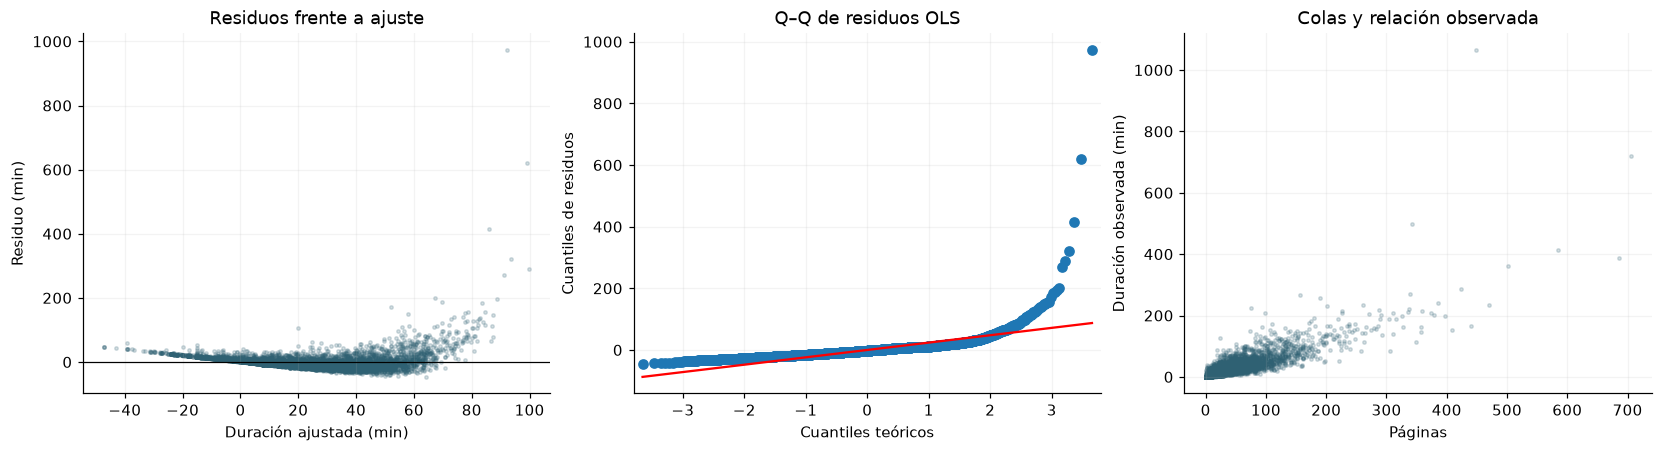

**Figura 1. Supuestos de imputación: heterocedasticidad y colas se examinan, no se presuponen ausentes.** Fuente: elaboración del grupo, datos UCI.

**Lectura:** Breusch–Pagan p=8.853e-19 y Jarque–Bera p=menor que la resolución numérica. Si son pequeños, los IC clásicos OLS no tienen sus supuestos plenamente respaldados. La regresión se usa como imputador determinista y se evalúa fuera del ajuste; no se afirma normalidad, homocedasticidad ni incertidumbre completa de imputación. Correlación alta entre predictores puede volver frágiles sus coeficientes individuales.

**Tabla 7. Referencia OLS: IC clásicos frente a HC3; coeficientes idénticos**

,predictor,coef_min,clasico_inf,clasico_sup,HC3_inf,HC3_sup
0,const,"-55,1737","-57,6327","-52,7148","-60,9140","-49,4334"
1,log1p_paginas,"23,0216","22,3939","23,6493","21,3086","24,7345"
2,rebote_pp,"-0,8687","-1,1420","-0,5953","-1,1093","-0,6280"
3,salida_pp,"2,4257","2,1217","2,7298","2,0153","2,8361"


In [4]:
def matriz_imputacion(x):
 a=pd.DataFrame({'log1p_paginas':np.log1p(x.ProductRelated),
                  'rebote_pp':100*x.BounceRates,'salida_pp':100*x.ExitRates},index=x.index)
 return sm.add_constant(a,has_constant='add')
def aprender_preparacion(x,metodo,variante=None):
 obs=x[TARGET].notna()
 p={'metodo':metodo,'mediana_seg':float(x.loc[obs,TARGET].median()),'n_ajuste':int(obs.sum())}
 if metodo=='Regresión':
  p['variante']=variante or globals().get('VARIANTE_REG','OLS_minutos')
  respuesta=x.loc[obs,TARGET]/60.
  if p['variante']=='Log_smearing':respuesta=np.log1p(respuesta)
  p['ols']=sm.OLS(respuesta,matriz_imputacion(x.loc[obs])).fit()
  p['smearing']=float(np.mean(np.exp(p['ols'].resid))) if p['variante']=='Log_smearing' else 1.
 return p
def prediccion_regresion(x,p):
 eta=np.asarray(p['ols'].predict(matriz_imputacion(x)))
 bruto=np.exp(eta)*p['smearing']-1 if p['variante']=='Log_smearing' else eta
 assert np.isfinite(bruto).all()
 return bruto, np.maximum(bruto,0.)

def completar(x,p):
 a=x.copy()
 if p['metodo']=='Eliminación':return a.loc[a[TARGET].notna()].copy()
 m=a[TARGET].isna()
 if p['metodo']=='Mediana':a.loc[m,TARGET]=p['mediana_seg']
 elif m.any():a.loc[m,TARGET]=prediccion_regresion(a.loc[m],p)[1]*60.
 return a
def numericas_transformadas(x):
 return pd.DataFrame({'ProductRelated':np.log1p(x.ProductRelated),
 TARGET:np.log1p(x[TARGET]/60.),'BounceRates':100*x.BounceRates,'ExitRates':100*x.ExitRates},index=x.index)
def aprender_escala(x):
 a=numericas_transformadas(x)
 return {'media':a.mean(),'DE':a.std(ddof=0).replace(0,1.)}
def diseno(x,escala,grupos,forma='Lineal'):
 a=numericas_transformadas(x);a=(a-escala['media'])/escala['DE']
 a['VisitorType_New_Visitor']=(x.VisitorType=='New_Visitor').astype(float)
 a['VisitorType_Other']=(x.VisitorType=='Other').astype(float)
 cols=[]
 for g in grupos:cols+=['VisitorType_New_Visitor','VisitorType_Other'] if g=='VisitorType' else [g]
 a=a[cols].copy()
 if forma=='Cuadrática':
  for g in grupos:
   if g in NUM:a[g+'_cuadrado']=a[g]**2
 return sm.add_constant(a,has_constant='add').astype(float)
def pesos_clase(yy):
 counts=np.bincount(np.asarray(yy,dtype=int),minlength=2)
 return {0:len(yy)/(2*counts[0]),1:len(yy)/(2*counts[1])}
def ajustar(yy,z,pesos=None):
 w=np.ones(len(yy)) if pesos is None else np.array([pesos[int(t)] for t in yy])
 with warnings.catch_warnings():
  warnings.simplefilter('error',sm.tools.sm_exceptions.PerfectSeparationWarning)
  fit=sm.GLM(np.asarray(yy),z,family=sm.families.Binomial(),var_weights=w).fit(maxiter=150,tol=1e-9)
 assert fit.converged and np.isfinite(fit.params).all()
 return fit
def ic_wald(fit,z,yy,pesos=None):
 # Para clasificación ponderada: sandwich HC0, no tratar pesos de clase como conteos.
 if pesos is None:cov=np.asarray(fit.cov_params())
 else:
  m=np.asarray(z);pp=np.clip(fit.predict(z),1e-10,1-1e-10)
  w=np.array([pesos[int(t)] for t in yy]);inv=np.linalg.inv(m.T@((w*pp*(1-pp))[:,None]*m))
  scores=m*(w*(np.asarray(yy)-pp))[:,None]
  cov=inv@(scores.T@scores)@inv
 se=np.sqrt(np.diag(cov));b=np.asarray(fit.params);q=stats.norm.ppf(.975)
 return b-q*se,b+q*se,se,cov

prep_reg=aprender_preparacion(Xtr,'Regresión','OLS_minutos');ols=prep_reg['ols']
obs=Xtr[TARGET].notna()
bp=het_breuschpagan(ols.resid,ols.model.exog)
jb=stats.jarque_bera(ols.resid)
tabla(pd.DataFrame({'predictor':ols.params.index,'coef_min':ols.params.values,
 'IC95_inf':ols.conf_int()[0].values,'IC95_sup':ols.conf_int()[1].values,'p':ols.pvalues.values}),
 'OLS para imputación: respuesta duración en minutos; intervalos clásicos condicionados a sus supuestos')
tabla(pd.DataFrame([{'n_observados_train':int(obs.sum()),'R2_ajuste':ols.rsquared,
 'RMSE_ajuste_min':np.sqrt(np.mean(ols.resid**2)), 'p_Breusch_Pagan':bp[1],'p_Jarque_Bera':float(jb.pvalue),
 'VIF_max_imputacion':max(variance_inflation_factor(ols.model.exog,j) for j in range(1,4))}]),
 'Diagnóstico OLS: ajuste interno no equivale a error fuera de muestra')
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
axes[0].scatter(ols.fittedvalues,ols.resid,s=5,alpha=.2,color=COLORES[0]);axes[0].axhline(0,color='black',lw=.8)
axes[0].set(xlabel='Duración ajustada (min)',ylabel='Residuo (min)',title='Residuos frente a ajuste')
sm.qqplot(ols.resid,line='s',ax=axes[1]);axes[1].set(title='Q–Q de residuos OLS',xlabel='Cuantiles teóricos',ylabel='Cuantiles de residuos')
axes[2].scatter(Xtr.loc[obs,'ProductRelated'],Xtr.loc[obs,TARGET]/60.,s=5,alpha=.2,color=COLORES[0])
axes[2].set(xlabel='Páginas',ylabel='Duración observada (min)',title='Colas y relación observada')
figura('Supuestos de imputación: heterocedasticidad y colas se examinan, no se presuponen ausentes.')
display(Markdown('**Lectura:** Breusch–Pagan p='+f'{bp[1]:.3e}'+' y Jarque–Bera p='+('menor que la resolución numérica' if jb.pvalue==0 else f'{jb.pvalue:.3e}')+
 '. Si son pequeños, los IC clásicos OLS no tienen sus supuestos plenamente respaldados. '+
 'La regresión se usa como imputador determinista y se evalúa fuera del ajuste; no se afirma normalidad, '+
 'homocedasticidad ni incertidumbre completa de imputación. Correlación alta entre predictores puede volver frágiles sus coeficientes individuales.'))
# HC3 no altera el ajuste: comparar su incertidumbre con la clásica.
hc3=ols.get_robustcov_results(cov_type='HC3')
tabla_hc3=pd.DataFrame({'predictor':ols.params.index,'coef_min':ols.params.values,
 'clasico_inf':ols.conf_int()[0].values,'clasico_sup':ols.conf_int()[1].values,
 'HC3_inf':hc3.conf_int()[:,0],'HC3_sup':hc3.conf_int()[:,1]})
tabla(tabla_hc3,'Referencia OLS: IC clásicos frente a HC3; coeficientes idénticos')

def transformar_coeficientes(beta,cov,columnas,escala_origen,escala_ref):
 # z_origen = a*z_ref + d. Incluye el término lineal inducido por cada cuadrado.
 T=np.eye(len(columnas));pos={c:j for j,c in enumerate(columnas)}
 for c in NUM:
  if c not in pos:continue
  j=pos[c];a=escala_ref['DE'][c]/escala_origen['DE'][c]
  d=(escala_ref['media'][c]-escala_origen['media'][c])/escala_origen['DE'][c]
  T[j,j]=a;T[0,j]=d
  if c+'_cuadrado' in pos:
   k=pos[c+'_cuadrado'];T[k,k]=a*a;T[j,k]=2*a*d;T[0,k]=d*d
 br=T@np.asarray(beta)
 return br, None if cov is None else T@np.asarray(cov)@T.T

def contrastes_OR(columnas):
 # OR numérico de z=0 a z=1, demás variables constantes; válido también con cuadrados.
 salida=[]
 for j,c in enumerate(columnas):
  if c=='const' or c.endswith('_cuadrado'):continue
  v=np.zeros(len(columnas));v[j]=1.
  if c+'_cuadrado' in columnas:v[list(columnas).index(c+'_cuadrado')]=1.
  cambio='de media a +1 DE en escala transformada' if c in NUM else 'frente a Returning_Visitor'
  salida.append((c,cambio,v))
 return salida


## 3. Elección del imputador dentro del entrenamiento

En cinco folds estratificados se ajusta cada imputador con los valores observados del
subentrenamiento y se evalúa sobre valores ocultados del fold de validación. Las verdades
ocultas sirven para medir error, nunca como respuesta de ajuste del imputador.

Se comparan mediana, OLS en minutos y log + smearing, siempre con la misma máscara.
La regla es menor MAE medio; RMSE resuelve un empate. Se documentan también sesgo,
negativos antes de limitar, ceros introducidos, cuantiles y correlación páginas–duración.
Eliminación no reconstruye valores y por eso se compara posteriormente en cobertura y
desempeño, no mediante un MAE inexistente.

La estrategia de imputación se selecciona con todo el entrenamiento y luego se mantiene
para comparar clasificadores. Los parámetros del imputador y del escalado se reajustan
dentro de cada fold. La elección de la estrategia no está completamente anidada en esa
segunda validación: sus métricas internas son de selección, no una estimación insesgada
del rendimiento de todo el procedimiento.


**Tabla 8. Comparación interna: error y predicciones imposibles antes de aplicar límite cero**

,estrategia,MAE_min,RMSE_min,error_medio_min,negativos_antes_limite,n_evaluados
0,Log_smearing,"8,1574","14,4519","1,0992",3,854
1,Mediana,"15,9638","30,3822","-9,7000",0,854
2,OLS_minutos,"10,6463","18,9365","1,7735",167,854


**Decisión interna:** Regresión; variante de regresión **Log_smearing**. Todos los errores están en minutos y se calculan después del límite físico.

**Tabla 9. Auditoría física en 854 celdas ocultas de train; originales observados sin cambios**

,variante,n_imputadas,negativas_antes_limite,porcentaje_activacion_limite,negativas_finales,ceros_imputados,minimo_bruto_min,media_final_min,mediana_final_min,p95_final_min,rho_paginas_duracion,smearing
0,OLS_minutos,854,167,"19,5550",0,167,"-47,0880","19,8008","10,4041","67,8878","0,8851","1,0000"
1,Log_smearing,854,3,"0,3513",0,3,"-0,2412","19,7343","10,0181","70,2243","0,8912","1,1914"


...

**Tabla 11. Regresión retenida: IC clásicos/HC3; log1p(minutos) si se eligió Log_smearing**

,predictor,coef_respuesta_transformada,clasico_inf,clasico_sup,HC3_inf,HC3_sup
0,const,"-0,4017","-0,4582","-0,3452","-0,4608","-0,3426"
1,log1p_paginas,"0,9611","0,9467","0,9755","0,9468","0,9754"
2,rebote_pp,"-0,0127","-0,0190","-0,0065","-0,0191","-0,0064"
3,salida_pp,"-0,0074","-0,0144","-0,0004","-0,0150","0,0002"


**Tabla 12. Supuestos de ambos ajustes; R2 en respuestas diferentes no es una comparación directa**

,modelo,respuesta,R2_en_su_escala,p_Breusch_Pagan,p_Jarque_Bera
0,Referencia OLS,minutos,"0,4436",8.853e-19,≈0 (límite numérico)
1,Regresión retenida,log1p(minutos),"0,8086",2.657e-25,1.873e-224


**Límite de la mejora:** transformar no demuestra normalidad ni homocedasticidad. La elección se sustenta en errores internos en minutos y restricciones físicas, no en comparar R2 de escalas distintas. HC3 protege la inferencia de coeficientes bajo sus condiciones; la imputación sigue siendo determinista y no reconstruye toda la variabilidad.

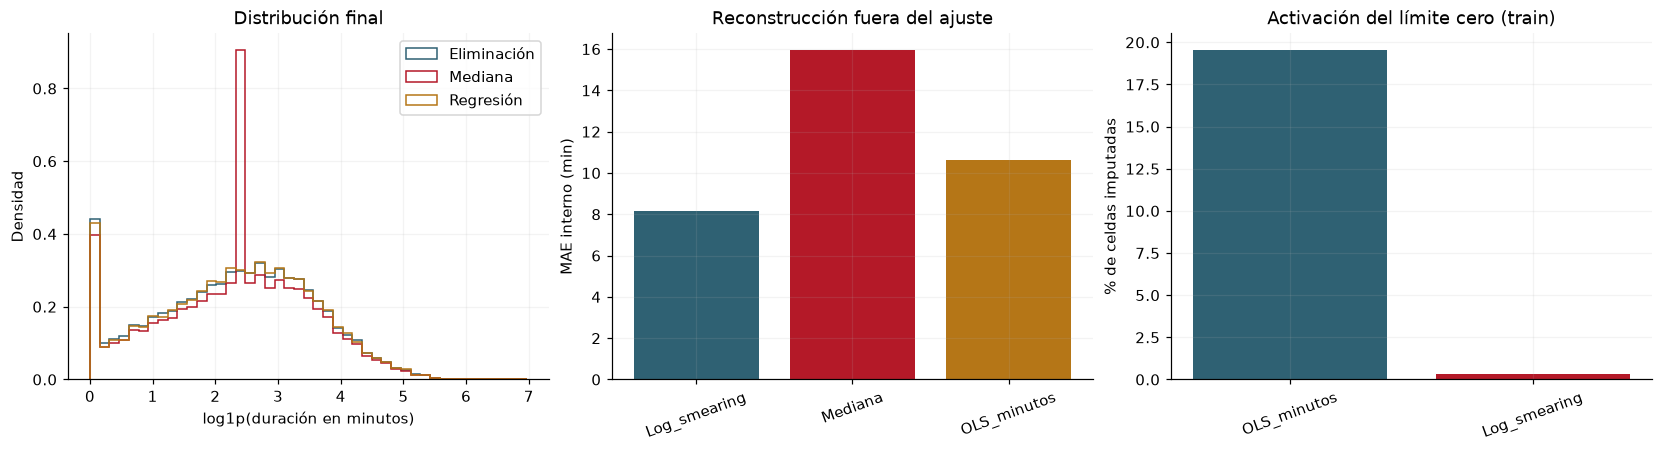

**Figura 2. Una alternativa debe reducir error y respetar el dominio; la imputación determinista aún puede reducir dispersión.** Fuente: elaboración del grupo, datos UCI.

In [5]:
cv_splits=list(StratifiedKFold(FOLDS,shuffle=True,random_state=SEED).split(Xtr,ytr))
errores_imput=[]
for fold,(a,b) in enumerate(cv_splits,1):
 xa,xb=Xtr.iloc[a],Xtr.iloc[b]
 ids=xb.index[xb[TARGET].isna()];truth=original.loc[ids,TARGET].to_numpy()/60.
 for nombre,metodo,variante in [('Mediana','Mediana',None),('OLS_minutos','Regresión','OLS_minutos'),
                                ('Log_smearing','Regresión','Log_smearing')]:
  pp=aprender_preparacion(xa,metodo,variante)
  pred=completar(xb,pp).loc[ids,TARGET].to_numpy()/60.
  neg=int((prediccion_regresion(xb.loc[ids],pp)[0]<0).sum()) if metodo=='Regresión' else 0
  errores_imput.append({'fold':fold,'estrategia':nombre,'n_evaluados':len(ids),
   'MAE_min':mean_absolute_error(truth,pred),'RMSE_min':np.sqrt(mean_squared_error(truth,pred)),
   'error_medio_min':float(np.mean(pred-truth)),'negativos_antes_limite':neg})
tabla_error_cv=pd.DataFrame(errores_imput)
resumen_imput=tabla_error_cv.groupby('estrategia').agg(MAE_min=('MAE_min','mean'),
 RMSE_min=('RMSE_min','mean'),error_medio_min=('error_medio_min','mean'),
 negativos_antes_limite=('negativos_antes_limite','sum'),n_evaluados=('n_evaluados','sum')).reset_index()
mejor_imput=str(resumen_imput.sort_values(['MAE_min','RMSE_min']).iloc[0].estrategia)
VARIANTE_REG=str(resumen_imput.loc[resumen_imput.estrategia!='Mediana'].sort_values(['MAE_min','RMSE_min']).iloc[0].estrategia)
ELEGIDA='Mediana' if mejor_imput=='Mediana' else 'Regresión'
tabla(resumen_imput,'Comparación interna: error y predicciones imposibles antes de aplicar límite cero')
display(Markdown('**Decisión interna:** '+ELEGIDA+'; variante de regresión **'+VARIANTE_REG+
 '**. Todos los errores están en minutos y se calculan después del límite físico.'))
PREPS={m:aprender_preparacion(Xtr,m) for m in METODOS}
DAT_TRAIN={m:completar(Xtr,PREPS[m]) for m in METODOS}

# Auditoría conjunta: misma cantidad de celdas ocultas y ambas variantes de regresión.
comparacion_reg=[];ids=Xtr.index[Xtr[TARGET].isna()]
for variante in ['OLS_minutos','Log_smearing']:
 pp=aprender_preparacion(Xtr,'Regresión',variante);bruto,acotado=prediccion_regresion(Xtr.loc[ids],pp)
 rec=completar(Xtr,pp);d=rec[TARGET]/60.
 comparacion_reg.append({'variante':variante,'n_imputadas':len(ids),
  'negativas_antes_limite':int((bruto<0).sum()),'porcentaje_activacion_limite':100*float(np.mean(bruto<0)),
  'negativas_finales':int((acotado<0).sum()),'ceros_imputados':int((acotado==0).sum()),
  'minimo_bruto_min':float(bruto.min()),'media_final_min':d.mean(),'mediana_final_min':d.median(),
  'p95_final_min':d.quantile(.95),'rho_paginas_duracion':rec[['ProductRelated',TARGET]].corr(method='spearman').iloc[0,1],
  'smearing':pp['smearing']})
tabla_comparacion_reg=pd.DataFrame(comparacion_reg)
tabla(tabla_comparacion_reg,'Auditoría física en 854 celdas ocultas de train; originales observados sin cambios')
comparacion_datos=[]
for metodo,a in DAT_TRAIN.items():
 dur=a[TARGET]/60.
 negativos=int((prediccion_regresion(Xtr.loc[ids],PREPS[metodo])[0]<0).sum()) if metodo=='Regresión' else 0
 comparacion_datos.append({'estrategia':metodo,'n_train':len(a),'perdidas':len(Xtr)-len(a),
 'imputadas_train':0 if metodo=='Eliminación' else len(ids),'media_duracion_min':dur.mean(),
 'mediana_min':dur.median(),'DE_min':dur.std(),'p95_min':dur.quantile(.95),
 'rho_paginas_duracion':a[['ProductRelated',TARGET]].corr(method='spearman').iloc[0,1],
 'rho_rebote_salida':a[['BounceRates','ExitRates']].corr(method='spearman').iloc[0,1],
 'predicciones_negativas_acotadas':negativos})
tabla_datos=pd.DataFrame(comparacion_datos)
tabla(tabla_datos,'Impacto en train: cobertura, distribución y correlaciones')
for m,a in DAT_TRAIN.items():
 assert (a[TARGET]>=0).all()
 observados=Xtr.index[Xtr[TARGET].notna()]
 assert np.array_equal(a.loc[observados,TARGET].to_numpy(),Xtr.loc[observados,TARGET].to_numpy())
ols_elegido=PREPS['Regresión']['ols'];hc3_elegido=ols_elegido.get_robustcov_results(cov_type='HC3')
tabla_hc3_elegido=pd.DataFrame({'predictor':ols_elegido.params.index,'coef_respuesta_transformada':ols_elegido.params.values,
 'clasico_inf':ols_elegido.conf_int()[0].values,'clasico_sup':ols_elegido.conf_int()[1].values,
 'HC3_inf':hc3_elegido.conf_int()[:,0],'HC3_sup':hc3_elegido.conf_int()[:,1]})
tabla(tabla_hc3_elegido,'Regresión retenida: IC clásicos/HC3; log1p(minutos) si se eligió Log_smearing')
diagnosticos_imput=[]
for nombre,fit,unidad in [('Referencia OLS',ols,'minutos'),('Regresión retenida',ols_elegido,
                         'log1p(minutos)' if VARIANTE_REG=='Log_smearing' else 'minutos')]:
 bp_fit=het_breuschpagan(fit.resid,fit.model.exog);jb_fit=stats.jarque_bera(fit.resid)
 diagnosticos_imput.append({'modelo':nombre,'respuesta':unidad,'R2_en_su_escala':fit.rsquared,
  'p_Breusch_Pagan':float(bp_fit[1]),'p_Jarque_Bera':float(jb_fit.pvalue)})
tabla_diagnosticos_imput=pd.DataFrame(diagnosticos_imput)
tabla(tabla_diagnosticos_imput,'Supuestos de ambos ajustes; R2 en respuestas diferentes no es una comparación directa')
display(Markdown('**Límite de la mejora:** transformar no demuestra normalidad ni homocedasticidad. '
 'La elección se sustenta en errores internos en minutos y restricciones físicas, no en comparar R2 '
 'de escalas distintas. HC3 protege la inferencia de coeficientes bajo sus condiciones; la imputación '
 'sigue siendo determinista y no reconstruye toda la variabilidad.'))

fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for j,(m,a) in enumerate(DAT_TRAIN.items()):
 axes[0].hist(np.log1p(a[TARGET]/60),bins=45,density=True,histtype='step',label=m,color=COLORES[j])
axes[0].set(xlabel='log1p(duración en minutos)',ylabel='Densidad',title='Distribución final');axes[0].legend()
axes[1].bar(resumen_imput.estrategia,resumen_imput.MAE_min,color=COLORES[:3])
axes[1].tick_params(axis='x',rotation=20);axes[1].set(ylabel='MAE interno (min)',title='Reconstrucción fuera del ajuste')
axes[2].bar(tabla_comparacion_reg.variante,tabla_comparacion_reg.porcentaje_activacion_limite,color=COLORES[:2])
axes[2].tick_params(axis='x',rotation=20);axes[2].set(ylabel='% de celdas imputadas',title='Activación del límite cero (train)')
figura('Una alternativa debe reducir error y respetar el dominio; la imputación determinista aún puede reducir dispersión.')


### 3.1. Retroalimentación docente: redundancia de rebote y salida en el imputador

El profesor advierte que incorporar ambas tasas puede elevar el VIF. Separamos dos usos:
el **clasificador** se interpreta y compara en la sección 4; aquí se revisa el **imputador de
duración**, cuya respuesta es distinta. El VIF se calcula sobre su propio diseño transformado
y sus casos completos de entrenamiento; no se copia el VIF del clasificador.

Se comparan como sensibilidad el imputador vigente de tres predictores, otro sin rebote y
otro sin salida. Se mantienen variante de respuesta, log1p(páginas), smearing, límite cero,
máscara y cinco folds. Los valores originales ocultados se usan solo para evaluar el error
en los folds de validación. No se usa prueba ni se modifican imputaciones posteriores.

**Alcance de la decisión:** las versiones de dos predictores son controles diagnósticos, no
un nuevo selector automático ni el imputador principal solicitado con 3–5 predictores.
El diseño principal se conserva por continuidad con la comparación anterior y porque su
evaluación predictiva se documenta; esto no demuestra que ambas tasas sean imprescindibles.
Si los errores son similares, se informa expresamente que existe una alternativa más simple.
La colinealidad limita la interpretación separada de coeficientes; HC3 no la elimina.
No se afirma que un requisito de cantidad de predictores resuelva esa limitación.


In [6]:
# Sensibilidad diagnóstica: no altera PREPS, DAT_TRAIN, ELEGIDA ni VARIANTE_REG.
disenos_sens_tasas={
 'Tres predictores (vigente)':['const','log1p_paginas','rebote_pp','salida_pp'],
 'Sin rebote (control de dos predictores)':['const','log1p_paginas','salida_pp'],
 'Sin salida (control de dos predictores)':['const','log1p_paginas','rebote_pp']}
filas_sens_imput=[];filas_vif_imput=[]
for nombre,columnas in disenos_sens_tasas.items():
 for fold,(ia,ib) in enumerate(cv_splits,1):
  xa,xb=Xtr.iloc[ia],Xtr.iloc[ib];observados=xa[TARGET].notna()
  ids=xb.index[xb[TARGET].isna()]
  respuesta=xa.loc[observados,TARGET]/60.
  if VARIANTE_REG=='Log_smearing':respuesta=np.log1p(respuesta)
  fit_sens=sm.OLS(respuesta,matriz_imputacion(xa.loc[observados])[columnas]).fit()
  eta=np.asarray(fit_sens.predict(matriz_imputacion(xb.loc[ids])[columnas]))
  bruto=np.exp(eta)*float(np.mean(np.exp(fit_sens.resid)))-1 if VARIANTE_REG=='Log_smearing' else eta
  pred=np.maximum(bruto,0.);verdad=original.loc[ids,TARGET].to_numpy()/60.
  filas_sens_imput.append({'diseno':nombre,'fold':fold,'n_evaluados':len(ids),
   'MAE_min':mean_absolute_error(verdad,pred),'RMSE_min':np.sqrt(mean_squared_error(verdad,pred)),
   'negativos_antes_limite':int(np.sum(bruto<0))})
 z=matriz_imputacion(Xtr.loc[Xtr[TARGET].notna()])[columnas]
 for j,c in enumerate(columnas):
  if c!='const':filas_vif_imput.append({'diseno':nombre,'predictor':c,
   'VIF':float(variance_inflation_factor(z.to_numpy(),j))})
tabla_sens_imput_folds=pd.DataFrame(filas_sens_imput);tabla_vif_imput_sens=pd.DataFrame(filas_vif_imput)
tabla_sens_imput=tabla_sens_imput_folds.groupby('diseno',sort=False).agg(
 MAE_min=('MAE_min','mean'),RMSE_min=('RMSE_min','mean'),n_evaluados=('n_evaluados','sum'),
 negativos_antes_limite=('negativos_antes_limite','sum')).reset_index()
tabla_sens_imput=tabla_sens_imput.merge(tabla_vif_imput_sens.groupby('diseno').VIF.max().rename('VIF_max'),on='diseno')
base_sens=tabla_sens_imput.loc[tabla_sens_imput.diseno=='Tres predictores (vigente)'].iloc[0]
tabla_sens_imput['cambio_MAE_frente_vigente']=tabla_sens_imput.MAE_min-base_sens.MAE_min
tabla_sens_imput['cambio_MAE_pct']=100*tabla_sens_imput.cambio_MAE_frente_vigente/base_sens.MAE_min
tabla(tabla_sens_imput,'Auditoría del imputador: error en validación interna y VIF del diseño completo de train')
tabla(tabla_vif_imput_sens,'VIF individual de predictores del imputador; diferente del VIF logístico')
sin_rebote=tabla_sens_imput.loc[tabla_sens_imput.diseno=='Sin rebote (control de dos predictores)'].iloc[0]
lectura_sens_imput=('Sin rebote, VIF máximo '+numero(sin_rebote.VIF_max,2)+' frente a '+numero(base_sens.VIF_max,2)+
 ' y MAE '+numero(sin_rebote.MAE_min,3)+' frente a '+numero(base_sens.MAE_min,3)+' min; cambio relativo '+
 numero(sin_rebote.cambio_MAE_pct,2)+' %. La diferencia de error es descriptiva, no una prueba de superioridad. '
 'El imputador vigente conserva tres predictores; su pequeña ventaja de error no demuestra que las dos tasas sean necesarias. '
 'La alternativa simplificada reduce colinealidad y merece consideración metodológica, pero aquí se documenta como control '
 'sin rehacer la selección ni trasladar IC entre diseños. No interpretar cada tasa como efecto independiente estable.')
display(Markdown('**Respuesta explícita a la observación:** '+lectura_sens_imput))


**Tabla 13. Auditoría del imputador: error en validación interna y VIF del diseño completo de train**

,diseno,MAE_min,RMSE_min,n_evaluados,negativos_antes_limite,VIF_max,cambio_MAE_frente_vigente,cambio_MAE_pct
0,Tres predictores (vigente),"8,1574","14,4519",854,3,"7,7653","0,0000","0,0000"
1,Sin rebote (control de dos predictores),"8,1725","14,4868",854,3,"1,6269","0,0151","0,1849"
2,Sin salida (control de dos predictores),"8,1614","14,4572",854,3,"1,3006","0,0041","0,0498"


**Tabla 14. VIF individual de predictores del imputador; diferente del VIF logístico**

,diseno,predictor,VIF
0,Tres predictores (vigente),log1p_paginas,"1,7425"
1,Tres predictores (vigente),rebote_pp,"6,2081"
2,Tres predictores (vigente),salida_pp,"7,7653"
3,Sin rebote (control de dos predictores),log1p_paginas,"1,6269"
4,Sin rebote (control de dos predictores),salida_pp,"1,6269"
5,Sin salida (control de dos predictores),log1p_paginas,"1,3006"
6,Sin salida (control de dos predictores),rebote_pp,"1,3006"


**Respuesta explícita a la observación:** Sin rebote, VIF máximo 1,63 frente a 7,77 y MAE 8,172 frente a 8,157 min; cambio relativo 0,18 %. La diferencia de error es descriptiva, no una prueba de superioridad. El imputador vigente conserva tres predictores; su pequeña ventaja de error no demuestra que las dos tasas sean necesarias. La alternativa simplificada reduce colinealidad y merece consideración metodológica, pero aquí se documenta como control sin rehacer la selección ni trasladar IC entre diseños. No interpretar cada tasa como efecto independiente estable.

## 4. Tres modelos logísticos con selección trazable

Se usan cinco grupos candidatos de S1/S2: páginas, duración, rebote, salida y VisitorType.
El tipo de visitante entra como un bloque de dos indicadores con recurrentes como referencia.
Se conserva la transformación de Formativa 2 y no se usan Revenue/PageValues como predictores.

- **M1 informado:** duración, salida y VisitorType, la referencia parsimoniosa de la formativa.
- **M2 stepwise AIC:** selección hacia adelante y atrás por bloques, empezando con intercepto,
  aceptando solo mejoras de AIC sobre la misma muestra.
- **M3 reducido BIC:** entre subconjuntos de hasta tres grupos y menos grupos que M2 cuando
  es posible, elegir el menor BIC. El límite de complejidad se fija antes de evaluar. Es el
  mejor BIC **dentro de ese conjunto reducido**, no necesariamente el mínimo global.

Así se atiende la consigna de criterios de información y la aclaración docente de un modelo
reducido. Criterios diferentes pueden coincidir en variables: se informa, no se fuerza diferencia.
AIC/BIC se calculan con ajustes **sin ponderación**, misma respuesta y mismas filas.
Se repite selección y preparación dentro de cada fold para evaluar honestamente el proceso.
La comparación interna usa AP con una regla explícita de parsimonia y no el desempeño del holdout.
Las tres especificaciones de esta sección son lineales; la ampliación cuadrática se compara en la sección 5.

**Retroalimentación de Formativa 2 (25 de octubre):** se completan los resúmenes de los
tres ajustes con valores p, errores estándar e IC. Se muestra qué tasa conserva cada
clasificador, en respuesta a la advertencia de no mantener rebote y salida redundantes
en el modelo final. El imputador se audita por separado en 3.1.


In [7]:
TRAZAS={}
def seleccionar(x,yy,tipo,escala,guardar=None):
 cache={}
 def fit(gs):
  key=tuple(g for g in GRUPOS if g in gs)
  if key not in cache:cache[key]=ajustar(yy,diseno(x,escala,list(key)))
  return cache[key]
 def bic(gs):
  f=fit(gs);return -2*f.llf+np.log(len(x))*len(f.params)
 if tipo=='M1_informado':elegidos=[TARGET,'ExitRates','VisitorType']
 elif tipo=='M2_stepwise_AIC':
  elegidos=[];pasos=[{'paso':0,'accion':'Inicio','grupos':'Intercepto','AIC':float(fit([]).aic)}]
  for paso in range(30):
   actual=float(fit(elegidos).aic);opciones=[]
   for g in GRUPOS:
    pro=[t for t in GRUPOS if t in ((set(elegidos)-{g}) if g in elegidos else (set(elegidos)|{g}))]
    opciones.append((float(fit(pro).aic),g,pro))
   mejor=min(opciones,key=lambda z:(z[0],z[1]))
   if mejor[0]>=actual-1e-7:break
   accion=('Quitar ' if mejor[1] in elegidos else 'Añadir ')+mejor[1]
   elegidos=mejor[2];pasos.append({'paso':paso+1,'accion':accion,'grupos':', '.join(elegidos),'AIC':mejor[0]})
  if guardar is not None:TRAZAS[guardar]=pasos
 elif tipo=='M3_reducido_BIC':
  base=seleccionar(x,yy,'M2_stepwise_AIC',escala)
  tope=max(1,min(3,len(base)-1));opciones=[]
  for k in range(1,tope+1):
   for gs in combinations(GRUPOS,k):opciones.append({'grupos':list(gs),'BIC':float(bic(gs)),'k_grupos':k})
  opciones.sort(key=lambda t:(t['BIC'],t['k_grupos']))
  elegidos=opciones[0]['grupos']
  if guardar is not None:TRAZAS[guardar]=opciones
 else:raise ValueError(tipo)
 return elegidos

XA=DAT_TRAIN[ELEGIDA];YA=ytr.loc[XA.index];ESCALA=aprender_escala(XA)
z_candidatos=diseno(XA,ESCALA,GRUPOS)
vif_previo=pd.DataFrame([{'predictor':z_candidatos.columns[j],
    'VIF':variance_inflation_factor(z_candidatos.to_numpy(),j)} for j in range(1,z_candidatos.shape[1])])
tabla(vif_previo,'VIF antes de selección: revisar los dos pares advertidos por el profesor')
SELECCIONES={t:seleccionar(XA,YA,t,ESCALA,guardar=t) for t in TIPOS}
AJUSTES={t:ajustar(YA,diseno(XA,ESCALA,gs)) for t,gs in SELECCIONES.items()}
vif_modelos=[];resumen_modelos=[];coef_todos=[]
for t,gs in SELECCIONES.items():
 z=diseno(XA,ESCALA,gs);f=AJUSTES[t]
 resumen_modelos.append({'modelo':t,'grupos':', '.join(gs),'parametros_incl_const':len(f.params),'n_train':len(z),'compras_train':int(YA.sum()),
    'log_verosimilitud':float(f.llf),'deviance':float(f.deviance),
    'convergio':bool(f.converged),'iteraciones':int(f.fit_history['iteration']),
    'AIC_sin_pesos':float(f.aic),'BIC_sin_pesos':float(-2*f.llf+np.log(len(z))*len(f.params))})
 for k in range(1,z.shape[1]):vif_modelos.append({'modelo':t,'predictor':z.columns[k],'VIF':variance_inflation_factor(z.to_numpy(),k)})
 lo,hi,se,cov=ic_wald(f,z,YA)
 for j,c in enumerate(z.columns):coef_todos.append({'modelo':t,'predictor':c,'coef':f.params.iloc[j],'error_estandar':se[j],'z':float(f.params.iloc[j]/se[j]),'p':float(f.pvalues.iloc[j]),
    'IC95_inf':lo[j],'IC95_sup':hi[j],'OR':np.exp(f.params.iloc[j]) if c!='const' else np.nan,'OR_inf':np.exp(lo[j]) if c!='const' else np.nan,'OR_sup':np.exp(hi[j]) if c!='const' else np.nan})
tabla_modelos=pd.DataFrame(resumen_modelos);tabla_vif=pd.DataFrame(vif_modelos);tabla_coef_modelos=pd.DataFrame(coef_todos)
tabla(tabla_modelos,'Tres criterios de construcción sobre entrenamiento e imputación elegida')
tabla(pd.DataFrame(TRAZAS['M2_stepwise_AIC']),'Trayectoria stepwise AIC por bloques')
tabla(pd.DataFrame(TRAZAS['M3_reducido_BIC']).head(8).assign(grupos=lambda d:d.grupos.map(', '.join)),
 'Alternativas reducidas ordenadas por BIC; conjunto restringido de candidatos')
tabla(tabla_vif,'VIF del diseño de cada modelo; referencias orientativas 5/10, sin eliminación automática')
tabla(tabla_coef_modelos,'Resumen de las tres logísticas sin pesos: beta, error estándar, z, p bilateral, IC95 y OR')
display(Markdown('**Unidades:** los OR numéricos corresponden a 1 DE de entrenamiento de '+
 'log1p(páginas), log1p(minutos), rebote o salida en pp, según variable. '+
 'Los indicadores comparan con Returning_Visitor. OR no es cambio directo de probabilidad; '+
 'un coeficiente condicional puede diferir de una asociación marginal de S1. No se interpreta como causal.'))
interpretaciones_OR=[]
for modelo in TIPOS:
    textos=[]
    for _,r in tabla_coef_modelos.loc[(tabla_coef_modelos.modelo==modelo)&(tabla_coef_modelos.predictor!='const')].iterrows():
        cambio=('1 DE de log1p(páginas)' if r.predictor=='ProductRelated' else
                '1 DE de log1p(duración en minutos)' if r.predictor==TARGET else
                '1 DE de tasa en pp' if r.predictor in ['BounceRates','ExitRates'] else
                r.predictor.replace('VisitorType_','')+' frente a recurrentes')
        lectura=f"{r.predictor}: por {cambio}, odds ×{numero(r.OR)} (IC95 % [{numero(r.OR_inf)}; {numero(r.OR_sup)}])"
        textos.append(lectura)
        interpretaciones_OR.append({'modelo':modelo,'predictor':r.predictor,'interpretacion':lectura,
            'alcance':'Ajuste sin pesos, demás predictores constantes; no causalidad ni cambio porcentual directo en probabilidad.'})
    display(Markdown('**'+modelo+' — interpretación de OR:** '+ '; '.join(textos)+'. Manteniendo constantes los demás predictores.'))
if SELECCIONES['M1_informado']==SELECCIONES['M3_reducido_BIC']:
    display(Markdown('**Coincidencia de criterios:** M1 y M3 retienen las mismas variables en el ajuste completo. '
        'Se mantienen sus procesos de construcción y validación distintos; no se inventa una diferencia de coeficientes.'))

display(Markdown('**Intercepto:** se conserva su coeficiente, pero no se presenta exp(intercepto) como OR. '
 'Esa exponencial representa odds basales para el perfil de referencia.'))

display(Markdown('**Valores p e IC:** los p bilaterales contrastan beta=0 con la aproximación normal '
 'del ajuste GLM sin pesos; se informa error estándar y z junto a IC95. Tras stepwise y comparación '
 'de modelos, son inferencias condicionadas y exploratorias, no p corregidos por selección o '
 'multiplicidad. No prueban causalidad, relevancia económica ni superioridad predictiva. '
 'Estos valores p no corresponden al L2 del grid search.'))
filas_respuesta_vif=[]
for nombre in TIPOS:
 tasas=[g for g in SELECCIONES[nombre] if g in ['BounceRates','ExitRates']]
 filas_respuesta_vif.append({'modelo':nombre,'tasas_retenidas':', '.join(tasas),
  'retiene_ambas_tasas':len(tasas)==2,'VIF_max':float(tabla_vif.loc[tabla_vif.modelo==nombre,'VIF'].max())})
tabla_respuesta_vif=pd.DataFrame(filas_respuesta_vif)
tabla(tabla_respuesta_vif,'Respuesta al profesor: tasas que retiene cada clasificador y su VIF máximo')
display(Markdown('**Sobre 1,63 y 8,56:** son diagnósticos del diseño evaluado en Formativa 2. '
 'En S3 se recalculan con los casos y transformaciones actuales; cambiar la imputación puede '
 'modificar el VIF. Se conservan los números reales de cada diseño. La selección de variables '
 'usa entrenamiento, no el VIF de prueba ni sus métricas. La auditoría separada del imputador '
 'está en 3.1; no se afirma que la redundancia haya desaparecido en todos los modelos.'))


**Tabla 15. VIF antes de selección: revisar los dos pares advertidos por el profesor**

,predictor,VIF
0,ProductRelated,"6,0702"
1,ProductRelated_Duration,"5,6618"
2,BounceRates,"6,4749"
3,ExitRates,"8,5616"
4,VisitorType_New_Visitor,"1,1569"
5,VisitorType_Other,"1,0116"


**Tabla 16. Tres criterios de construcción sobre entrenamiento e imputación elegida**

,modelo,grupos,parametros_incl_const,n_train,compras_train,log_verosimilitud,deviance,convergio,iteraciones,AIC_sin_pesos,BIC_sin_pesos
0,M1_informado,"ProductRelated_Duration, ExitRates, VisitorType",5,8631,1336,"-3.287,9312","6.575,8624",True,7,"6.585,8624","6.621,1780"
1,M2_stepwise_AIC,"ProductRelated, ProductRelated_Duration, ExitRates, VisitorType",6,8631,1336,"-3.286,4565","6.572,9129",True,7,"6.584,9129","6.627,2916"
2,M3_reducido_BIC,"ProductRelated_Duration, ExitRates, VisitorType",5,8631,1336,"-3.287,9312","6.575,8624",True,7,"6.585,8624","6.621,1780"


**Tabla 17. Trayectoria stepwise AIC por bloques**

...

**Intercepto:** se conserva su coeficiente, pero no se presenta exp(intercepto) como OR. Esa exponencial representa odds basales para el perfil de referencia.

**Valores p e IC:** los p bilaterales contrastan beta=0 con la aproximación normal del ajuste GLM sin pesos; se informa error estándar y z junto a IC95. Tras stepwise y comparación de modelos, son inferencias condicionadas y exploratorias, no p corregidos por selección o multiplicidad. No prueban causalidad, relevancia económica ni superioridad predictiva. Estos valores p no corresponden al L2 del grid search.

**Tabla 21. Respuesta al profesor: tasas que retiene cada clasificador y su VIF máximo**

,modelo,tasas_retenidas,retiene_ambas_tasas,VIF_max
0,M1_informado,ExitRates,False,"1,7523"
1,M2_stepwise_AIC,ExitRates,False,"5,8372"
2,M3_reducido_BIC,ExitRates,False,"1,7523"


**Sobre 1,63 y 8,56:** son diagnósticos del diseño evaluado en Formativa 2. En S3 se recalculan con los casos y transformaciones actuales; cambiar la imputación puede modificar el VIF. Se conservan los números reales de cada diseño. La selección de variables usa entrenamiento, no el VIF de prueba ni sus métricas. La auditoría separada del imputador está en 3.1; no se afirma que la redundancia haya desaparecido en todos los modelos.

## 5. Validación interna: curvatura, ponderación, parsimonia y umbral

Se mantienen los tres procedimientos de selección de variables de la sección 4. Para
cada uno se compara una forma lineal en el logit con una ampliación cuadrática de sus
predictores numéricos, conservando los términos lineales. No se añaden interacciones.
La selección de variables, imputación y escalado se reajustan dentro de cada fold.

**Regla de decisión de esta revisión, aplicada antes de la nueva evaluación de prueba:**
se calcula AP en cada uno de los cinco folds. Son candidatos los modelos cuya AP media
está a menos de un error estándar de la mejor media. Entre ellos se prefiere menor
cantidad media de parámetros, luego forma lineal, ausencia de pesos y procedimiento
informado M1; si persiste el empate, mayor AP media. Es una regla de parsimonia orientativa:
los folds se solapan en entrenamiento y el error estándar no es un IC ni demuestra
equivalencia. No se elige por diferencias microscópicas de AP ni por la prueba final.

Se evalúan explícitamente pesos balanceados calculados solo en cada entrenamiento
(`N/(2*n_clase)`), además de ausencia de pesos. La decisión final de ponderar sigue la misma
regla interna; no se presupone que ponderar mejore AP. Finalmente el umbral se elige
por F1 entre 0,05 y 0,80 en pasos de 0,01, sobre puntuaciones fuera de fold del ganador.
El umbral 0,5 se conserva como referencia. AP no depende de ese umbral.


Fold

1

completado; formas y pesos comparados

Fold

2

...

**Tabla 24. Variables retenidas por proceso: cantidad de folds con cada especificación; detalle en JSON**

,modelo,grupos,folds
0,M1_informado,"ProductRelated_Duration, ExitRates, VisitorType",5
1,M2_stepwise_AIC,"ProductRelated, ProductRelated_Duration, ExitRates, VisitorType",4
2,M2_stepwise_AIC,"ProductRelated_Duration, ExitRates, VisitorType",1
3,M3_reducido_BIC,"ProductRelated_Duration, ExitRates",1
4,M3_reducido_BIC,"ProductRelated_Duration, ExitRates, VisitorType",4


**Tabla 25. Ejemplos del barrido interno del ganador; se usa la rejilla completa declarada**

,modelo,ponderacion,forma,n,compras,umbral,accuracy,precision,recall,F1,ROC_AUC,AP,TN,FP,FN,TP
613,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,1000","0,4753","0,2168","0,9147","0,3505","0,7386","0,3031",2880,4415,114,1222
623,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,2000","0,6941","0,2814","0,6280","0,3886","0,7386","0,3031",5152,2143,497,839
633,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,3000","0,8151","0,3513","0,2298","0,2778","0,7386","0,3031",6728,567,1029,307
643,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,4000","0,8421","0,3636","0,0269","0,0502","0,7386","0,3031",7232,63,1300,36
653,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,5000","0,8449","0,2000","0,0007","0,0015","0,7386","0,3031",7291,4,1335,1
663,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,6000","0,8452","0,0000","0,0000","0,0000","0,7386","0,3031",7295,0,1336,0
673,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,7000","0,8452","0,0000","0,0000","0,0000","0,7386","0,3031",7295,0,1336,0
683,M3_reducido_BIC,Sin pesos,Lineal,8631,1336,"0,8000","0,8452","0,0000","0,0000","0,0000","0,7386","0,3031",7295,0,1336,0


**Decisión interna:** M3_reducido_BIC, forma **Lineal**, Sin pesos, umbral **0,20**. Límite AP de la regla 1SE: 0,3025. Esta tolerancia favorece una especificación simple cuando su AP es cercana a la mejor; no es una prueba estadística.

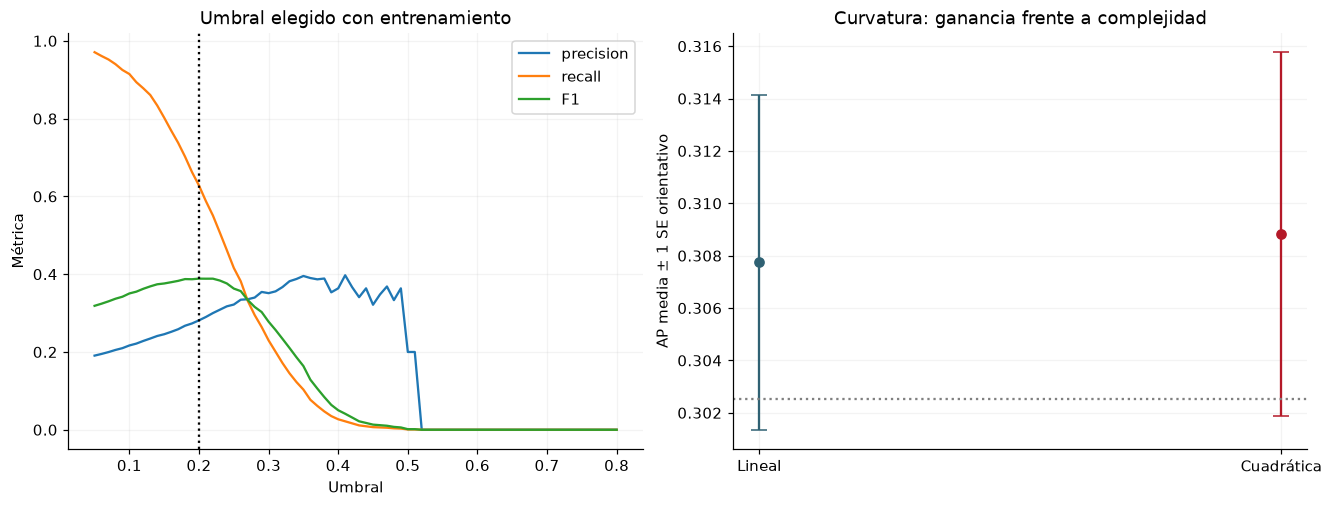

**Figura 3. Curvatura evaluada internamente y umbral elegido; barras orientativas, no IC.** Fuente: elaboración del grupo, datos UCI.

**Coincidencia de especificaciones:** si M1 y M3 retienen las mismas variables al ajustar todo el entrenamiento, sus coeficientes y predicciones coinciden. La preferencia por M3 puede deberse a menos parámetros medios durante validación; se compara el procedimiento y no se afirma que dos ajustes finales idénticos sean modelos predictivos distintos.

In [8]:
FORMAS=['Lineal','Cuadrática']
OOF={(t,p,f):np.full(len(Xtr),np.nan) for t in TIPOS for p in ['Sin pesos','Balanceado'] for f in FORMAS}
selecciones_folds=[];metricas_folds=[]
for fold,(ia,ib) in enumerate(cv_splits,1):
 xa,xb=Xtr.iloc[ia],Xtr.iloc[ib];ya=ytr.iloc[ia]
 pp=aprender_preparacion(xa,ELEGIDA);aa=completar(xa,pp);bb=completar(xb,pp)
 es=aprender_escala(aa);pes=pesos_clase(ya.loc[aa.index])
 for t in TIPOS:
  gs=seleccionar(aa,ya.loc[aa.index],t,es)
  selecciones_folds.append({'fold':fold,'modelo':t,'grupos':', '.join(gs)})
  for forma in FORMAS:
   za=diseno(aa,es,gs,forma);zb=diseno(bb,es,gs,forma)
   for nombre,w in [('Sin pesos',None),('Balanceado',pes)]:
    fit=ajustar(ya.loc[aa.index],za,w);probs=np.asarray(fit.predict(zb))
    posiciones=Xtr.index.get_indexer(bb.index);OOF[t,nombre,forma][posiciones]=probs
    metricas_folds.append({'fold':fold,'modelo':t,'ponderacion':nombre,'forma':forma,
      'parametros':za.shape[1],**metricas(ytr.loc[bb.index],probs)})
 print('Fold',fold,'completado; formas y pesos comparados',flush=True)
tabla_folds=pd.DataFrame(metricas_folds)
resumen_cv=tabla_folds.groupby(['modelo','ponderacion','forma']).agg(AP_media=('AP','mean'),
 AP_DE=('AP','std'),ROC_AUC_media=('ROC_AUC','mean'),parametros_medios=('parametros','mean')).reset_index()
resumen_cv['AP_SE_orientativo']=resumen_cv.AP_DE/np.sqrt(FOLDS)
mejor=resumen_cv.sort_values('AP_media',ascending=False).iloc[0]
LIMITE_AP=float(mejor.AP_media-mejor.AP_SE_orientativo)
resumen_cv['candidato_1SE']=resumen_cv.AP_media>=LIMITE_AP
ranking=resumen_cv.loc[resumen_cv.candidato_1SE].assign(
 preferencia_forma=lambda d:d.forma.map({'Lineal':0,'Cuadrática':1}),
 preferencia_pesos=lambda d:d.ponderacion.map({'Sin pesos':0,'Balanceado':1}),
 preferencia_modelo=lambda d:d.modelo.map({'M1_informado':0,'M3_reducido_BIC':1,'M2_stepwise_AIC':2})
 ).sort_values(['parametros_medios','preferencia_forma','preferencia_pesos','preferencia_modelo','AP_media'],
 ascending=[True,True,True,True,False])
GANADOR=str(ranking.iloc[0].modelo);PONDERACION=str(ranking.iloc[0].ponderacion);FORMA=str(ranking.iloc[0].forma)
filas_oof=[];filas_umbrales=[]
for (t,p,f),probs in OOF.items():
 assert np.isfinite(probs).all()
 filas_oof.append({'modelo':t,'ponderacion':p,'forma':f,**metricas(ytr,probs)})
 for u in np.round(np.arange(.05,.801,.01),2):
  filas_umbrales.append({'modelo':t,'ponderacion':p,'forma':f,**metricas(ytr,probs,float(u))})
tabla_oof=pd.DataFrame(filas_oof);tabla_umbrales=pd.DataFrame(filas_umbrales)
umbrales_final=tabla_umbrales.loc[(tabla_umbrales.modelo==GANADOR)&(tabla_umbrales.ponderacion==PONDERACION)&(tabla_umbrales.forma==FORMA)]
UMBRAL=float(umbrales_final.sort_values(['F1','umbral'],ascending=[False,False]).iloc[0].umbral)
PESOS=pesos_clase(YA) if PONDERACION=='Balanceado' else None
tabla(resumen_cv,'AP por fold y regla de parsimonia: comparación lineal/cuadrática y ponderación')
tabla(tabla_oof,'Puntuaciones OOF agregadas y métricas al umbral común 0,5; no confundir con AP media por fold')
resumen_selecciones_folds=pd.DataFrame(selecciones_folds).groupby(['modelo','grupos']).size().reset_index(name='folds')
tabla(resumen_selecciones_folds,'Variables retenidas por proceso: cantidad de folds con cada especificación; detalle en JSON')
tabla(umbrales_final.loc[umbrales_final.umbral.isin([.1,.2,.3,.4,.5,.6,.7,.8])],
 'Ejemplos del barrido interno del ganador; se usa la rejilla completa declarada')
display(Markdown('**Decisión interna:** '+GANADOR+', forma **'+FORMA+'**, '+PONDERACION+
 ', umbral **'+numero(UMBRAL,2)+'**. Límite AP de la regla 1SE: '+numero(LIMITE_AP,4)+
 '. Esta tolerancia favorece una especificación simple cuando su AP es cercana a la mejor; no es una prueba estadística.'))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for met in ['precision','recall','F1']:axes[0].plot(umbrales_final.umbral,umbrales_final[met],label=met)
axes[0].axvline(UMBRAL,color='black',ls=':');axes[0].set(xlabel='Umbral',ylabel='Métrica',title='Umbral elegido con entrenamiento');axes[0].legend()
for j,forma in enumerate(FORMAS):
 d=resumen_cv.loc[(resumen_cv.modelo==GANADOR)&(resumen_cv.ponderacion==PONDERACION)&(resumen_cv.forma==forma)].iloc[0]
 axes[1].errorbar(j,d.AP_media,yerr=d.AP_SE_orientativo,fmt='o',color=COLORES[j],capsize=5)
axes[1].axhline(LIMITE_AP,color='grey',ls=':');axes[1].set(xticks=[0,1],xticklabels=FORMAS,
 ylabel='AP media ± 1 SE orientativo',title='Curvatura: ganancia frente a complejidad')
figura('Curvatura evaluada internamente y umbral elegido; barras orientativas, no IC.')

display(Markdown('**Coincidencia de especificaciones:** si M1 y M3 retienen las mismas variables al '
 'ajustar todo el entrenamiento, sus coeficientes y predicciones coinciden. La preferencia por M3 '
 'puede deberse a menos parámetros medios durante validación; se compara el procedimiento y no '
 'se afirma que dos ajustes finales idénticos sean modelos predictivos distintos.'))


## 5.1. Grid search: reducir falsas alarmas con recall mínimo del 50 %

**Objetivo acordado:** minimizar falsos positivos (FP), sujeto a **recall ≥ 0,50** en
predicciones fuera de fold del entrenamiento. El 50 % es una restricción de trabajo
acordada para esta exploración, no un estándar estadístico ni un costo comercial estimado.
Sin esta restricción, anunciar siempre «sin compra» tendría cero falsas alarmas y cero utilidad
para detectar compradores. No se cambia el objetivo después de mirar prueba.

**Refinamiento:** una exploración inicial motivó acercar umbrales y pesos, y ampliar la
penalización hacia valores más fuertes. Esta rejilla reemplaza la anterior; se conserva
una sola búsqueda visible. Los nuevos rangos y la regla se fijan antes de evaluarla en
prueba. La selección es adaptativa a la exploración interna previa, no una validación externa.

Se estudian **27 combinaciones = 3 umbrales × 3 pesos × 3 valores de C**:

| Parámetro | Valores de la rejilla | Interpretación |
|---|---|---|
| Umbral | 0,20; 0,225; 0,25 | Puntuación mínima para anunciar compra |
| Peso relativo de compra | 0,75; 1; 1,25 | Peso de «sin compra» fijado en 1 |
| C | 0,01; 0,03; 0,1 | Inversa de penalización L2: menor C, mayor penalización |

Se usa `LogisticRegression` de scikit-learn con L2 (`l1_ratio=0`), intercepto no penalizado,
solver lbfgs y las variables/forma de la especificación de referencia de la sección 5.
Las variables numéricas siguen estandarizadas; las categorías conservan su codificación.
Los pesos relativos no son los pesos absolutos de la opción balanceada anterior.

**Procedimiento:** se recorre una rejilla exhaustiva con `ParameterGrid`. Cada combinación
de peso y C se entrena en los mismos cinco folds estratificados; imputación y escalado se
aprenden solo en su subentrenamiento. Los tres umbrales reutilizan sus puntuaciones de
validación: son **45 ajustes y 135 evaluaciones de fold**, que se reúnen en 27 resultados OOF.
El objetivo se aplica a las predicciones OOF reunidas, no a un promedio de cocientes por fold.
En empates de FP: mayor recall, mayor F1, menor C, peso más cercano a 1 y mayor umbral.

El conjunto de variables, la forma y el método de imputación ya se eligieron con todo el
entrenamiento. Esta búsqueda está **condicionada a esas decisiones** y no es una validación
anidada de todo el proceso. Su puntuación interna sirve para elegir, no demuestra desempeño
externo. La prueba ya fue explorada en fases anteriores y se conserva esa limitación.

**Separación de resultados:** esta es una alternativa predictiva regularizada. No reemplaza
los tres modelos de la rúbrica ni sus IC clásicos/bootstrap. Los IC del modelo sin penalización
no se trasladan al modelo L2. PageValues sigue excluida.


Grid search: fold

1

/ 5; 9 ajustes L2 y 27 evaluaciones

Grid search: fold

2

...

,rango,peso_compra,C,umbral,FP,TP,recall,precision,F1,ROC_AUC,AP,cumple_recall_minimo
0,1,"1,0000","0,1000","0,2250",1541,678,"0,5075","0,3055","0,3814","0,7381","0,3043",True
1,2,"1,2500","0,0100","0,2500",1655,694,"0,5195","0,2954","0,3767","0,7355","0,3007",True
2,3,"1,2500","0,0300","0,2500",1776,741,"0,5546","0,2944","0,3846","0,7375","0,3036",True
3,4,"1,2500","0,1000","0,2500",1845,758,"0,5674","0,2912","0,3849","0,7381","0,3043",True
4,5,"1,0000","0,0100","0,2000",1894,768,"0,5749","0,2885","0,3842","0,7348","0,2997",True
5,6,"1,0000","0,0300","0,2000",2017,799,"0,5981","0,2837","0,3849","0,7374","0,3033",True
6,7,"1,0000","0,1000","0,2000",2076,816,"0,6108","0,2822","0,3860","0,7381","0,3043",True
7,8,"1,2500","0,0100","0,2250",2278,856,"0,6407","0,2731","0,3830","0,7355","0,3007",True
8,9,"1,2500","0,0300","0,2250",2323,868,"0,6497","0,2720","0,3835","0,7375","0,3036",True
9,10,"1,2500","0,1000","0,2250",2328,873,"0,6534","0,2727","0,3848","0,7381","0,3043",True


**MEJOR COMBINACIÓN DENTRO DE ESTA REJILLA:** umbral **0,225**, pesos **{sin compra: 1; compra: 1,000}**, **C=0,100** (L2). En validación OOF: **1541 falsas alarmas**, recall **50,75 %** y precision **30,55 %**. Es la mejor por el objetivo declarado entre 27 opciones; no una superioridad estadística demostrada.

**Tabla 27. Comparación interna justa: misma especificación fija en todos los folds; distinta de selección repetida de sección 5**

,configuracion,umbral,TP,FP,recall,precision,F1,ROC_AUC,AP
0,Referencia sin penalización; misma especificación,"0,2000",824,2099,"0,6168","0,2819","0,3869","0,7383","0,3048"
1,L2 elegido por grid search,"0,2250",678,1541,"0,5075","0,3055","0,3814","0,7381","0,3043"


**Cambio interno de FP frente a referencia:** -558. Un valor positivo significa más falsas alarmas. La mejor opción de la rejilla puede no mejorar la referencia.

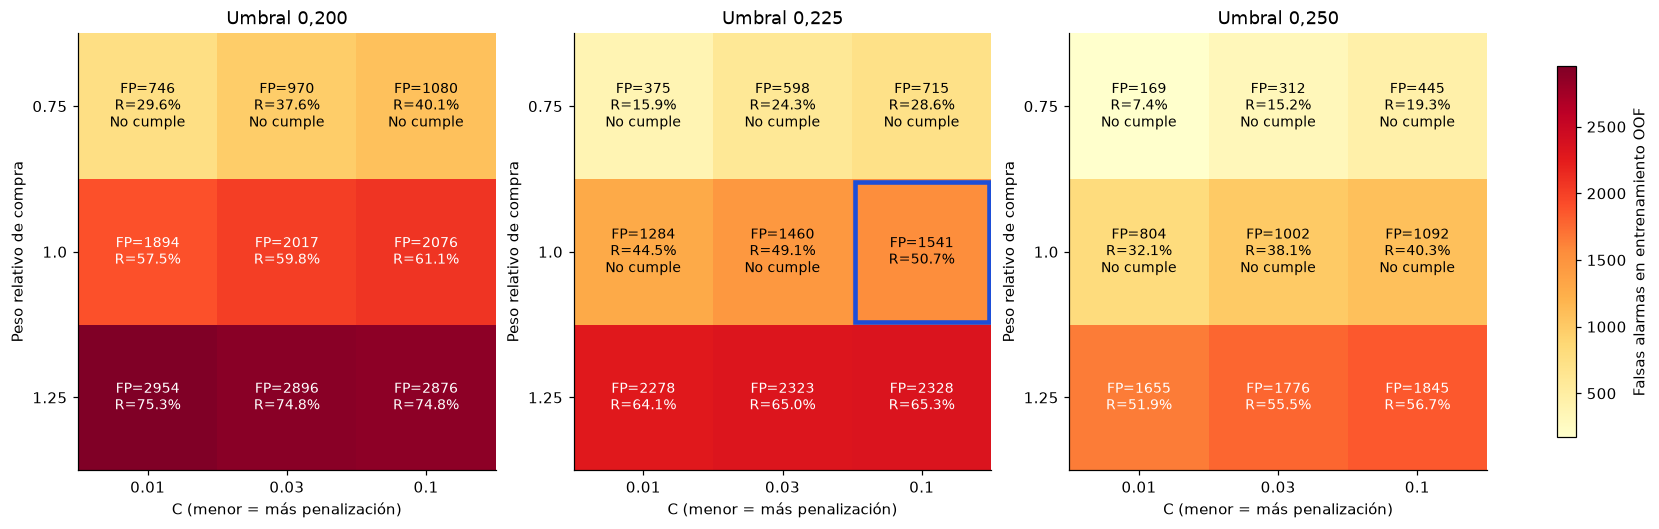

**Figura 4. Tres matrices 3×3: FP y recall (R) por combinación; borde azul = elección interna. Celdas «No cumple» no son elegibles.** Fuente: elaboración del grupo, datos UCI.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.exceptions import ConvergenceWarning

GRID_UMBRALES=[.20,.225,.25]
GRID_PESOS=[.75,1.,1.25]
GRID_C=[.01,.03,.1]
GRID_RECALL_MIN=.50
GRID_GRUPOS=list(SELECCIONES[GANADOR]);GRID_FORMA=FORMA
assert {'PageValues','Revenue'}.isdisjoint(GRID_GRUPOS)
grid_parametros=list(ParameterGrid({'peso_compra':GRID_PESOS,'C':GRID_C}))
GRID_OOF={(float(p['peso_compra']),float(p['C'])):np.full(len(Xtr),np.nan) for p in grid_parametros}
grid_referencia_oof=np.full(len(Xtr),np.nan)
grid_folds=[];grid_convergencia=[]

def ajustar_grid(za,yy,peso_compra,C):
 # scikit-learn 1.9: l1_ratio=0 especifica L2 sin el argumento penalty deprecado.
 modelo=LogisticRegression(C=float(C),l1_ratio=0.,solver='lbfgs',fit_intercept=True,
  class_weight={0:1.,1:float(peso_compra)},max_iter=2000,tol=1e-8,random_state=SEED)
 with warnings.catch_warnings():
  warnings.simplefilter('error',ConvergenceWarning)
  modelo.fit(za,yy)
 assert np.isfinite(modelo.coef_).all() and np.max(modelo.n_iter_)<modelo.max_iter
 return modelo

for fold,(ia,ib) in enumerate(cv_splits,1):
 xa,xb=Xtr.iloc[ia],Xtr.iloc[ib];ya=ytr.iloc[ia]
 prep=aprender_preparacion(xa,ELEGIDA);aa=completar(xa,prep);bb=completar(xb,prep)
 escala=aprender_escala(aa)
 za=diseno(aa,escala,GRID_GRUPOS,GRID_FORMA);zb=diseno(bb,escala,GRID_GRUPOS,GRID_FORMA)
 posiciones=Xtr.index.get_indexer(bb.index);yb=ytr.loc[bb.index]
 # Referencia sin penalización con EXACTAMENTE las mismas variables, datos y folds.
 fref=ajustar(ya.loc[aa.index],za,PESOS)
 grid_referencia_oof[posiciones]=fref.predict(zb)
 for params in grid_parametros:
  peso=float(params['peso_compra']);C=float(params['C'])
  fit=ajustar_grid(za.drop(columns='const'),ya.loc[aa.index],peso,C)
  probs=fit.predict_proba(zb.drop(columns='const'))[:,1]
  GRID_OOF[peso,C][posiciones]=probs
  grid_convergencia.append({'fold':fold,'peso_compra':peso,'C':C,'iteraciones':int(max(fit.n_iter_))})
  for u in GRID_UMBRALES:
   grid_folds.append({'fold':fold,'peso_compra':peso,'C':C,**metricas(yb,probs,u)})
 print('Grid search: fold',fold,'/ 5; 9 ajustes L2 y 27 evaluaciones',flush=True)

grid_resultados=[]
for (peso,C),probs in GRID_OOF.items():
 assert np.isfinite(probs).all()
 for u in GRID_UMBRALES:
  grid_resultados.append({'peso_sin_compra':1.,'peso_compra':peso,'C':C,
   **metricas(ytr,probs,u)})
tabla_grid=pd.DataFrame(grid_resultados)
tabla_grid['cumple_recall_minimo']=tabla_grid.recall>=GRID_RECALL_MIN
tabla_grid['distancia_peso_1']=np.abs(tabla_grid.peso_compra-1.)
tabla_grid=tabla_grid.sort_values(['cumple_recall_minimo','FP','recall','F1','C','distancia_peso_1','umbral'],
 ascending=[False,True,False,False,True,True,False]).reset_index(drop=True)
tabla_grid.insert(0,'rango',np.arange(1,len(tabla_grid)+1))
assert len(tabla_grid)==27 and len(grid_convergencia)==45 and len(grid_folds)==135
assert len({(r['peso_compra'],r['C'],r['umbral']) for r in grid_resultados})==27
elegibles_grid=tabla_grid.loc[tabla_grid.cumple_recall_minimo]
GRID_MEJOR=None if elegibles_grid.empty else elegibles_grid.iloc[0].to_dict()

tabla(tabla_grid[['rango','peso_compra','C','umbral','FP','TP','recall','precision','F1','ROC_AUC','AP','cumple_recall_minimo']],
 'Grid search: 27 combinaciones, ordenadas por objetivo y desempates; entrenamiento OOF, no prueba')
if GRID_MEJOR is None:
 display(Markdown('**Ninguna combinación cumple recall ≥ 50 %.** No se declara ganador ni se relaja el objetivo mirando prueba.'))
else:
 display(Markdown('**MEJOR COMBINACIÓN DENTRO DE ESTA REJILLA:** umbral **'+numero(GRID_MEJOR['umbral'],3)+
  '**, pesos **{sin compra: 1; compra: '+numero(GRID_MEJOR['peso_compra'],3)+'}**, **C='+numero(GRID_MEJOR['C'],3)+
  '** (L2). En validación OOF: **'+str(int(GRID_MEJOR['FP']))+' falsas alarmas**, recall **'+
  numero(100*GRID_MEJOR['recall'],2)+' %** y precision **'+numero(100*GRID_MEJOR['precision'],2)+
  ' %**. Es la mejor por el objetivo declarado entre 27 opciones; no una superioridad estadística demostrada.'))

filas_grid_ref=[{'configuracion':'Referencia sin penalización; misma especificación',
 **metricas(ytr,grid_referencia_oof,UMBRAL)}]
if GRID_MEJOR is not None:
 filas_grid_ref.append({'configuracion':'L2 elegido por grid search',
  **metricas(ytr,GRID_OOF[GRID_MEJOR['peso_compra'],GRID_MEJOR['C']],GRID_MEJOR['umbral'])})
tabla_grid_ref=pd.DataFrame(filas_grid_ref)
tabla(tabla_grid_ref[['configuracion','umbral','TP','FP','recall','precision','F1','ROC_AUC','AP']],
 'Comparación interna justa: misma especificación fija en todos los folds; distinta de selección repetida de sección 5')
if GRID_MEJOR is not None:
 delta_fp=int(tabla_grid_ref.iloc[-1].FP-tabla_grid_ref.iloc[0].FP)
 display(Markdown('**Cambio interno de FP frente a referencia:** '+str(delta_fp)+
  '. Un valor positivo significa más falsas alarmas. La mejor opción de la rejilla puede no mejorar la referencia.'))

fig,axes=plt.subplots(1,3,figsize=(15,4.7),constrained_layout=True)
vmin=float(tabla_grid.FP.min());vmax=float(tabla_grid.FP.max())
for ax,u in zip(axes,GRID_UMBRALES):
 bloque=tabla_grid.loc[np.isclose(tabla_grid.umbral,u)]
 valores=bloque.pivot(index='peso_compra',columns='C',values='FP').reindex(index=GRID_PESOS,columns=GRID_C)
 im=ax.imshow(valores.to_numpy(),vmin=vmin,vmax=vmax,cmap='YlOrRd',aspect='auto')
 for j,peso in enumerate(GRID_PESOS):
  for k,C in enumerate(GRID_C):
   fila=bloque.loc[np.isclose(bloque.peso_compra,peso)&np.isclose(bloque.C,C)].iloc[0]
   txt=f"FP={int(fila.FP)}\nR={100*fila.recall:.1f}%"+('\nNo cumple' if not fila.cumple_recall_minimo else '')
   color='white' if fila.FP>(vmin+vmax)*.5 else 'black'
   ax.text(k,j,txt,ha='center',va='center',color=color,fontsize=9)
   if GRID_MEJOR is not None and np.isclose(u,GRID_MEJOR['umbral']) and np.isclose(peso,GRID_MEJOR['peso_compra']) and np.isclose(C,GRID_MEJOR['C']):
    from matplotlib.patches import Rectangle
    ax.add_patch(Rectangle((k-.48,j-.48),.96,.96,fill=False,edgecolor='#1d4ed8',lw=3))
 ax.set(xticks=range(3),xticklabels=GRID_C,yticks=range(3),yticklabels=GRID_PESOS,
  xlabel='C (menor = más penalización)',ylabel='Peso relativo de compra',title='Umbral '+numero(u,3));ax.grid(False)
fig.colorbar(im,ax=axes,label='Falsas alarmas en entrenamiento OOF',shrink=.85)
figura('Tres matrices 3×3: FP y recall (R) por combinación; borde azul = elección interna. Celdas «No cumple» no son elegibles.')


### 5.2. Estabilidad del ganador entre los cinco folds

Se recuperan las métricas ya calculadas de la **misma combinación elegida en 5.1**.
No se entrena ni se busca otro ganador. Se muestra recall, precision, F1, falsas alarmas
y compras detectadas por fold, junto con el cumplimiento del recall mínimo.

El recall OOF agregado no implica que todos los folds superen el 50 %. Los entrenamientos
se solapan y el ganador se seleccionó con estos mismos resultados: la tabla es un
diagnóstico descriptivo de estabilidad interna, no cinco validaciones externas independientes.


In [10]:
tabla_grid_estabilidad=pd.DataFrame();grid_estabilidad_resumen={}
if GRID_MEJOR is not None:
 df_folds=pd.DataFrame(grid_folds)
 mascara=(np.isclose(df_folds.peso_compra,GRID_MEJOR['peso_compra']) &
          np.isclose(df_folds.C,GRID_MEJOR['C']) & np.isclose(df_folds.umbral,GRID_MEJOR['umbral']))
 tabla_grid_estabilidad=df_folds.loc[mascara].sort_values('fold').copy()
 tabla_grid_estabilidad['cumple_recall_50pct']=tabla_grid_estabilidad.recall>=GRID_RECALL_MIN
 assert len(tabla_grid_estabilidad)==FOLDS
 assert tabla_grid_estabilidad.FP.sum()==GRID_MEJOR['FP']
 assert tabla_grid_estabilidad.TP.sum()==GRID_MEJOR['TP']
 tabla(tabla_grid_estabilidad[['fold','n','compras','TP','FP','recall','precision','F1','cumple_recall_50pct']],
  'Estabilidad interna de la combinación fijada: resultados en cada fold de validación')
 grid_estabilidad_resumen={'folds':FOLDS,
  'folds_cumplen_recall':int(tabla_grid_estabilidad.cumple_recall_50pct.sum()),
  'recall_min':float(tabla_grid_estabilidad.recall.min()),'recall_max':float(tabla_grid_estabilidad.recall.max()),
  'recall_OOF_agregado':float(GRID_MEJOR['recall']),
  'precision_min':float(tabla_grid_estabilidad.precision.min()),'precision_max':float(tabla_grid_estabilidad.precision.max()),
  'alcance':'Descriptivo, condicionado a combinación elegida y a folds con entrenamiento solapado.'}
 display(Markdown('**Estabilidad observada:** recall entre **'+numero(100*grid_estabilidad_resumen['recall_min'],2)+
  ' %** y **'+numero(100*grid_estabilidad_resumen['recall_max'],2)+' %**. Cumplen el 50 % **'+
  str(grid_estabilidad_resumen['folds_cumplen_recall'])+' de '+str(FOLDS)+' folds**; recall OOF agregado **'+
  numero(100*GRID_MEJOR['recall'],2)+' %**. Esta variación se conserva como evidencia, no se utiliza para cambiar la elección.'))


**Tabla 28. Estabilidad interna de la combinación fijada: resultados en cada fold de validación**

,fold,n,compras,TP,FP,recall,precision,F1,cumple_recall_50pct
22,1,1727,268,139,290,"0,5187","0,3240","0,3989",True
49,2,1726,267,132,337,"0,4944","0,2814","0,3587",False
76,3,1726,267,142,294,"0,5318","0,3257","0,4040",True
103,4,1726,267,131,312,"0,4906","0,2957","0,3690",False
130,5,1726,267,134,308,"0,5019","0,3032","0,3780",True


**Estabilidad observada:** recall entre **49,06 %** y **53,18 %**. Cumplen el 50 % **3 de 5 folds**; recall OOF agregado **50,75 %**. Esta variación se conserva como evidencia, no se utiliza para cambiar la elección.

## 6. Evaluación final de los tres modelos en entrenamiento y prueba

Se mantienen las decisiones internas. Para comparación transparente se muestran los tres
modelos con la forma y la ponderación elegidas y dos umbrales comunes: 0,5 y el fijado internamente
para el ganador. No se decide un nuevo ganador con estos resultados. Se presentan seis
matrices (train/prueba por modelo) y las tres ROC en un mismo gráfico.
La referencia de siempre no compra tiene recall cero y accuracy alta por desbalance.

**Tabla 29. Métricas requeridas: tres modelos, train/prueba y umbrales fijados**

,modelo,conjunto,ponderacion,n,compras,umbral,accuracy,precision,recall,F1,ROC_AUC,AP,TN,FP,FN,TP
0,M1_informado,Train,Sin pesos,8631,1336,"0,2000","0,6992","0,2841","0,6205","0,3898","0,7396","0,3074",5206,2089,507,829
1,M1_informado,Train,Sin pesos,8631,1336,"0,5000","0,8445","0,1250","0,0007","0,0015","0,7396","0,3074",7288,7,1335,1
2,M1_informado,Prueba,Sin pesos,3699,572,"0,2000","0,6953","0,2720","0,5787","0,3700","0,7203","0,3083",2241,886,241,331
3,M1_informado,Prueba,Sin pesos,3699,572,"0,5000","0,8462","1,0000","0,0052","0,0104","0,7203","0,3083",3127,0,569,3
4,M2_stepwise_AIC,Train,Sin pesos,8631,1336,"0,2000","0,6968","0,2819","0,6198","0,3875","0,7402","0,3085",5186,2109,508,828
5,M2_stepwise_AIC,Train,Sin pesos,8631,1336,"0,5000","0,8446","0,1429","0,0007","0,0015","0,7402","0,3085",7289,6,1335,1
6,M2_stepwise_AIC,Prueba,Sin pesos,3699,572,"0,2000","0,6956","0,2752","0,5927","0,3758","0,7217","0,3071",2234,893,233,339
7,M2_stepwise_AIC,Prueba,Sin pesos,3699,572,"0,5000","0,8459","0,7500","0,0052","0,0104","0,7217","0,3071",3126,1,569,3
8,M3_reducido_BIC,Train,Sin pesos,8631,1336,"0,2000","0,6992","0,2841","0,6205","0,3898","0,7396","0,3074",5206,2089,507,829
9,M3_reducido_BIC,Train,Sin pesos,8631,1336,"0,5000","0,8445","0,1250","0,0007","0,0015","0,7396","0,3074",7288,7,1335,1


**Tabla 30. Referencia mayoritaria**

,conjunto,n,accuracy_siempre_no_compra,recall_siempre_no_compra,AUC_score_constante,AP_score_constante
0,Train,8631,"0,8452","0,0000","0,5000","0,1548"
1,Prueba,3699,"0,8454","0,0000","0,5000","0,1546"


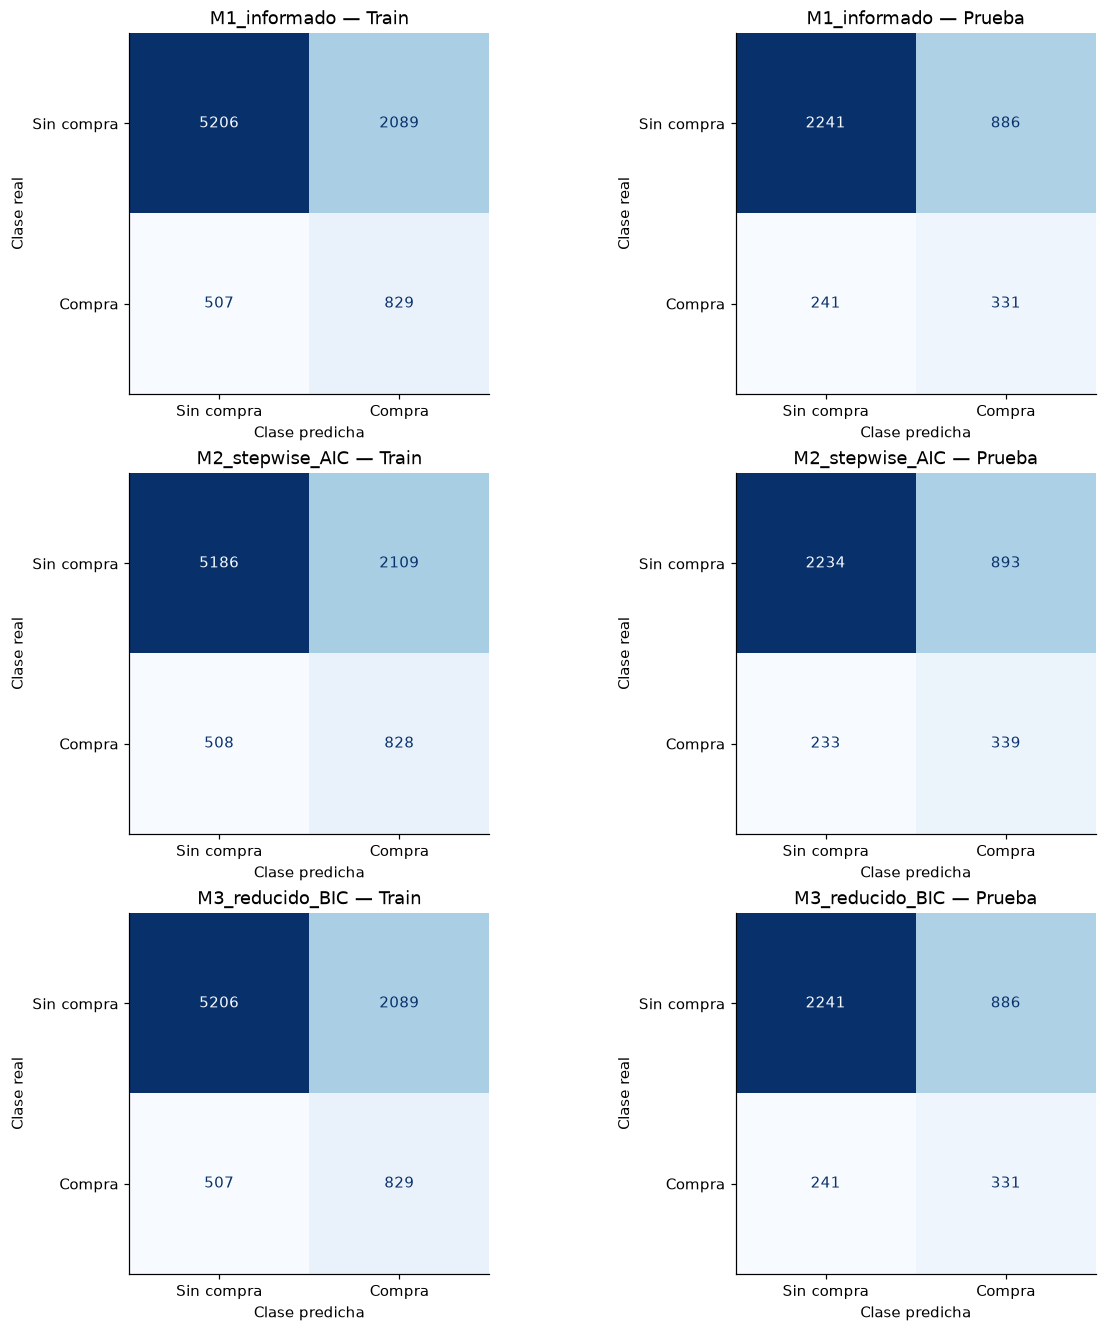

**Figura 5. Matrices de confusión de los tres modelos al umbral fijado 0,20.** Fuente: elaboración del grupo, datos UCI.

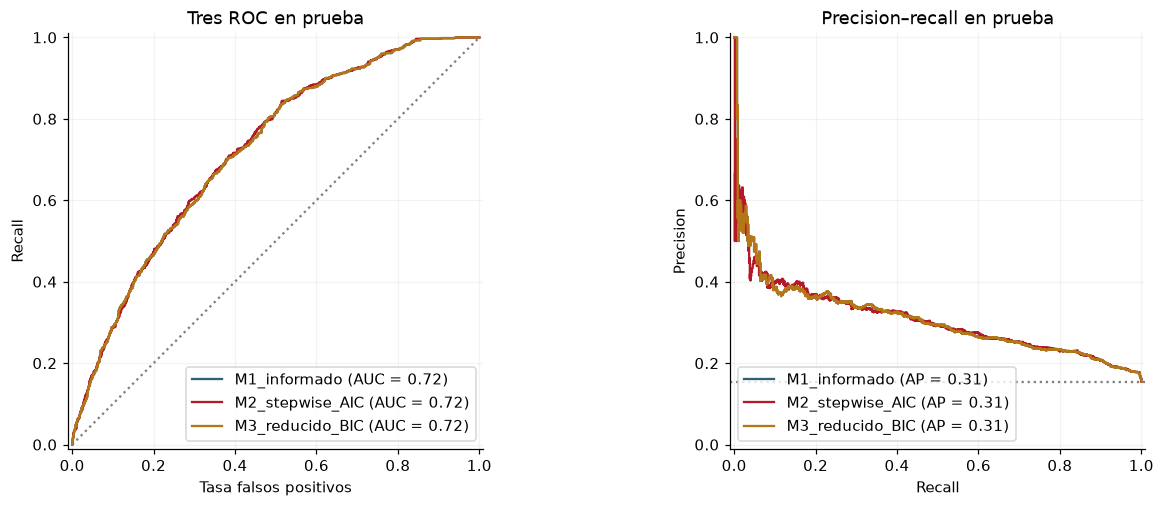

**Figura 6. Evaluación posterior a selección; no se reelige modelo o umbral con estas curvas.** Fuente: elaboración del grupo, datos UCI.

**Resultado del seleccionado:** AUC 0,720, AP 0,308, recall 57,87 %, precision 27,20 %, 331 compras detectadas de 572 y 886 falsas alarmas. Un recall mayor puede tener costo en precision; no se declara utilidad comercial sin costos y validación adicional.

**Tabla 31. Efecto de ponderar con variables e imputación fijas y umbral 0,5; no se reelige ganador con prueba**

,ponderacion,conjunto,n,compras,umbral,accuracy,precision,recall,F1,ROC_AUC,AP,TN,FP,FN,TP
0,Sin pesos,Train,8631,1336,"0,5000","0,8445","0,1250","0,0007","0,0015","0,7396","0,3074",7288,7,1335,1
1,Sin pesos,Prueba,3699,572,"0,5000","0,8462","1,0000","0,0052","0,0104","0,7203","0,3083",3127,0,569,3
2,Balanceado,Train,8631,1336,"0,5000","0,6033","0,2504","0,7837","0,3795","0,7395","0,3070",4160,3135,289,1047
3,Balanceado,Prueba,3699,572,"0,5000","0,5980","0,2393","0,7343","0,3610","0,7204","0,3088",1792,1335,152,420


**Ponderación aplicada y comparada:** el seleccionado usa sin pesos según el criterio interno de discriminación. Los pesos balanceados son una alternativa explícita, no omitida. Su efecto al umbral común se presenta separado del cambio de umbral.

**Tabla 32. Resumen ejecutivo en prueba: misma especificación; separar ponderación del punto de operación**

,configuracion,peso_compra,umbral,TP,FP,FN,TN,recall,precision,F1,ROC_AUC,AP
0,"Referencia: sin pesos, umbral 0,5","1,0000","0,5000",3,0,569,3127,"0,0052","1,0000","0,0104","0,7203","0,3083"
1,"Solo cambia ponderación: balanceado, 0,5","3,2302","0,5000",420,1335,152,1792,"0,7343","0,2393","0,3610","0,7204","0,3088"
2,Configuración seleccionada internamente,"1,0000","0,2000",331,886,241,2241,"0,5787","0,2720","0,3700","0,7203","0,3083"


**Cómo leerla:** las dos primeras filas aíslan ponderación manteniendo 0,5. La última presenta la decisión interna. Si usa pesos, su diferencia con la segunda fila aísla el umbral; si no los usa, se compara con la primera. Las probabilidades ponderadas no se presuponen calibradas.

In [11]:
DAT_TEST={m:completar(Xte,PREPS[m]) for m in METODOS}
XB=DAT_TEST[ELEGIDA];YB=yte.loc[XB.index]
FIT_FINAL={};PREDICCIONES={};filas_test=[]
for t,gs in SELECCIONES.items():
 za=diseno(XA,ESCALA,gs,FORMA);zb=diseno(XB,ESCALA,gs,FORMA)
 f=ajustar(YA,za,PESOS);FIT_FINAL[t]=f
 for conjunto,zz,yy in [('Train',za,YA),('Prueba',zb,YB)]:
  pro=np.asarray(f.predict(zz));PREDICCIONES[t,conjunto]=pro
  for u in sorted(set([.5,UMBRAL])):filas_test.append({'modelo':t,'conjunto':conjunto,'ponderacion':PONDERACION,**metricas(yy,pro,u)})
tabla_test=pd.DataFrame(filas_test)
tabla(tabla_test,'Métricas requeridas: tres modelos, train/prueba y umbrales fijados')
tabla(pd.DataFrame([{'conjunto':n,'n':len(yy),'accuracy_siempre_no_compra':float((yy==0).mean()),
 'recall_siempre_no_compra':0.,'AUC_score_constante':.5,'AP_score_constante':float(yy.mean())}
 for n,yy in [('Train',YA),('Prueba',YB)]]),'Referencia mayoritaria')
fig,axes=plt.subplots(3,2,figsize=(11,12),constrained_layout=True)
for j,t in enumerate(TIPOS):
 for k,(conjunto,yy) in enumerate([('Train',YA),('Prueba',YB)]):
  cm=confusion_matrix(yy,PREDICCIONES[t,conjunto]>=UMBRAL,labels=[0,1])
  ConfusionMatrixDisplay(cm,display_labels=['Sin compra','Compra']).plot(ax=axes[j,k],colorbar=False,cmap='Blues',values_format='d')
  axes[j,k].grid(False);axes[j,k].set(title=t+' — '+conjunto,xlabel='Clase predicha',ylabel='Clase real')
figura('Matrices de confusión de los tres modelos al umbral fijado '+numero(UMBRAL,2)+'.')
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for j,t in enumerate(TIPOS):
 RocCurveDisplay.from_predictions(YB,PREDICCIONES[t,'Prueba'],name=t,ax=axes[0],curve_kwargs={'color':COLORES[j]})
 PrecisionRecallDisplay.from_predictions(YB,PREDICCIONES[t,'Prueba'],name=t,ax=axes[1],curve_kwargs={'color':COLORES[j]})
axes[0].plot([0,1],[0,1],color='grey',ls=':');axes[0].set(xlabel='Tasa falsos positivos',ylabel='Recall',title='Tres ROC en prueba')
axes[1].axhline(YB.mean(),color='grey',ls=':');axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall en prueba')
figura('Evaluación posterior a selección; no se reelige modelo o umbral con estas curvas.')
R_FINAL=tabla_test.loc[(tabla_test.modelo==GANADOR)&(tabla_test.conjunto=='Prueba')&np.isclose(tabla_test.umbral,UMBRAL)].iloc[0]
display(Markdown('**Resultado del seleccionado:** AUC '+numero(R_FINAL.ROC_AUC)+', AP '+numero(R_FINAL.AP)+
 ', recall '+numero(100*R_FINAL.recall,2)+' %, precision '+numero(100*R_FINAL.precision,2)+' %, '+
 str(int(R_FINAL.TP))+' compras detectadas de '+str(int(R_FINAL.compras))+' y '+str(int(R_FINAL.FP))+
 ' falsas alarmas. Un recall mayor puede tener costo en precision; no se declara utilidad comercial sin costos y validación adicional.'))
# Contraste controlado adicional para la especificación seleccionada: evaluar pesos también en prueba.
filas_pesos=[]
for nombre,pes in [('Sin pesos',None),('Balanceado',pesos_clase(YA))]:
    fit_p=ajustar(YA,diseno(XA,ESCALA,SELECCIONES[GANADOR],FORMA),pes)
    for conjunto,xx,yy in [('Train',XA,YA),('Prueba',XB,YB)]:
        probs=fit_p.predict(diseno(xx,ESCALA,SELECCIONES[GANADOR],FORMA))
        filas_pesos.append({'ponderacion':nombre,'conjunto':conjunto,
                           **metricas(yy,probs,.5)})
tabla_contraste_pesos=pd.DataFrame(filas_pesos)
tabla(tabla_contraste_pesos,'Efecto de ponderar con variables e imputación fijas y umbral 0,5; no se reelige ganador con prueba')
display(Markdown('**Ponderación aplicada y comparada:** el seleccionado usa '+PONDERACION.lower()+
    ' según el criterio interno de discriminación. Los pesos balanceados son una alternativa explícita, '
    'no omitida. Su efecto al umbral común se presenta separado del cambio de umbral.'))

filas_ejecutivas=[]
for nombre,pes,u in [('Referencia: sin pesos, umbral 0,5',None,.5),
 ('Solo cambia ponderación: balanceado, 0,5',pesos_clase(YA),.5),
 ('Configuración seleccionada internamente',PESOS,UMBRAL)]:
 ff=ajustar(YA,diseno(XA,ESCALA,SELECCIONES[GANADOR],FORMA),pes)
 pp=ff.predict(diseno(XB,ESCALA,SELECCIONES[GANADOR],FORMA))
 filas_ejecutivas.append({'configuracion':nombre,'forma':FORMA,
  'peso_compra':1. if pes is None else pes[1],**metricas(YB,pp,u)})
tabla_ejecutiva=pd.DataFrame(filas_ejecutivas)
tabla(tabla_ejecutiva[['configuracion','peso_compra','umbral','TP','FP','FN','TN','recall','precision','F1','ROC_AUC','AP']],
 'Resumen ejecutivo en prueba: misma especificación; separar ponderación del punto de operación')
display(Markdown('**Cómo leerla:** las dos primeras filas aíslan ponderación manteniendo 0,5. '
 'La última presenta la decisión interna. Si usa pesos, su diferencia con la segunda fila aísla el umbral; '
 'si no los usa, se compara con la primera. Las probabilidades ponderadas no se presuponen calibradas.'))


### 6.1. Evaluación separada de la alternativa regularizada del grid search

La combinación elegida en 5.1 se reajusta con todo el entrenamiento y se evalúa en
prueba **sin volver a elegir pesos, C o umbral**. Se mantiene imputación, escala y forma
aprendidas en entrenamiento. La comparación incluye la referencia no penalizada.

El recall mínimo de 50 % fue una condición interna, **no una garantía en prueba**.
Si no se cumple o aumentan las falsas alarmas, se informa sin cambiar la elección para
mejorar retrospectivamente el resultado. No se atribuye cualquier cambio solo a C:
también pueden cambiar pesos y umbral. No se calculan IC Wald de ML para coeficientes L2.


**Tabla 33. Referencia inferencial frente a alternativa L2; decisiones fijadas con entrenamiento**

,modelo,conjunto,peso_compra,C,umbral,TP,FP,FN,TN,recall,precision,F1,ROC_AUC,AP,recall_al_menos_50pct
0,L2 elegido por grid search,Train,"1,0000","0,1000","0,2250",688,1552,648,5743,"0,5150","0,3071","0,3848","0,7395","0,3069",True
1,Referencia sin penalización,Train,"1,0000",No aplica,"0,2000",829,2089,507,5206,"0,6205","0,2841","0,3898","0,7396","0,3074",True
2,L2 elegido por grid search,Prueba,"1,0000","0,1000","0,2250",282,670,290,2457,"0,4930","0,2962","0,3701","0,7202","0,3044",False
3,Referencia sin penalización,Prueba,"1,0000",No aplica,"0,2000",331,886,241,2241,"0,5787","0,2720","0,3700","0,7203","0,3083",True


**Tabla 34. Coeficientes puntuales, misma escala; los IC bootstrap de sección 8 pertenecen a la referencia no penalizada**

,predictor,coef_L2,coef_referencia_no_penalizada
0,const,"-2,3203","-2,3788"
1,ProductRelated_Duration,"0,4716","0,4739"
2,ExitRates,"-1,2891","-1,4021"
3,VisitorType_New_Visitor,"0,5156","0,5298"
4,VisitorType_Other,"0,2374","0,5980"


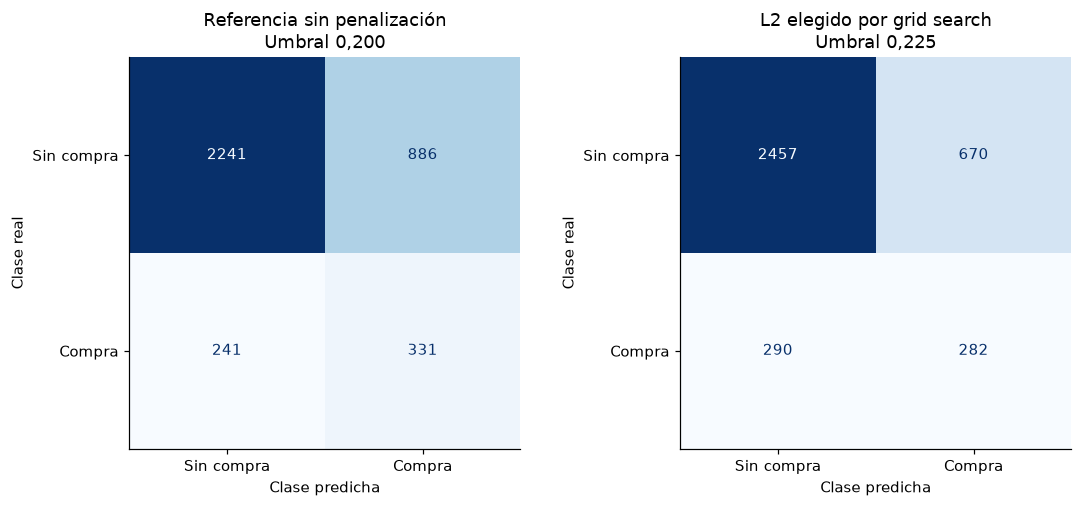

**Figura 7. Evaluación de prueba del grid search frente a referencia; no se reoptimiza con estas matrices.** Fuente: elaboración del grupo, datos UCI.

**Resultado de prueba del L2:** 670 falsas alarmas y 282 compras detectadas. Frente a referencia: cambio de FP **-216**, cambio de TP **-49**. Recall **49,30 %**; **no cumple** el objetivo de recall de 50 % en este conjunto. Se conserva el resultado, incluso si la rejilla no aporta una mejora.

In [12]:
GRID_FIT=None;GRID_TEST=None;tabla_grid_final=pd.DataFrame();tabla_grid_coef=pd.DataFrame()
if GRID_MEJOR is not None:
 zga=diseno(XA,ESCALA,GRID_GRUPOS,GRID_FORMA).drop(columns='const')
 zgb=diseno(XB,ESCALA,GRID_GRUPOS,GRID_FORMA).drop(columns='const')
 GRID_FIT=ajustar_grid(zga,YA,GRID_MEJOR['peso_compra'],GRID_MEJOR['C'])
 probs_grid_test=GRID_FIT.predict_proba(zgb)[:,1]
 GRID_TEST=metricas(YB,probs_grid_test,GRID_MEJOR['umbral'])
 filas=[]
 for conjunto,yy,pro in [('Train',YA,GRID_FIT.predict_proba(zga)[:,1]),('Prueba',YB,probs_grid_test)]:
  filas.append({'modelo':'L2 elegido por grid search','conjunto':conjunto,
   'peso_compra':GRID_MEJOR['peso_compra'],'C':GRID_MEJOR['C'],**metricas(yy,pro,GRID_MEJOR['umbral'])})
  filas.append({'modelo':'Referencia sin penalización','conjunto':conjunto,
   'peso_compra':1. if PESOS is None else PESOS[1]/PESOS[0],'C':np.nan,
   **metricas(yy,PREDICCIONES[GANADOR,conjunto],UMBRAL)})
 tabla_grid_final=pd.DataFrame(filas)
 tabla_grid_final['recall_al_menos_50pct']=tabla_grid_final.recall>=GRID_RECALL_MIN
 tabla(tabla_grid_final[['modelo','conjunto','peso_compra','C','umbral','TP','FP','FN','TN','recall','precision','F1','ROC_AUC','AP','recall_al_menos_50pct']],
  'Referencia inferencial frente a alternativa L2; decisiones fijadas con entrenamiento')
 tabla_grid_coef=pd.DataFrame({'predictor':['const',*zga.columns],
  'coef_L2':np.r_[GRID_FIT.intercept_,GRID_FIT.coef_.ravel()],
  'coef_referencia_no_penalizada':np.asarray(FIT_FINAL[GANADOR].params)})
 tabla(tabla_grid_coef,'Coeficientes puntuales, misma escala; los IC bootstrap de sección 8 pertenecen a la referencia no penalizada')
 fig,axes=plt.subplots(1,2,figsize=(10,4.5),constrained_layout=True)
 for ax,nombre,pro,u in [(axes[0],'Referencia sin penalización',PREDICCIONES[GANADOR,'Prueba'],UMBRAL),
                         (axes[1],'L2 elegido por grid search',probs_grid_test,GRID_MEJOR['umbral'])]:
  ConfusionMatrixDisplay(confusion_matrix(YB,pro>=u,labels=[0,1]),display_labels=['Sin compra','Compra']).plot(
   ax=ax,colorbar=False,cmap='Blues',values_format='d')
  ax.set(title=nombre+'\nUmbral '+numero(u,3),xlabel='Clase predicha',ylabel='Clase real');ax.grid(False)
 figura('Evaluación de prueba del grid search frente a referencia; no se reoptimiza con estas matrices.')
 diferencia_fp=int(GRID_TEST['FP']-R_FINAL.FP);diferencia_tp=int(GRID_TEST['TP']-R_FINAL.TP)
 display(Markdown('**Resultado de prueba del L2:** '+str(GRID_TEST['FP'])+' falsas alarmas y '+str(GRID_TEST['TP'])+
  ' compras detectadas. Frente a referencia: cambio de FP **'+str(diferencia_fp)+'**, cambio de TP **'+str(diferencia_tp)+
  '**. Recall **'+numero(100*GRID_TEST['recall'],2)+' %**; '+
  ('cumple' if GRID_TEST['recall']>=GRID_RECALL_MIN else '**no cumple**')+
  ' el objetivo de recall de 50 % en este conjunto. Se conserva el resultado, incluso si la rejilla no aporta una mejora.'))
else:
 display(Markdown('Sin combinación elegible en entrenamiento: no se ajusta ni evalúa un ganador L2.'))


### 6.2. Incertidumbre del desempeño: bootstrap pareado con modelos fijos

Se calculan **2.000 remuestras pareadas de las sesiones de prueba**, con reemplazo y
semilla explícita. Cada réplica toma los mismos índices para Revenue y las puntuaciones
de ambos modelos. Se mantienen fijos modelo, imputación, escalado, pesos, C y umbral;
**no se reajusta ni se optimiza** con estas remuestras.

Se presentan IC percentiles del 95 % de precision, recall, F1, ROC-AUC, AP, tasa de falsos
positivos y conteos FP/TP. Para comparar se calcula, dentro de cada réplica, la diferencia
**L2 − referencia no penalizada**, y luego su intervalo. Restar intervalos separados no
equivale a este procedimiento pareado. En FP/tasa FP, valores negativos favorecen L2;
en recall y precision, valores positivos favorecen L2. Los conteos se refieren a muestras
del mismo tamaño que prueba; no son proyecciones a otra cantidad de sesiones.

**Alcance:** estos intervalos describen incertidumbre por muestreo de sesiones de prueba
para los modelos ya ajustados, bajo una aproximación de sesiones independientes y
representativas. No incluyen incertidumbre del entrenamiento, selección de variables,
búsqueda adaptativa, imputación múltiple o cambios temporales. La exploración previa del
holdout limita su interpretación confirmatoria. No se ajustan por comparaciones múltiples;
son intervalos individuales exploratorios, no pruebas simultáneas de superioridad.

Este análisis es distinto de las 1.000 remuestras de **coeficientes** del ítem 8. Que un
intervalo de recall incluya 50 % no demuestra cumplir un requisito mínimo: el resultado
puntual de prueba y la variación entre folds se mantienen visibles.


**Tabla 35. Desempeño en prueba: IC bootstrap percentiles, modelos y umbrales fijos**

,modelo,metrica,unidad,estimacion,IC95_inf,IC95_sup,B_validas
0,Referencia no penalizada,precision,proporción o índice (0–1),"0,2720","0,2471","0,2957",2000
1,L2 fijado,precision,proporción o índice (0–1),"0,2962","0,2681","0,3243",2000
2,Referencia no penalizada,recall,proporción o índice (0–1),"0,5787","0,5394","0,6182",2000
3,L2 fijado,recall,proporción o índice (0–1),"0,4930","0,4522","0,5335",2000
4,Referencia no penalizada,F1,proporción o índice (0–1),"0,3700","0,3412","0,3978",2000
5,L2 fijado,F1,proporción o índice (0–1),"0,3701","0,3393","0,4000",2000
6,Referencia no penalizada,ROC_AUC,proporción o índice (0–1),"0,7203","0,6977","0,7395",2000
7,L2 fijado,ROC_AUC,proporción o índice (0–1),"0,7202","0,6974","0,7393",2000
8,Referencia no penalizada,AP,proporción o índice (0–1),"0,3083","0,2752","0,3434",2000
9,L2 fijado,AP,proporción o índice (0–1),"0,3044","0,2727","0,3396",2000


**Tabla 36. Diferencias pareadas L2 − referencia: IC individuales, sin corrección por selección o multiplicidad**

,metrica,unidad,diferencia_L2_menos_referencia,IC95_inf,IC95_sup,incluye_cero,sentido_favorable
0,precision,proporción o índice (0–1),"0,0242","0,0117","0,0358",False,Positivo
1,recall,proporción o índice (0–1),"-0,0857","-0,1100","-0,0636",False,Positivo
2,F1,proporción o índice (0–1),"0,0000","-0,0156","0,0146",True,Positivo
3,ROC_AUC,proporción o índice (0–1),"-0,0000","-0,0011","0,0008",True,Positivo
4,AP,proporción o índice (0–1),"-0,0039","-0,0084","0,0010",True,Positivo
5,tasa_FP,proporción o índice (0–1),"-0,0691","-0,0781","-0,0607",False,Negativo
6,FP,sesiones,"-216,0000","-244,0000","-189,0000",False,Negativo
7,TP,sesiones,"-49,0000","-64,0000","-36,0000",False,Positivo


**Precisión y alcance:** el IC de la diferencia de precision **no incluye cero** en este análisis condicional. Esto no demuestra superioridad general ni corrige la selección previa. Réplicas válidas: 2000 de 2000.

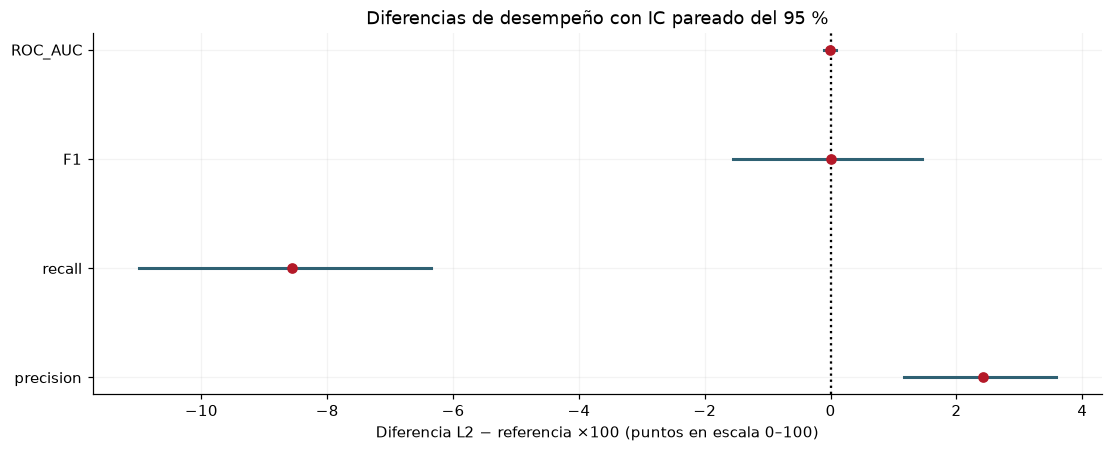

**Figura 8. Modelos fijos: más precision puede acompañarse de menos recall; estos IC no incorporan selección o reajuste.** Fuente: elaboración del grupo, datos UCI.

**Conclusión operativa:** La configuración L2 (umbral 0,225, peso de compra 1,000 frente a 1 y C=0,100) reduce falsas alarmas frente a la referencia no penalizada de 886 a 670, pero las compras detectadas pasan de 331 a 282. Cumple recall interno agregado de 50,75 %, con 3 de 5 folds sobre el mínimo. En prueba obtiene recall 49,30 % y precision 29,62 %; no cumple el 50 % en ese conjunto. Es una alternativa más conservadora, no una mejora global de discriminación. No se ajusta otra vez para corregir la prueba. Su utilidad depende del costo de falsas alarmas y compras omitidas; antes de uso operativo se requiere validación con nuevas sesiones y disponibilidad temporal de variables. PageValues sigue excluida.

In [13]:
B_BOOT_METRICAS=2000;SEED_BOOT_METRICAS=SEED+162
METRICAS_GRID_IC=['precision','recall','F1','ROC_AUC','AP','tasa_FP','FP','TP']
tabla_grid_ic=pd.DataFrame();tabla_grid_diferencias_ic=pd.DataFrame()
grid_boot_fallos=[];grid_boot_delta=np.empty((0,len(METRICAS_GRID_IC)))
grid_boot_resumen={};conclusion_grid_operativa='Sin combinación elegible; no se formula recomendación L2.'

def metricas_boot_fijas(yy,probs,umbral):
 yy=np.asarray(yy,dtype=int);probs=np.asarray(probs);pred=probs>=umbral
 tp=int(np.sum((yy==1)&pred));fp=int(np.sum((yy==0)&pred))
 fn=int(np.sum((yy==1)&~pred));tn=int(np.sum((yy==0)&~pred))
 if tp+fp==0 or tp+fn==0 or fp+tn==0:
  raise ValueError('Réplica degenerada: denominador nulo en métricas.')
 precision=tp/(tp+fp);recall=tp/(tp+fn)
 return np.array([precision,recall,2*tp/(2*tp+fp+fn),roc_auc_score(yy,probs),
  average_precision_score(yy,probs),fp/(fp+tn),float(fp),float(tp)])

if GRID_MEJOR is not None:
 yy_boot=np.asarray(YB,dtype=int)
 pro_ref=np.asarray(PREDICCIONES[GANADOR,'Prueba']);pro_l2=np.asarray(probs_grid_test)
 assert len(yy_boot)==len(pro_ref)==len(pro_l2)
 puntual_ref=metricas_boot_fijas(yy_boot,pro_ref,UMBRAL)
 puntual_l2=metricas_boot_fijas(yy_boot,pro_l2,GRID_MEJOR['umbral'])
 rng_metricas=np.random.default_rng(SEED_BOOT_METRICAS);rep_ref=[];rep_l2=[]
 for b in range(B_BOOT_METRICAS):
  ids=rng_metricas.integers(0,len(yy_boot),len(yy_boot))
  try:
   a=metricas_boot_fijas(yy_boot[ids],pro_ref[ids],UMBRAL)
   z=metricas_boot_fijas(yy_boot[ids],pro_l2[ids],GRID_MEJOR['umbral'])
   assert np.isfinite(a).all() and np.isfinite(z).all()
   rep_ref.append(a);rep_l2.append(z)
  except (ValueError,AssertionError) as exc:
   grid_boot_fallos.append({'replica':b,'error':type(exc).__name__,'detalle':str(exc)})
 assert len(grid_boot_fallos)<=.01*B_BOOT_METRICAS, 'Revisar réplicas degeneradas antes de comunicar IC.'
 rep_ref=np.asarray(rep_ref);rep_l2=np.asarray(rep_l2);grid_boot_delta=rep_l2-rep_ref
 assert len(rep_ref)==len(rep_l2)>=.99*B_BOOT_METRICAS
 filas_ic=[];filas_delta=[]
 for j,metrica in enumerate(METRICAS_GRID_IC):
  unidad='sesiones' if metrica in ['FP','TP'] else 'proporción o índice (0–1)'
  for nombre,puntual,reps in [('Referencia no penalizada',puntual_ref,rep_ref),('L2 fijado',puntual_l2,rep_l2)]:
   lo,hi=np.quantile(reps[:,j],[.025,.975])
   filas_ic.append({'modelo':nombre,'metrica':metrica,'unidad':unidad,'estimacion':float(puntual[j]),
    'IC95_inf':float(lo),'IC95_sup':float(hi),'B_validas':len(reps)})
  lo,hi=np.quantile(grid_boot_delta[:,j],[.025,.975])
  filas_delta.append({'metrica':metrica,'unidad':unidad,'diferencia_L2_menos_referencia':float(puntual_l2[j]-puntual_ref[j]),
   'IC95_inf':float(lo),'IC95_sup':float(hi),'incluye_cero':bool(lo<=0<=hi),
   'sentido_favorable':'Negativo' if metrica in ['FP','tasa_FP'] else 'Positivo'})
 tabla_grid_ic=pd.DataFrame(filas_ic);tabla_grid_diferencias_ic=pd.DataFrame(filas_delta)
 tabla(tabla_grid_ic,'Desempeño en prueba: IC bootstrap percentiles, modelos y umbrales fijos')
 tabla(tabla_grid_diferencias_ic,'Diferencias pareadas L2 − referencia: IC individuales, sin corrección por selección o multiplicidad')
 # Verificar que las cifras puntuales coincidan con las matrices y métricas ya informadas.
 assert puntual_l2[METRICAS_GRID_IC.index('FP')]==GRID_TEST['FP']
 assert puntual_l2[METRICAS_GRID_IC.index('TP')]==GRID_TEST['TP']
 assert np.isclose(puntual_l2[1],GRID_TEST['recall'])
 fila_precision=tabla_grid_diferencias_ic.loc[tabla_grid_diferencias_ic.metrica=='precision'].iloc[0]
 grid_boot_resumen={'B_solicitadas':B_BOOT_METRICAS,'B_validas':len(rep_ref),
  'semilla':SEED_BOOT_METRICAS,'metodo':'Percentil 95 %, remuestreo pareado ordinario de sesiones de prueba; modelos fijos.',
  'fallos':len(grid_boot_fallos),'IC_diferencia_precision_incluye_cero':bool(fila_precision.incluye_cero),
  'alcance':'Condicional a modelos ajustados; no bootstrap de entrenamiento, selección ni coeficientes.'}
 display(Markdown('**Precisión y alcance:** el IC de la diferencia de precision **'+
  ('incluye cero' if fila_precision.incluye_cero else 'no incluye cero')+
  '** en este análisis condicional. Esto no demuestra superioridad general ni corrige la selección previa. '
  'Réplicas válidas: '+str(len(rep_ref))+' de '+str(B_BOOT_METRICAS)+'.'))
 fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
 d=tabla_grid_diferencias_ic.loc[tabla_grid_diferencias_ic.metrica.isin(['precision','recall','F1','ROC_AUC'])].reset_index(drop=True)
 for j,r in d.iterrows():
  ax.plot([100*r.IC95_inf,100*r.IC95_sup],[j,j],color=COLORES[0],lw=2)
  ax.scatter(100*r.diferencia_L2_menos_referencia,j,color=COLORES[1],zorder=3)
 ax.axvline(0,color='black',ls=':');ax.set(yticks=range(len(d)),yticklabels=d.metrica,
  xlabel='Diferencia L2 − referencia ×100 (puntos en escala 0–100)',
  title='Diferencias de desempeño con IC pareado del 95 %')
 figura('Modelos fijos: más precision puede acompañarse de menos recall; estos IC no incorporan selección o reajuste.')
 conclusion_grid_operativa=(
  'La configuración L2 (umbral '+numero(GRID_MEJOR['umbral'],3)+', peso de compra '+numero(GRID_MEJOR['peso_compra'],3)+
  ' frente a 1 y C='+numero(GRID_MEJOR['C'],3)+') reduce falsas alarmas frente a la referencia no penalizada de '+
  str(int(R_FINAL.FP))+' a '+str(GRID_TEST['FP'])+', pero las compras detectadas pasan de '+str(int(R_FINAL.TP))+
  ' a '+str(GRID_TEST['TP'])+'. Cumple recall interno agregado de '+numero(100*GRID_MEJOR['recall'],2)+
  ' %, con '+str(grid_estabilidad_resumen['folds_cumplen_recall'])+' de 5 folds sobre el mínimo. En prueba obtiene recall '+
  numero(100*GRID_TEST['recall'],2)+' % y precision '+numero(100*GRID_TEST['precision'],2)+' %; '+
  ('no cumple' if GRID_TEST['recall']<GRID_RECALL_MIN else 'cumple')+
  ' el 50 % en ese conjunto. Es una alternativa más conservadora, no una mejora global de discriminación. '
  'No se ajusta otra vez para corregir la prueba. Su utilidad depende del costo de falsas alarmas y compras omitidas; '
  'antes de uso operativo se requiere validación con nuevas sesiones y disponibilidad temporal de variables. PageValues sigue excluida.')
 display(Markdown('**Conclusión operativa:** '+conclusion_grid_operativa))


### 6.3. Respuesta docente: comparación explícita de Formativa 2 y S3

Se recuperan las métricas de prueba guardadas de Formativa 2, incluida su **recall ≈0,005
como proporción (≈0,5 %)** y AUC ≈0,711. No se vuelve a ejecutar ni modificar esa entrega.
Se mantiene la misma máscara MCAR y el 70/30 estratificado para mostrar la progresión.

Primero se muestran los pesos balanceados solicitados por el profesor, calculados solo
con entrenamiento: `N/(2*n_clase)`. El peso de compra es aproximadamente 3,23, pero el de
no compra no es 1. Su cociente es el peso relativo; no confundir esos pesos absolutos
con el parámetro relativo del grid search, que fija no compra=1.

La tabla distingue cambios de preparación, ponderación y umbral. Formativa 2 frente a S3
no es una intervención causal aislada. El contraste de ponderación sí mantiene variables,
imputación y umbral común 0,5; la separación L2/umbral está en 10.1.


In [14]:
pesos_docente=pesos_clase(YA)
tabla_pesos_docente=pd.DataFrame([{'clase':'Sin compra' if clase==0 else 'Compra','n_train':int((YA==clase).sum()),
 'peso_balanceado':pesos_docente[clase],'peso_relativo_frente_no_compra':pesos_docente[clase]/pesos_docente[0]} for clase in [0,1]])
tabla(tabla_pesos_docente,'Pesos balanceados efectivamente evaluados en S3: N/(2*n_clase), sin usar prueba')
f2_test=next(x for x in F2['metricas'] if x['conjunto']=='Prueba')
filas_f2_s3=[{'configuracion':'Formativa 2: mediana, sin pesos, umbral 0,5','preparacion':'Mediana',
 'ponderacion':'Sin pesos','umbral':float(F2['configuracion']['umbral']),
 **{k:f2_test[k] for k in ['n','compras','TP','FP','FN','TN','accuracy','precision','recall','F1','ROC_AUC']},
 'AP':f2_test['average_precision']}]
for nombre in ['Sin pesos','Balanceado']:
 row=tabla_contraste_pesos.loc[(tabla_contraste_pesos.conjunto=='Prueba')&(tabla_contraste_pesos.ponderacion==nombre)].iloc[0]
 filas_f2_s3.append({'configuracion':'S3: '+nombre.lower()+', umbral 0,5','preparacion':ELEGIDA,
 'ponderacion':nombre,**{k:row[k] for k in ['umbral','n','compras','TP','FP','FN','TN','accuracy','precision','recall','F1','ROC_AUC','AP']}})
filas_f2_s3.append({'configuracion':'S3: referencia al umbral elegido por F1','preparacion':ELEGIDA,
 'ponderacion':PONDERACION,**{k:R_FINAL[k] for k in ['umbral','n','compras','TP','FP','FN','TN','accuracy','precision','recall','F1','ROC_AUC','AP']}})
if GRID_TEST is not None:
 filas_f2_s3.append({'configuracion':'S3: alternativa L2, objetivo FP con recall mínimo','preparacion':ELEGIDA,
 'ponderacion':'Peso relativo compra '+numero(GRID_MEJOR['peso_compra'],3),**GRID_TEST})
tabla_f2_s3=pd.DataFrame(filas_f2_s3)
tabla(tabla_f2_s3[['configuracion','umbral','TP','FP','FN','recall','precision','F1','ROC_AUC','AP']],
 'Formativa 2 → S3: mismas sesiones de prueba; acciones metodológicas y puntos de operación diferenciados')
balanceado=tabla_f2_s3.iloc[2]
lectura_f2_s3=('La ponderación fue aplicada y comparada explícitamente: a umbral 0,5, el balanceado obtiene recall '+
 numero(100*balanceado.recall,2)+' % y '+str(int(balanceado.FP))+' falsas alarmas, frente a '+
 numero(100*f2_test['recall'],2)+' % de recall en Formativa 2. No se atribuye todo ese cambio a pesos: '
 'la tabla incluye la referencia S3 sin pesos para separar el contraste. La opción L2 conserva pesos iguales '
 'según el objetivo interno declarado; no se oculta el resultado balanceado ni se lo presenta como ganador automático. '
 'Una precision alta calculada sobre muy pocas alertas al umbral 0,5 no demuestra utilidad: revisar TP, FP y recall.')
display(Markdown('**Lectura para responder al profesor:** '+lectura_f2_s3))


**Tabla 37. Pesos balanceados efectivamente evaluados en S3: N/(2*n_clase), sin usar prueba**

,clase,n_train,peso_balanceado,peso_relativo_frente_no_compra
0,Sin compra,7295,"0,5916","1,0000"
1,Compra,1336,"3,2302","5,4603"


**Tabla 38. Formativa 2 → S3: mismas sesiones de prueba; acciones metodológicas y puntos de operación diferenciados**

,configuracion,umbral,TP,FP,FN,recall,precision,F1,ROC_AUC,AP
0,"Formativa 2: mediana, sin pesos, umbral 0,5","0,5000",3,1,569,"0,0052","0,7500","0,0104","0,7114","0,2907"
1,"S3: sin pesos, umbral 0,5","0,5000",3,0,569,"0,0052","1,0000","0,0104","0,7203","0,3083"
2,"S3: balanceado, umbral 0,5","0,5000",420,1335,152,"0,7343","0,2393","0,3610","0,7204","0,3088"
3,S3: referencia al umbral elegido por F1,"0,2000",331,886,241,"0,5787","0,2720","0,3700","0,7203","0,3083"
4,"S3: alternativa L2, objetivo FP con recall mínimo","0,2250",282,670,290,"0,4930","0,2962","0,3701","0,7202","0,3044"


**Lectura para responder al profesor:** La ponderación fue aplicada y comparada explícitamente: a umbral 0,5, el balanceado obtiene recall 73,43 % y 1335 falsas alarmas, frente a 0,52 % de recall en Formativa 2. No se atribuye todo ese cambio a pesos: la tabla incluye la referencia S3 sin pesos para separar el contraste. La opción L2 conserva pesos iguales según el objetivo interno declarado; no se oculta el resultado balanceado ni se lo presenta como ganador automático. Una precision alta calculada sobre muy pocas alertas al umbral 0,5 no demuestra utilidad: revisar TP, FP y recall.

## 7. Diagnóstico del modelo seleccionado y sensibilidad

Se revisa VIF, residuos de devianza, leverage y distancia de Cook. Los umbrales 4/n y 2p/n
son alertas exploratorias, no reglas para borrar registros. Se analiza una retirada diagnóstica
de la fila más influyente en entrenamiento, sin modificar el modelo final según prueba.

**Linealidad en el logit:** se añaden términos cuadrados de las numéricas transformadas y
se aplica un Wald conjunto con covarianza consistente con el tipo de ajuste. Es una revisión
limitada de curvatura; no demuestra linealidad completa. Residuos logísticos no requieren
normalidad ni varianza constante como OLS. En clasificación ponderada, los scores no se
suponen calibrados a la prevalencia original.

**Tabla 39. Observaciones influyentes de entrenamiento, con ubicación CSV original**

,indice_original,fila_CSV,Cook,leverage,residuo_devianza,alerta_Cook,alerta_leverage
5354,7600,7602,"0,0275","0,0001","3,8784",True,False
4730,6700,6702,"0,0274","0,0001","3,9468",True,False
5828,8299,8301,"0,0222","0,0147","2,0573",True,True
5850,8328,8330,"0,0218","0,0156","2,0255",True,True
8269,11809,11811,"0,0217","0,0158","2,0165",True,True
7949,11308,11310,"0,0191","0,0210","1,8327",True,True
8483,12117,12119,"0,0160","0,0263","1,6482",True,True
7050,10024,10026,"0,0136","0,0300","1,5129",True,True
7026,9988,9990,"0,0113","0,0328","1,3833",True,True
7224,10285,10287,"0,0108","0,0333","1,3587",True,True


**Tabla 40. Curvatura sobre los predictores retenidos: diagnóstico de train, decisión predictiva en sección 5**

,diagnostico,Wald,gl,p,lectura,forma_final
0,Términos cuadrados conjuntos,"8,1806",2,"0,0167",Cuadrados conjuntamente relevantes; revisar comparación CV de sección 5,Lineal


**Tabla 41. Sensibilidad individual: se conserva el ajuste completo para evaluación**

,predictor,coef_completo,coef_sin_mas_influyente,cambio
0,const,"-2,3788","-2,3959","-0,0171"
1,ProductRelated_Duration,"0,4739","0,4727","-0,0012"
2,ExitRates,"-1,4021","-1,4405","-0,0384"
3,VisitorType_New_Visitor,"0,5298","0,5233","-0,0066"
4,VisitorType_Other,"0,5980","0,5964","-0,0016"


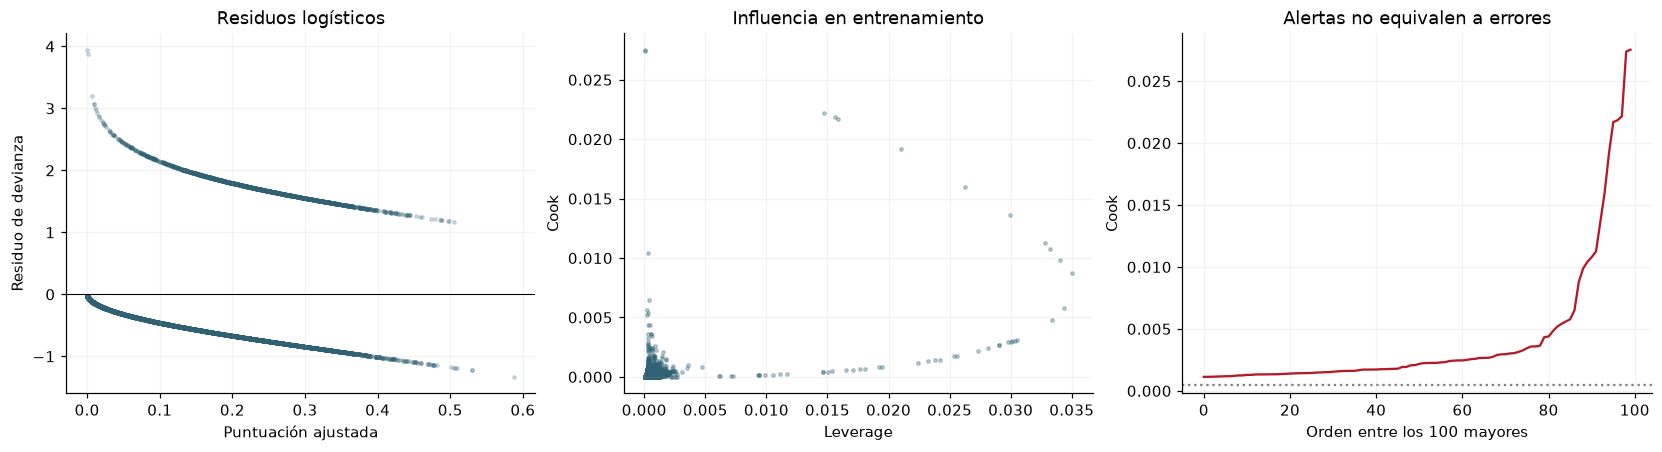

**Figura 9. Diagnóstico de entrenamiento; no se eliminan registros para mejorar prueba.** Fuente: elaboración del grupo, datos UCI.

**Acción frente al diagnóstico:** se compararon ambas formas en validación interna y se retuvo **Lineal** con la regla de parsimonia. Un p pequeño indica evidencia de curvatura, pero no garantiza que añadir cuadrados mejore suficientemente la predicción. Si se conserva la forma lineal, el diagnóstico sigue siendo una limitación explícita.

In [15]:
GS=SELECCIONES[GANADOR];ZF=diseno(XA,ESCALA,GS,FORMA);FF=FIT_FINAL[GANADOR]
LO,HI,SE,COV=ic_wald(FF,ZF,YA,PESOS)
influencia=FF.get_influence(observed=False)
cook=np.asarray(influencia.cooks_distance[0]);hat=np.asarray(influencia.hat_matrix_diag)
tabla_influencia=pd.DataFrame({'indice_original':XA.index,'fila_CSV':XA.index.to_numpy()+2,
 'Cook':cook,'leverage':hat,'residuo_devianza':np.asarray(FF.resid_deviance)})
tabla_influencia['alerta_Cook']=tabla_influencia.Cook>4/len(XA)
tabla_influencia['alerta_leverage']=tabla_influencia.leverage>2*ZF.shape[1]/len(XA)
tabla_influencia=tabla_influencia.sort_values('Cook',ascending=False)
tabla(tabla_influencia.head(12),'Observaciones influyentes de entrenamiento, con ubicación CSV original')
ZQ=diseno(XA,ESCALA,GS);cols_q=[]
for c in GS:
 if c in NUM:ZQ[c+'_cuadrado']=ZF[c]**2;cols_q.append(c+'_cuadrado')
FQ=ajustar(YA,ZQ,PESOS);lq,hq,sq,cq=ic_wald(FQ,ZQ,YA,PESOS)
iq=[ZQ.columns.get_loc(c) for c in cols_q];bq=np.asarray(FQ.params)[iq]
wald=float(bq@np.linalg.pinv(cq[np.ix_(iq,iq)])@bq);p_curvatura=float(stats.chi2.sf(wald,len(iq)))
tabla(pd.DataFrame([{'diagnostico':'Términos cuadrados conjuntos','Wald':wald,'gl':len(iq),'p':p_curvatura,
 'lectura':('Cuadrados conjuntamente relevantes; revisar comparación CV de sección 5' if p_curvatura<.05 else 'No se detecta esta curvatura; no prueba linealidad universal'),'forma_final':FORMA}]),
 'Curvatura sobre los predictores retenidos: diagnóstico de train, decisión predictiva en sección 5')
fila_mas=int(tabla_influencia.iloc[0].indice_original)
keep=XA.index!=fila_mas
F_sens=ajustar(YA.loc[keep],ZF.loc[keep],PESOS)
sens_coef=pd.DataFrame({'predictor':ZF.columns,'coef_completo':np.asarray(FF.params),
 'coef_sin_mas_influyente':np.asarray(F_sens.params),'cambio':np.asarray(F_sens.params)-np.asarray(FF.params)})
tabla(sens_coef,'Sensibilidad individual: se conserva el ajuste completo para evaluación')
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
axes[0].scatter(FF.fittedvalues,FF.resid_deviance,s=5,alpha=.2,color=COLORES[0]);axes[0].axhline(0,color='black',lw=.7)
axes[0].set(xlabel='Puntuación ajustada',ylabel='Residuo de devianza',title='Residuos logísticos')
axes[1].scatter(hat,cook,s=5,alpha=.3,color=COLORES[0]);axes[1].set(xlabel='Leverage',ylabel='Cook',title='Influencia en entrenamiento')
axes[2].plot(np.sort(cook)[-100:],color=COLORES[1]);axes[2].axhline(4/len(XA),ls=':',color='grey')
axes[2].set(xlabel='Orden entre los 100 mayores',ylabel='Cook',title='Alertas no equivalen a errores')
figura('Diagnóstico de entrenamiento; no se eliminan registros para mejorar prueba.')
display(Markdown('**Acción frente al diagnóstico:** se compararon ambas formas en validación interna '
 'y se retuvo **'+FORMA+'** con la regla de parsimonia. Un p pequeño indica evidencia de curvatura, '
 'pero no garantiza que añadir cuadrados mejore suficientemente la predicción. Si se conserva la '
 'forma lineal, el diagnóstico sigue siendo una limitación explícita.'))


## 8. Bootstrap de coeficientes y odds ratios del modelo seleccionado

Se remuestrean filas de entrenamiento **con reemplazo**, 1.000 veces, y se reajustan
imputación, escala y modelo. Especificación, estrategia, pesos de clase elegidos y umbral
permanecen fijados: la incertidumbre es **condicional a la selección**, no incluye buscar
de nuevo modelos ni propaga por completo la incertidumbre de una imputación múltiple.

Como cada remuestra aprende otra escala, sus coeficientes e intercepto se convierten a la
escala original de referencia de entrenamiento antes de compararlos. Los OR siempre tienen
la misma unidad (1 DE de referencia; categorías frente a recurrentes).

IC bootstrap percentil del 95 % frente a Wald. Si el ajuste es ponderado, Wald usa sandwich
HC0 con puntuaciones ponderadas; no interpreta pesos de clase como frecuencias observadas.
Si no hay ponderación, usa la covarianza ML convencional. Se informa conservación de signo,
cruce de beta=0/OR=1 y convergencia de extremos para B=250,500,1000. No se fuerza que todos
los parámetros sean estables. Los modelos con fallos no se sustituyen silenciosamente.

**Escala e interpretación:** se transforma cada réplica a la escala de referencia del
entrenamiento original, incluyendo intercepto, términos lineales y cuadrados si existen.
Con cuadrados, exp(coeficiente lineal) no es un OR global: se presentan contrastes de
la media a +1 DE de la variable transformada, manteniendo las otras constantes.
El intercepto se informa como coeficiente, sin etiquetarlo como OR.

**Estabilidad de selección, análisis adicional:** 100 remuestras repiten el stepwise AIC
lineal y registran inclusión por variable. Es distinto de las 1.000 remuestras de los
coeficientes condicionados al modelo final. Estas frecuencias no son probabilidades de
que una variable sea «verdadera» ni corrigen automáticamente los IC por selección.


**Distinción respecto al grid search:** esta sección corresponde exclusivamente al modelo
de referencia no penalizado. No son intervalos del modelo L2 de 5.1/6.1. El grid search es
una ampliación predictiva, condicionada a la especificación elegida; no una cuarta vía
para atribuir significación estadística a los coeficientes regularizados.


Bootstrap

100

/

1000

| segundos

...

20.5

**Tabla 42. Coeficientes: intervalos clásicos/robustos y bootstrap; OR global solo para forma lineal**

,predictor,coef,Wald_inf,Wald_sup,boot_inf,boot_sup,OR,OR_Wald_inf,OR_Wald_sup,OR_boot_inf,OR_boot_sup,fraccion_mismo_signo,incluye_cero,B_validas
0,const,"-2,3788","-2,4902","-2,2673","-2,5055","-2,2615",No aplica,No aplica,No aplica,No aplica,No aplica,"1,0000",False,1000
1,ProductRelated_Duration,"0,4739","0,3932","0,5546","0,3962","0,5577","1,6062","1,4817","1,7412","1,4861","1,7467","1,0000",False,1000
2,ExitRates,"-1,4021","-1,6076","-1,1967","-1,6279","-1,1761","0,2461","0,2004","0,3022","0,1963","0,3085","1,0000",False,1000
3,VisitorType_New_Visitor,"0,5298","0,3621","0,6976","0,3712","0,7051","1,6987","1,4363","2,0089","1,4495","2,0241","1,0000",False,1000
4,VisitorType_Other,"0,5980","-0,1348","1,3308","-0,3037","1,3028","1,8185","0,8739","3,7842","0,7381","3,6794","0,9220",True,1000


**Tabla 43. Convergencia de extremos: una fila por coeficiente; B=250,500,1000**

,predictor,inferior_B250,inferior_B500,inferior_B1000,superior_B250,superior_B500,superior_B1000
0,ExitRates,"-1,6149","-1,6264","-1,6279","-1,2043","-1,1827","-1,1761"
1,ProductRelated_Duration,"0,3916","0,3966","0,3962","0,5566","0,5523","0,5577"
2,VisitorType_New_Visitor,"0,3515","0,3530","0,3712","0,6843","0,6863","0,7051"
3,VisitorType_Other,"-0,3846","-0,3381","-0,3037","1,3994","1,2881","1,3028"
4,const,"-2,5055","-2,5045","-2,5055","-2,2658","-2,2600","-2,2615"


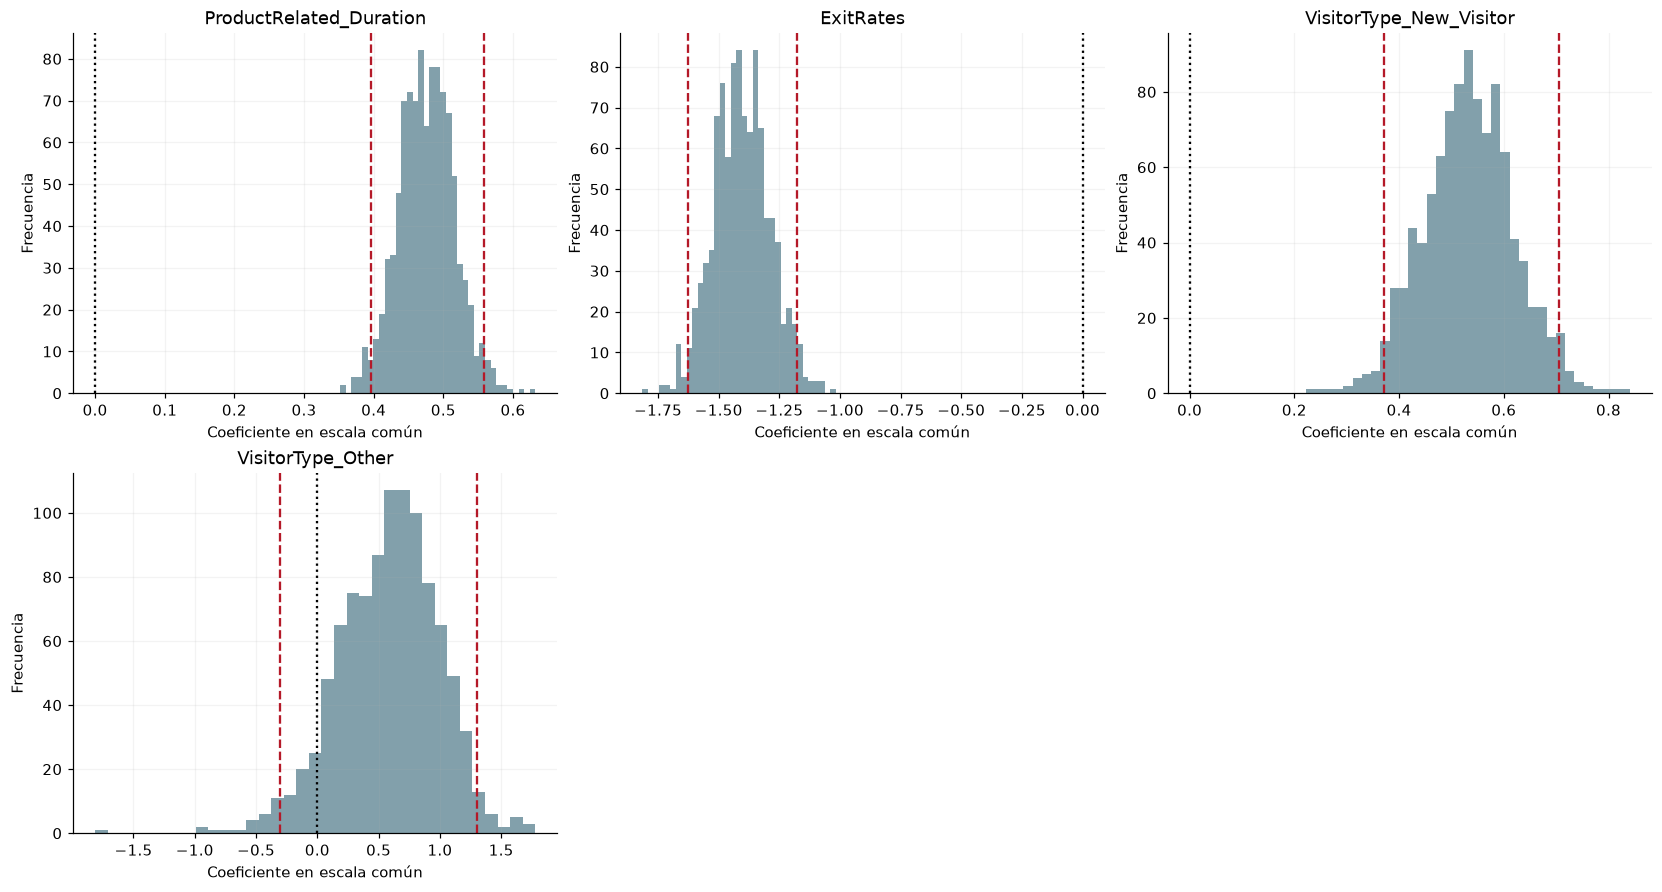

**Figura 10. Distribuciones bootstrap de coeficientes, referencia cero e IC percentil.** Fuente: elaboración del grupo, datos UCI.

**Tabla 44. OR interpretables del modelo final: contraste definido y comparación de IC**

,predictor,contraste,log_OR,OR,Wald_inf,Wald_sup,OR_boot_inf,OR_boot_sup,fraccion_mismo_signo,incluye_OR_1
0,ProductRelated_Duration,de media a +1 DE en escala transformada,"0,4739","1,6062","1,4817","1,7412","1,4861","1,7467","1,0000",False
1,ExitRates,de media a +1 DE en escala transformada,"-1,4021","0,2461","0,2004","0,3022","0,1963","0,3085","1,0000",False
2,VisitorType_New_Visitor,frente a Returning_Visitor,"0,5298","1,6987","1,4363","2,0089","1,4495","2,0241","1,0000",False
3,VisitorType_Other,frente a Returning_Visitor,"0,5980","1,8185","0,8739","3,7842","0,7381","3,6794","0,9220",True


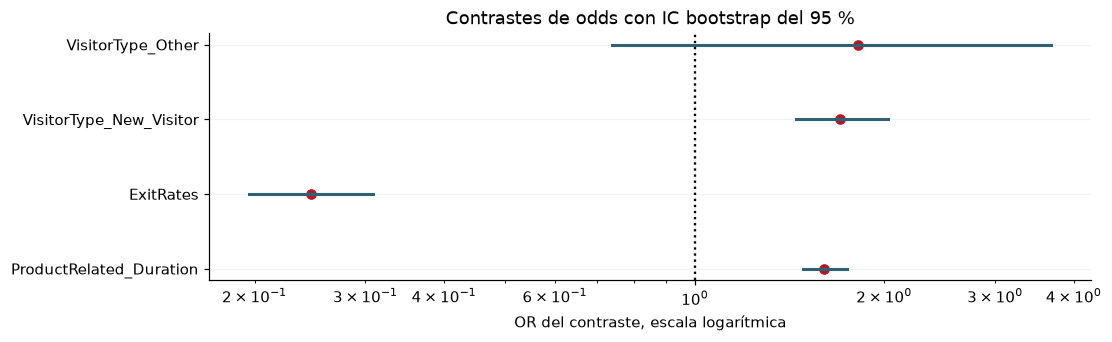

**Figura 11. Contrastes: de z=0 a z=1 para variables numéricas; categoría frente a recurrentes.** Fuente: elaboración del grupo, datos UCI.

**Estabilidad de coeficientes:** IC que incluyen cero: VisitorType_Other. Se distinguen coeficientes y contrastes OR, especialmente si hay cuadrados. Fallos: 0.

**Precisión de los extremos:** de 500 a 1000 remuestras, el mayor desplazamiento de un extremo equivale al **5,65 %** del ancho final de su intervalo. Esto describe error Monte Carlo relativo; no demuestra cobertura poblacional ni elimina incertidumbre de selección.

Estabilidad stepwise

20

...

100

/

100

**Tabla 45. Frecuencia de inclusión al repetir stepwise AIC en 100 remuestras; análisis separado**

,variable,B_validas,veces_incluida,frecuencia_inclusion
0,ProductRelated,100,67,"0,6700"
1,ProductRelated_Duration,100,100,"1,0000"
2,BounceRates,100,24,"0,2400"
3,ExitRates,100,100,"1,0000"
4,VisitorType,100,100,"1,0000"


In [16]:
rng=np.random.default_rng(SEED+8);boot=[];fallos=[];t_boot=perf_counter()
for b in range(B_BOOT):
 idx=rng.integers(0,len(Xtr),len(Xtr))
 # Reiniciar índices evita ambigüedad de etiquetas repetidas en pandas.
 xx=Xtr.iloc[idx].reset_index(drop=True);yy=ytr.iloc[idx].reset_index(drop=True)
 try:
  pr=aprender_preparacion(xx,ELEGIDA);aa=completar(xx,pr);es=aprender_escala(aa)
  zz=diseno(aa,es,GS,FORMA);fit=ajustar(yy.loc[aa.index],zz,PESOS)
  br,_=transformar_coeficientes(fit.params,None,list(zz.columns),es,ESCALA)
  boot.append(br)
 except Exception as e:
  fallos.append({'replica':b,'error':type(e).__name__,'detalle':str(e)[:180]})
 if (b+1)%100==0:print('Bootstrap',b+1,'/',B_BOOT,'| segundos',round(perf_counter()-t_boot,1),flush=True)
assert len(fallos)<=.01*B_BOOT, 'Más de 1 % de fallos; revisar modelo antes de comunicar IC.'
BOOT=np.asarray(boot);assert BOOT.shape[0]>=990 and BOOT.shape[1]==len(ZF.columns)
intervalos=np.quantile(BOOT,[.025,.975],axis=0);betas=np.asarray(FF.params)
filas_boot=[]
for j,c in enumerate(ZF.columns):
 filas_boot.append({'predictor':c,'coef':betas[j],'Wald_inf':LO[j],'Wald_sup':HI[j],
 'boot_inf':intervalos[0,j],'boot_sup':intervalos[1,j], 'OR':np.exp(betas[j]) if c!='const' and not c.endswith('_cuadrado') and FORMA=='Lineal' else np.nan,
 'OR_Wald_inf':np.exp(LO[j]) if c!='const' and FORMA=='Lineal' else np.nan,'OR_Wald_sup':np.exp(HI[j]) if c!='const' and FORMA=='Lineal' else np.nan,
 'OR_boot_inf':np.exp(intervalos[0,j]) if c!='const' and FORMA=='Lineal' else np.nan,'OR_boot_sup':np.exp(intervalos[1,j]) if c!='const' and FORMA=='Lineal' else np.nan,
 'fraccion_mismo_signo':float(np.mean(np.sign(BOOT[:,j])==np.sign(betas[j]))),
 'incluye_cero':bool(intervalos[0,j]<=0<=intervalos[1,j]),'B_validas':len(BOOT)})
tabla_boot=pd.DataFrame(filas_boot)
tabla(tabla_boot,'Coeficientes: intervalos clásicos/robustos y bootstrap; OR global solo para forma lineal')
conv_boot=[]
for n in [250,500,len(BOOT)]:
 ci=np.quantile(BOOT[:n],[.025,.975],axis=0)
 for j,c in enumerate(ZF.columns):conv_boot.append({'B':n,'predictor':c,'inferior':ci[0,j],'superior':ci[1,j]})
tabla_conv_boot=pd.DataFrame(conv_boot)
resumen_convergencia=tabla_conv_boot.pivot(index='predictor',columns='B',values=['inferior','superior'])
resumen_convergencia.columns=[f'{tipo}_B{b}' for tipo,b in resumen_convergencia.columns]
tabla(resumen_convergencia.reset_index(),'Convergencia de extremos: una fila por coeficiente; B=250,500,1000')
fig,axes=plt.subplots(int(np.ceil((len(ZF.columns)-1)/3)),3,figsize=(15,4*int(np.ceil((len(ZF.columns)-1)/3))),squeeze=False,constrained_layout=True)
for j,(ax,c) in enumerate(zip(axes.ravel(),ZF.columns[1:]),1):
 ax.hist(BOOT[:,j],bins=35,color=COLORES[0],alpha=.6);ax.axvline(0,color='black',ls=':')
 ax.axvline(intervalos[0,j],color=COLORES[1],ls='--');ax.axvline(intervalos[1,j],color=COLORES[1],ls='--')
 ax.set(title=c,xlabel='Coeficiente en escala común',ylabel='Frecuencia')
for ax in axes.ravel()[len(ZF.columns)-1:]:ax.set_visible(False)
figura('Distribuciones bootstrap de coeficientes, referencia cero e IC percentil.')
contrastes=[]
for c,cambio,v in contrastes_OR(list(ZF.columns)):
 beta=float(v@betas);se_con=float(np.sqrt(v@COV@v));rep=BOOT@v
 lo_b,hi_b=np.quantile(rep,[.025,.975]);q=stats.norm.ppf(.975)
 contrastes.append({'predictor':c,'contraste':cambio,'log_OR':beta,'OR':np.exp(beta),
 'Wald_inf':np.exp(beta-q*se_con),'Wald_sup':np.exp(beta+q*se_con),
 'OR_boot_inf':np.exp(lo_b),'OR_boot_sup':np.exp(hi_b),
 'fraccion_mismo_signo':float(np.mean(np.sign(rep)==np.sign(beta))),
 'incluye_OR_1':bool(lo_b<=0<=hi_b)})
tabla_contrastes=pd.DataFrame(contrastes)
tabla(tabla_contrastes,'OR interpretables del modelo final: contraste definido y comparación de IC')
fig,ax=plt.subplots(figsize=(10,max(3,len(tabla_contrastes)*.75)),constrained_layout=True)
for j,r in tabla_contrastes.iterrows():
 ax.plot([r.OR_boot_inf,r.OR_boot_sup],[j,j],color=COLORES[0],lw=2);ax.scatter(r.OR,j,color=COLORES[1])
ax.axvline(1,color='black',ls=':');ax.set(xscale='log',yticks=range(len(tabla_contrastes)),
 yticklabels=tabla_contrastes.predictor,xlabel='OR del contraste, escala logarítmica',title='Contrastes de odds con IC bootstrap del 95 %')
figura('Contrastes: de z=0 a z=1 para variables numéricas; categoría frente a recurrentes.')
bt=tabla_boot.loc[tabla_boot.predictor!='const']
inestables=bt.loc[bt.incluye_cero,'predictor'].tolist()
display(Markdown('**Estabilidad de coeficientes:** '+('IC que incluyen cero: '+', '.join(inestables) if inestables else 'Ningún IC incluye cero')+
 '. Se distinguen coeficientes y contrastes OR, especialmente si hay cuadrados. Fallos: '+str(len(fallos))+'.'))
ci500=np.quantile(BOOT[:500],[.025,.975],axis=0)
desplazamiento_MC=float(np.max(np.abs(intervalos-ci500)/(intervalos[1]-intervalos[0])))
display(Markdown('**Precisión de los extremos:** de 500 a '+str(len(BOOT))+
    ' remuestras, el mayor desplazamiento de un extremo equivale al **'+numero(100*desplazamiento_MC,2)+
    ' %** del ancho final de su intervalo. Esto describe error Monte Carlo relativo; no demuestra cobertura poblacional ni elimina incertidumbre de selección.'))

rng_seleccion=np.random.default_rng(SEED+81);inclusiones=[];fallos_seleccion=[];B_SELECCION=100
for b in range(B_SELECCION):
 ids=rng_seleccion.integers(0,len(Xtr),len(Xtr))
 xx=Xtr.iloc[ids].reset_index(drop=True);yy=ytr.iloc[ids].reset_index(drop=True)
 try:
  aa=completar(xx,aprender_preparacion(xx,ELEGIDA));es=aprender_escala(aa)
  grupos=seleccionar(aa,yy.loc[aa.index],'M2_stepwise_AIC',es)
  inclusiones.append({'replica':b,'grupos':grupos})
 except Exception as e:fallos_seleccion.append({'replica':b,'error':type(e).__name__,'detalle':str(e)[:180]})
 if (b+1)%20==0:print('Estabilidad stepwise',b+1,'/',B_SELECCION,flush=True)
assert len(inclusiones)>=.95*B_SELECCION
tabla_estabilidad_seleccion=pd.DataFrame([{'variable':g,'B_validas':len(inclusiones),
 'veces_incluida':sum(g in r['grupos'] for r in inclusiones),
 'frecuencia_inclusion':np.mean([g in r['grupos'] for r in inclusiones])} for g in GRUPOS])
tabla(tabla_estabilidad_seleccion,'Frecuencia de inclusión al repetir stepwise AIC en 100 remuestras; análisis separado')


## 9. Impacto final de imputación: misma especificación, tres datasets

Ahora se reajusta la **misma especificación ganadora**, con ponderación y umbral fijados,
bajo eliminación, mediana y regresión. No se seleccionan nuevas variables para cada estrategia.
Se informan métricas en cada población disponible y en el subconjunto común de prueba sin
duración faltante. La segunda comparación reduce el problema de comparar poblaciones distintas;
la primera muestra la pérdida de cobertura. No se pueden imputar y predecir los casos eliminados.

Los tres ajustes usan la misma escala aprendida en el entrenamiento de referencia para comparar coeficientes e IC. Los errores
de mediana/regresión contra los 379 valores ocultados de prueba se revelan solo al final;
no se usan para elegir estrategia. Eliminación tiene error de reconstrucción no aplicable.

La comparación requerida por la rúbrica corresponde al modelo de referencia inferencial
no penalizado. La alternativa L2 tiene su evaluación separada en 6.1; no se mezclan sus
coeficientes o métricas con los de esta comparación.


In [17]:
impacto=[];coef_impacto=[];errores_test=[]
comunes=Xte.index[Xte[TARGET].notna()]
for m in METODOS:
 aa=DAT_TRAIN[m];bb=DAT_TEST[m];ya=ytr.loc[aa.index];yb=yte.loc[bb.index]
 es=ESCALA;za=diseno(aa,es,GS,FORMA);zb=diseno(bb,es,GS,FORMA)
 fit=ajustar(ya,za,PESOS);lo,hi,se,cv=ic_wald(fit,za,ya,PESOS)
 for pobl,ids in [('Disponibles',bb.index),('Comunes',comunes)]:
  pp=fit.predict(zb.loc[ids])
  impacto.append({'estrategia':m,'poblacion_prueba':pobl,'n_train':len(aa),
    'cobertura_total_prueba':len(bb)/len(Xte),**metricas(yte.loc[ids],pp,UMBRAL)})
 for j,c in enumerate(za.columns):
  if c=='const':continue
  factor=ESCALA['DE'][c]/es['DE'][c] if c in NUM else 1.
  coef_impacto.append({'estrategia':m,'predictor':c,'coef_escala_comun':float(fit.params.iloc[j]*factor),
    'IC95_inf':lo[j]*factor,'IC95_sup':hi[j]*factor,'OR':np.exp(fit.params.iloc[j]*factor) if FORMA=='Lineal' else np.nan,
    'OR_IC95_inf':np.exp(lo[j]*factor) if FORMA=='Lineal' else np.nan,'OR_IC95_sup':np.exp(hi[j]*factor) if FORMA=='Lineal' else np.nan})
 if m!='Eliminación':
  ids=Xte.index[Xte[TARGET].isna()];verdad=original.loc[ids,TARGET].to_numpy()/60.
  pred=bb.loc[ids,TARGET].to_numpy()/60.
  errores_test.append({'estrategia':m,'n_ocultos_prueba':len(ids),'MAE_min':mean_absolute_error(verdad,pred),
    'RMSE_min':np.sqrt(mean_squared_error(verdad,pred)), 'error_medio_min':float(np.mean(pred-verdad))})
tabla_impacto=pd.DataFrame(impacto);tabla_coef_impacto=pd.DataFrame(coef_impacto);tabla_error_test=pd.DataFrame(errores_test)
tabla(tabla_impacto,'Impacto de imputación sobre desempeño y cobertura; decisión interna conservada')
tabla(tabla_coef_impacto,'Coeficientes e IC tradicionales en escala común; bootstrap del ganador en sección 8')
tabla(tabla_error_test,'Error de reconstrucción en valores ocultados de prueba: evaluación final, no selección')
disp=tabla_impacto.loc[tabla_impacto.poblacion_prueba=='Comunes']
display(Markdown('**Lectura comparativa:** AUC en población común entre **'+numero(disp.ROC_AUC.min())+
 '** y **'+numero(disp.ROC_AUC.max())+'**. La diferencia máxima es **'+numero(disp.ROC_AUC.max()-disp.ROC_AUC.min(),4)+
 '**. Debe leerse junto a coeficientes, IC y cobertura; conservar muestra no garantiza mejor imputación '+
 'y AUC semejante no prueba equivalencia estadística.'))
display(Markdown('**Comparabilidad:** la misma escala de referencia aprendida en train, variables, '
 'forma funcional, pesos y umbral se aplican a las tres estrategias. Si hay cuadrados, los OR se '
 'interpretan mediante los contrastes de sección 8; no exponenciando un término aislado.'))


**Tabla 46. Impacto de imputación sobre desempeño y cobertura; decisión interna conservada**

,estrategia,poblacion_prueba,n_train,cobertura_total_prueba,n,compras,umbral,accuracy,precision,recall,F1,ROC_AUC,AP,TN,FP,FN,TP
0,Eliminación,Disponibles,7777,"0,8975",3320,504,"0,2000","0,6889","0,2606","0,5714","0,3580","0,7124","0,2901",1999,817,216,288
1,Eliminación,Comunes,7777,"0,8975",3320,504,"0,2000","0,6889","0,2606","0,5714","0,3580","0,7124","0,2901",1999,817,216,288
2,Mediana,Disponibles,8631,"1,0000",3699,572,"0,2000","0,6926","0,2644","0,5542","0,3580","0,7114","0,2907",2245,882,255,317
3,Mediana,Comunes,8631,"1,0000",3320,504,"0,2000","0,6877","0,2606","0,5754","0,3587","0,7127","0,2915",1993,823,214,290
4,Regresión,Disponibles,8631,"1,0000",3699,572,"0,2000","0,6953","0,2720","0,5787","0,3700","0,7203","0,3083",2241,886,241,331
5,Regresión,Comunes,8631,"1,0000",3320,504,"0,2000","0,6964","0,2645","0,5615","0,3596","0,7130","0,2926",2029,787,221,283


**Tabla 47. Coeficientes e IC tradicionales en escala común; bootstrap del ganador en sección 8**

,estrategia,predictor,coef_escala_comun,IC95_inf,IC95_sup,OR,OR_IC95_inf,OR_IC95_sup
0,Eliminación,ProductRelated_Duration,"0,4829","0,3987","0,5672","1,6208","1,4898","1,7633"
1,Eliminación,ExitRates,"-1,5073","-1,7299","-1,2848","0,2215","0,1773","0,2767"
2,Eliminación,VisitorType_New_Visitor,"0,4857","0,3082","0,6631","1,6252","1,3609","1,9409"
3,Eliminación,VisitorType_Other,"0,6207","-0,1206","1,3620","1,8603","0,8864","3,9039"
4,Mediana,ProductRelated_Duration,"0,4824","0,4003","0,5646","1,6200","1,4922","1,7588"
5,Mediana,ExitRates,"-1,4351","-1,6391","-1,2312","0,2381","0,1942","0,2919"
6,Mediana,VisitorType_New_Visitor,"0,5029","0,3369","0,6690","1,6536","1,4006","1,9522"
7,Mediana,VisitorType_Other,"0,5664","-0,1661","1,2989","1,7620","0,8470","3,6653"
8,Regresión,ProductRelated_Duration,"0,4739","0,3932","0,5546","1,6062","1,4817","1,7412"
9,Regresión,ExitRates,"-1,4021","-1,6076","-1,1967","0,2461","0,2004","0,3022"


**Tabla 48. Error de reconstrucción en valores ocultados de prueba: evaluación final, no selección**

,estrategia,n_ocultos_prueba,MAE_min,RMSE_min,error_medio_min
0,Mediana,379,"17,9108","34,8734","-11,5920"
1,Regresión,379,"8,2453","13,5497","1,1404"


**Lectura comparativa:** AUC en población común entre **0,712** y **0,713**. La diferencia máxima es **0,0006**. Debe leerse junto a coeficientes, IC y cobertura; conservar muestra no garantiza mejor imputación y AUC semejante no prueba equivalencia estadística.

**Comparabilidad:** la misma escala de referencia aprendida en train, variables, forma funcional, pesos y umbral se aplican a las tres estrategias. Si hay cuadrados, los OR se interpretan mediante los contrastes de sección 8; no exponenciando un término aislado.

## 10. Síntesis integrada, recomendaciones y revisión de rúbrica

Las conclusiones distinguen desempeño, incertidumbre y sensibilidad. Los resultados se
generan con código; no se da por cumplida la revisión conceptual o reproducción en otro equipo.
Se prepara un archivo de resultados para que el informe y video utilicen las mismas cifras.
**No se generan ni entregan automáticamente PDF, video, commit o push.**

**Recomendaciones de alcance:** no desplegar como predicción en tiempo real sin verificar
disponibilidad de mediciones; no interpretar coeficientes como efectos causales; validar con
nuevas sesiones/periodos y costos antes de decidir una operación comercial. El umbral elegido
maximiza F1 interno, no una utilidad de negocio demostrada. Si los diagnósticos rechazan
linealidad o los intervalos varían, conservar ese hallazgo y proponer mejoras, no ocultarlo.

El cierre distingue la referencia inferencial y la alternativa predictiva L2. La estabilidad
por fold (5.2), los IC de desempeño/diferencias pareadas (6.2) y el incumplimiento puntual
de recall en prueba, si ocurre, se comunican junto a la reducción de falsas alarmas.
No se realizan más búsquedas ni se reajusta el umbral con prueba.


### 10.1. Discusión empresarial: ¿qué modelo y qué errores importan?

**No existe un grupo de la matriz que deba priorizarse en todos los negocios.** Aquí positivo
significa «el modelo anuncia compra» y negativo «el modelo anuncia que no habrá compra».
Para decidir qué errores aceptar debemos especificar qué acción activa la predicción,
su costo y el momento en que las variables estarían disponibles. Los datos agregados de
sesión no demuestran que podamos intervenir a tiempo para modificar una compra.

**Dos modelos con funciones distintas:**

| Modelo | Aporte principal al proyecto | Alcance |
|---|---|---|
| Referencia no penalizada | Interpretar asociaciones condicionales, diagnosticar supuestos y presentar IC de coeficientes/OR y bootstrap exigidos por la rúbrica | No demuestra efectos causales; se conservan sus limitaciones de curvatura y selección |
| Alternativa L2 del grid search | Ilustrar una decisión operativa más conservadora: menos falsas alarmas con un requisito interno de detección | Es la mejor de la rejilla para ese objetivo; no un ganador económico ni una mejora global demostrada |

El L2 se presenta como alternativa operativa condicionada, no como sustituto de la
referencia inferencial. Los IC del modelo no penalizado no se atribuyen a sus coeficientes.

**La acción determina la prioridad.** Si una alerta activa una llamada comercial costosa,
sería razonable priorizar precision y limitar FP, aceptando menor recall. Si activa una
recomendación automática de bajo costo, podría ser preferible detectar más compradores,
aceptando más FP. Son escenarios ilustrativos: no contamos con costos, márgenes ni
beneficios de intervención para decidir cuál maximiza rentabilidad. Predecir compra no
identifica automáticamente a quien necesita o responderá a un descuento.

**Clasificación e impacto comercial no son lo mismo.** Un FN es una sesión que compró a
pesar de que el modelo predijo lo contrario: esa venta sí ocurrió, no es una venta perdida.
Un TP tampoco es una venta causada por el modelo. Para estimar compras adicionales
atribuibles a una acción habría que evaluar esa intervención, por ejemplo mediante un
experimento adecuado; la clasificación observacional por sí sola no lo establece.

**Separar regularización de umbral.** La tabla siguiente conserva exactamente las mismas
puntuaciones del L2 y muestra tanto el umbral de referencia como el elegido. No agrega
otra búsqueda ni usa prueba para cambiar parámetros. AUC y AP no cambian al mover solo
el umbral; cambian las decisiones y sus FP/TP. Esta comparación permite evitar atribuir
toda la reducción de falsas alarmas a la penalización L2.


In [18]:
tabla_grupos_empresa=pd.DataFrame();tabla_empresa_umbral=pd.DataFrame();discusion_empresarial={}
if GRID_MEJOR is not None:
 tabla_grupos_empresa=pd.DataFrame([
  {'grupo':'Verdaderos positivos (TP)','prediccion':'Compra','resultado_real':'Compra','sesiones':GRID_TEST['TP'],
   'lectura_empresarial':'Compradores identificados; no prueba que requieran incentivos ni que el modelo cause la venta.'},
  {'grupo':'Falsos positivos (FP)','prediccion':'Compra','resultado_real':'Sin compra','sesiones':GRID_TEST['FP'],
   'lectura_empresarial':'Alertas sin compra; pueden consumir recursos si activan una acción. Su costo depende de esa acción.'},
  {'grupo':'Falsos negativos (FN)','prediccion':'Sin compra','resultado_real':'Compra','sesiones':GRID_TEST['FN'],
   'lectura_empresarial':'Compradores no identificados por el modelo. Compraron igualmente: no son ventas perdidas.'},
  {'grupo':'Verdaderos negativos (TN)','prediccion':'Sin compra','resultado_real':'Sin compra','sesiones':GRID_TEST['TN'],
   'lectura_empresarial':'Sesiones sin compra clasificadas correctamente; no prueba que una intervención jamás pudiera convertirlas.'}])
 assert tabla_grupos_empresa.sesiones.sum()==len(YB)
 tabla(tabla_grupos_empresa,'Lectura empresarial de la matriz del L2 elegido; conteos calculados, no escritos manualmente')
 filas_empresa=[{'configuracion':'Referencia no penalizada, umbral de referencia',
  **metricas(YB,PREDICCIONES[GANADOR,'Prueba'],UMBRAL)},
  {'configuracion':'L2, mismo umbral que referencia',**metricas(YB,probs_grid_test,UMBRAL)},
  {'configuracion':'Mismo L2, umbral elegido internamente',**metricas(YB,probs_grid_test,GRID_MEJOR['umbral'])}]
 tabla_empresa_umbral=pd.DataFrame(filas_empresa)
 tabla(tabla_empresa_umbral[['configuracion','umbral','TP','FP','FN','TN','precision','recall','F1','ROC_AUC','AP']],
  'Separación descriptiva de regularización y umbral, con variables e imputación fijas; evaluación de prueba, sin nueva selección')
 cambio_reg_fp=int(tabla_empresa_umbral.iloc[1].FP-tabla_empresa_umbral.iloc[0].FP)
 cambio_reg_tp=int(tabla_empresa_umbral.iloc[1].TP-tabla_empresa_umbral.iloc[0].TP)
 cambio_umbral_fp=int(tabla_empresa_umbral.iloc[2].FP-tabla_empresa_umbral.iloc[1].FP)
 cambio_umbral_tp=int(tabla_empresa_umbral.iloc[2].TP-tabla_empresa_umbral.iloc[1].TP)
 lectura_umbral=(
  'Con umbral común '+numero(UMBRAL,3)+', pasar de referencia a L2 cambia FP en '+str(cambio_reg_fp)+
  ' y TP en '+str(cambio_reg_tp)+'. Manteniendo el mismo L2 y pasando al umbral '+numero(GRID_MEJOR['umbral'],3)+
  ', FP cambian en '+str(cambio_umbral_fp)+' y TP en '+str(cambio_umbral_tp)+
  '. Son contrastes descriptivos de configuraciones fijas, no efectos causales ni una atribución de rentabilidad.')
 display(Markdown('**Qué cambia en la decisión:** '+lectura_umbral))
 conclusion_empresa=(
  'Conservar ambos modelos con funciones explícitas: la referencia no penalizada para interpretación estadística '
  'condicionada y el L2 como alternativa operativa más conservadora. No se declara un ganador universal o económico. '
  'El L2 obtiene recall de prueba '+numero(100*GRID_TEST['recall'],2)+' % y precision '+numero(100*GRID_TEST['precision'],2)+
  ' %; la reducción de alertas debe evaluarse junto a compras no identificadas y la variación entre folds. '
  'El mínimo de 50 % se cumplió en validación interna agregada, pero no en prueba en esta ejecución. '
  'Antes de escoger una política comercial se requieren costos de acción, beneficios, disponibilidad temporal '
  'y validación adicional. PageValues permanece excluida.')
 display(Markdown('**Recomendación para la empresa y el informe:** '+conclusion_empresa))
 discusion_empresarial={'definicion_positivo':'Predicción de que la sesión termina en compra.',
  'grupos_matriz_L2':records(tabla_grupos_empresa),'comparacion_regularizacion_umbral':records(tabla_empresa_umbral),
  'cambio_regularizacion_mismo_umbral':{'FP':cambio_reg_fp,'TP':cambio_reg_tp},
  'cambio_umbral_mismo_L2':{'FP':cambio_umbral_fp,'TP':cambio_umbral_tp},
  'interpretacion_umbral':lectura_umbral,'recomendacion':conclusion_empresa,
  'escenarios':[{'accion':'Atención comercial costosa','prioridad_posible':'Precision y control de falsas alarmas.',
                'alcance':'Hipótesis ilustrativa sin costos observados; no decisión de rentabilidad.'},
               {'accion':'Recomendación automática de costo bajo','prioridad_posible':'Recall, aceptando más falsas alarmas.',
                'alcance':'Hipótesis ilustrativa; no prueba beneficio incremental de la recomendación.'}],
  'limites':['FN no significa venta perdida: son compras observadas.',
   'TP no significa venta causada por el modelo o por un incentivo.',
   'Los IC de coeficientes no penalizados no son IC de coeficientes L2.',
   'No se conoce utilidad económica ni beneficio causal de intervenir.']}


**Tabla 49. Lectura empresarial de la matriz del L2 elegido; conteos calculados, no escritos manualmente**

,grupo,prediccion,resultado_real,sesiones,lectura_empresarial
0,Verdaderos positivos (TP),Compra,Compra,282,Compradores identificados; no prueba que requieran incentivos ni que el modelo cause la venta.
1,Falsos positivos (FP),Compra,Sin compra,670,Alertas sin compra; pueden consumir recursos si activan una acción. Su costo depende de esa acción.
2,Falsos negativos (FN),Sin compra,Compra,290,Compradores no identificados por el modelo. Compraron igualmente: no son ventas perdidas.
3,Verdaderos negativos (TN),Sin compra,Sin compra,2457,Sesiones sin compra clasificadas correctamente; no prueba que una intervención jamás pudiera convertirlas.


**Tabla 50. Separación descriptiva de regularización y umbral, con variables e imputación fijas; evaluación de prueba, sin nueva selección**

,configuracion,umbral,TP,FP,FN,TN,precision,recall,F1,ROC_AUC,AP
0,"Referencia no penalizada, umbral de referencia","0,2000",331,886,241,2241,"0,2720","0,5787","0,3700","0,7203","0,3083"
1,"L2, mismo umbral que referencia","0,2000",331,876,241,2251,"0,2742","0,5787","0,3721","0,7202","0,3044"
2,"Mismo L2, umbral elegido internamente","0,2250",282,670,290,2457,"0,2962","0,4930","0,3701","0,7202","0,3044"


**Qué cambia en la decisión:** Con umbral común 0,200, pasar de referencia a L2 cambia FP en -10 y TP en 0. Manteniendo el mismo L2 y pasando al umbral 0,225, FP cambian en -206 y TP en -49. Son contrastes descriptivos de configuraciones fijas, no efectos causales ni una atribución de rentabilidad.

**Recomendación para la empresa y el informe:** Conservar ambos modelos con funciones explícitas: la referencia no penalizada para interpretación estadística condicionada y el L2 como alternativa operativa más conservadora. No se declara un ganador universal o económico. El L2 obtiene recall de prueba 49,30 % y precision 29,62 %; la reducción de alertas debe evaluarse junto a compras no identificadas y la variación entre folds. El mínimo de 50 % se cumplió en validación interna agregada, pero no en prueba en esta ejecución. Antes de escoger una política comercial se requieren costos de acción, beneficios, disponibilidad temporal y validación adicional. PageValues permanece excluida.

In [19]:
sintesis={
 'problema':'Clasificar sesiones con/sin compra a partir de navegación agregada, sin PageValues.',
 'S1':'Desbalance 15.47 %, diferencias de navegación, cero faltantes naturales.',
 'S2':'Incertidumbre y sensibilidad de magnitud a colas; asociaciones estables condicionadas al remuestreo; escenarios de conversión.',
 'preparacion':'Mismos 1233 faltantes MCAR y split 70/30; sin modificar raw.',
 'estrategia_imputacion':ELEGIDA,'modelo_seleccionado':GANADOR,'forma':FORMA,'variante_regresion':VARIANTE_REG,'variables':GS,
 'ponderacion':PONDERACION,'pesos_clase':PESOS,'umbral':UMBRAL,
 'discusion_empresarial':discusion_empresarial,
 'criterios':'Imputación por MAE interno; modelo por AP media y regla 1SE de parsimonia; forma y pesos por la misma regla; umbral por F1 OOF.',
 'desempeno_prueba':{k:R_FINAL[k].item() if isinstance(R_FINAL[k],np.generic) else R_FINAL[k] for k in ['accuracy','precision','recall','F1','ROC_AUC','AP','TP','FP','FN','TN']},
 'p_curvatura_logit':p_curvatura,'coeficientes_IC_boot_incluyen_cero':inestables,
 'recomendacion':'Uso exploratorio: curvatura comparada internamente; comunicar falsas alarmas, incertidumbre, cobertura y disponibilidad temporal antes de despliegue.'}
tabla(pd.DataFrame([{'fase':k,'aporte':sintesis[k]} for k in ['S1','S2','preparacion']]),'Narrativa S1 → S2 → S3')
base_imput=resumen_imput.loc[resumen_imput.estrategia=='OLS_minutos'].iloc[0]
alt_imput=resumen_imput.loc[resumen_imput.estrategia==VARIANTE_REG].iloc[0]
antes=tabla_comparacion_reg.loc[tabla_comparacion_reg.variante=='OLS_minutos'].iloc[0]
despues=tabla_comparacion_reg.loc[tabla_comparacion_reg.variante==VARIANTE_REG].iloc[0]
tabla_cambios=pd.DataFrame([
 {'tema':'Duraciones imposibles','decision':f"{int(antes.negativas_antes_limite)} → {int(despues.negativas_antes_limite)} antes de limitar, de 854 celdas; después del límite: cero negativas.",
  'ubicacion':'2–3: fórmula, HC3, auditoría física y figura de comparación'},
 {'tema':'Error de imputación','decision':f"MAE interno: {numero(base_imput.MAE_min,2)} → {numero(alt_imput.MAE_min,2)} min; elección sin prueba.",
  'ubicacion':'3: comparación de tres imputadores'},
 {'tema':'Curvatura y parsimonia','decision':GANADOR+'; forma '+FORMA.lower()+'. Curvatura diagnóstica p='+numero(p_curvatura,4)+'; no se oculta si se conserva forma lineal.',
  'ubicacion':'5 y 7: comparación interna, regla 1SE y diagnóstico'},
 {'tema':'Pesos y umbral','decision':PONDERACION+'; umbral '+numero(UMBRAL,2)+'. Evaluados por separado, sin atribuir toda mejora al mismo factor.',
  'ubicacion':'6: tabla ejecutiva de tres configuraciones'},
 {'tema':'Estabilidad','decision':'1.000 remuestras condicionales y 100 repeticiones stepwise; intervalos y frecuencias tienen alcances diferentes.',
  'ubicacion':'8: IC, contrastes OR y frecuencia de inclusión'},
 {'tema':'Alcance','decision':'Raw y protocolo intactos. PageValues excluida. Revisión del equipo e informe/video pendientes.',
  'ubicacion':'1 y 10: procedencia, limitaciones y rúbrica'}])
tabla_cambios.loc[len(tabla_cambios)]={'tema':'Grid search 27 combinaciones',
 'decision':'Alternativa L2 diferenciada: minimizar FP con recall OOF >=50 %; PageValues excluida.',
 'ubicacion':'5.1 búsqueda y ganador; 6.1 prueba y referencia; 10 síntesis y JSON'}
tabla_cambios.loc[len(tabla_cambios)]={'tema':'Robustez y cierre del L2',
 'decision':'Se mantienen parámetros fijos: variación por fold e IC de desempeño/diferencias pareadas; conclusión operativa explícita.',
 'ubicacion':'5.2 estabilidad interna; 6.2 incertidumbre y alcance; 10 conclusión.'}
tabla_cambios.loc[len(tabla_cambios)]={'tema':'Interpretación empresarial',
 'decision':'Referencia inferencial y alternativa L2 con funciones distintas; costos de FP/FN y separación de regularización/umbral.',
 'ubicacion':'10.1 discusión y tablas para el informe; resultados JSON con la misma evidencia.'}
tabla_cambios.loc[len(tabla_cambios)]={'tema':'Retroalimentación docente de Formativa 2',
 'decision':'Valores p y resúmenes completos, redundancia del imputador, tasas del clasificador, pesos y comparación F2→S3.',
 'ubicacion':'3.1, 4, 6.3 y respuesta de 10; lista final de entrega en 10.2.'}
tabla(tabla_cambios,'Guía de revisión de los cambios y las decisiones actualizadas')
display(Markdown('**Lectura del resultado:** una imputación con menor MAE no obliga a mejorar todas '
 'las métricas del clasificador. Con el umbral elegido se detectan '+str(int(R_FINAL.TP))+
 ' compras y se generan '+str(int(R_FINAL.FP))+' falsas alarmas. Se conservan ambos conteos junto '
 'a recall y precision para decidir si ese intercambio sería útil con costos reales.'))

display(Markdown('**Síntesis ejecutiva.** Se eligió **'+ELEGIDA+'** para duración mediante validación interna. '+
 'La especificación **'+GANADOR+'**, forma '+FORMA.lower()+', '+PONDERACION.lower()+', con umbral **'+numero(UMBRAL,2)+
 '** obtiene en prueba AUC **'+numero(R_FINAL.ROC_AUC)+'**, recall **'+numero(100*R_FINAL.recall,2)+
 ' %** y precision **'+numero(100*R_FINAL.precision,2)+' %**. '+
 'La comparación con Formativa 2 combina cambios de imputación, selección, pesos y umbral; '+
 'el efecto aislado de cada factor se muestra en sus tablas, no se atribuye toda diferencia a un único cambio.'))
resumen_grid={
 'objetivo':'Minimizar FP OOF sujeto a recall >= 0.50; empates por recall, F1, C, peso cercano a 1 y umbral.',
 'alcance':'Alternativa predictiva L2; no reemplaza referencia inferencial, sus IC ni comparación de tres estrategias.',
 'mejor_combinacion_OOF':None if GRID_MEJOR is None else {k:GRID_MEJOR[k] for k in ['umbral','peso_compra','C','FP','TP','recall','precision','F1']},
 'desempeno_prueba':GRID_TEST,'estabilidad_folds':grid_estabilidad_resumen,
 'incertidumbre_metricas':grid_boot_resumen,'conclusion_operativa':conclusion_grid_operativa}
sintesis['optimizacion_grid_search']=resumen_grid
display(Markdown('**Dos resultados diferenciados:** la referencia no penalizada sustenta los IC y '
 'el análisis de imputación. La alternativa L2 del grid search busca reducir falsas alarmas '
 'con recall mínimo y se evalúa por separado. La mejor combinación es «mejor dentro de '
 'la rejilla y según el objetivo interno», no una garantía de superioridad externa.'))
if GRID_MEJOR is not None:
 display(Markdown('**Resumen grid search:** umbral **'+numero(GRID_MEJOR['umbral'],3)+'**, peso de compra **'+
  numero(GRID_MEJOR['peso_compra'],3)+'** frente a 1 de sin compra, y **C='+numero(GRID_MEJOR['C'],3)+
  '**. En prueba: **'+str(GRID_TEST['FP'])+' FP**, recall **'+numero(100*GRID_TEST['recall'],2)+
  ' %** y precision **'+numero(100*GRID_TEST['precision'],2)+' %**. Detalle y matrices en 5.1/6.1.'))

display(Markdown('**Cierre de la alternativa predictiva:** '+conclusion_grid_operativa))
respuesta_docente=pd.DataFrame([
 {'observacion':'Conservar MCAR y partición estratificada','respuesta':'Mismos 1.233 valores ocultados y mismos índices train/test. Valores originales solo para auditoría.','ubicacion':'1–3 y protocolo data/preparacion_modelamiento.json'},
 {'observacion':'Comparar eliminación, mediana y regresión','respuesta':'Errores en valores conocidos/ocultados, cobertura, distribución, correlaciones e impacto en modelo final.','ubicacion':'2–3 y 9'},
 {'observacion':'Tres logísticas con resumen, p e IC','respuesta':'N, log-verosimilitud, deviance, AIC/BIC, convergencia; beta, SE, z, p, IC y OR. Alcance exploratorio postselección.','ubicacion':'4'},
 {'observacion':'Rebote y salida: revisar VIF y conservar una tasa en el clasificador final','respuesta':'Se muestran tasas retenidas y VIF de cada logístico. El imputador se audita por separado, incluida la limitación que persiste.','ubicacion':'3.1 y 4'},
 {'observacion':'Ponderar compras (~3,23) y comparar con recall/AUC iniciales','respuesta':'Pesos balanceados calculados solo en train y comparación a umbral común; referencia de Formativa 2 recuperada de JSON.','ubicacion':'5–6 y 6.3'},
 {'observacion':'Bootstrap de coeficientes del mejor modelo','respuesta':'1.000 reajustes del modelo de referencia. IC separados de la alternativa L2 y del bootstrap de métricas.','ubicacion':'8; 6.2 tiene otro objetivo'},
 {'observacion':'Adjuntar ipynb y demás productos en Canvas; reiniciar kernel','respuesta':'Lista manual de entrega con todas las casillas pendientes hasta la comprobación final del equipo.','ubicacion':'10.2'}])
tabla(respuesta_docente,'Trazabilidad de respuesta a la retroalimentación de Formativa 2 (25 de octubre de 2026)')
sintesis['respuesta_retroalimentacion_formativa2']=records(respuesta_docente)

revision=pd.DataFrame([
 {'criterio':'Imputación y faltantes','puntos':21,'evidencia':'1–3: origen MCAR, OLS, diagnósticos, errores y comparación de estrategias','estado':'Implementado; revisar interpretación'},
 {'criterio':'Tres logísticas','puntos':30,'evidencia':'4–6: selección, coeficientes/OR, VIF, matrices y ROC train/prueba','estado':'Implementado; revisar interpretación'},
 {'criterio':'Estabilidad y bootstrap','puntos':30,'evidencia':'8: IC beta/OR, comparación tradicional, distribuciones, signo y estabilidad numérica','estado':'Implementado; revisar alcance condicional'},
 {'criterio':'Impacto de imputación','puntos':9,'evidencia':'9: misma especificación, tres datasets, IC, métricas, cobertura y casos comunes','estado':'Implementado; revisar interpretación'},
 {'criterio':'Informe final integrado','puntos':9,'evidencia':'Resultados y síntesis disponibles para redactar PDF máximo 10 páginas','estado':'Pendiente: compañeros y revisión del equipo'},
 {'criterio':'Presentación','puntos':9,'evidencia':'Síntesis para video de 10 minutos, con participación equilibrada','estado':'Pendiente: elaborar y grabar'}])
tabla(revision,'Revisión contra los 108 puntos: evidencia técnica, sin autoasignación de nota')
assert revision.puntos.sum()==108
assert len(SELECCIONES)==3 and len(tabla_boot)==len(ZF.columns)
assert sha_lf(CSV)==HASH_CSV and sha_lf(PROTO_PATH)==HASH_PROTO
assert {'PageValues','Revenue'}.isdisjoint(set(GRUPOS)|set(IMPUT_PRED))
assert np.isfinite(BOOT).all() and len(BOOT)>=.99*B_BOOT
resultado={
 'schema_version':6,'proyecto':'Grupo 2 — Sumativa 3','notebook':'S3/Modelamiento_Integrado.ipynb',
 'procedencia':{'sha256_csv_LF':HASH_CSV,'sha256_preparacion_LF':HASH_PROTO,
 'referencia_S1':'S1/resultados_s1.json','referencia_S2':'S2/resultados_validados.json',
 'referencia_F2':'Formativa2/resultados_formativa2.json'},
 'configuracion':{'semilla':SEED,'B_bootstrap':B_BOOT,'folds':FOLDS,'alpha':ALPHA,
 'python':sys.version.split()[0],'versiones':VERSIONES,'imputacion_elegida':ELEGIDA,
 'modelo_elegido':GANADOR,'forma':FORMA,'variante_regresion':VARIANTE_REG,'regla_parsimonia':'1SE orientativo; complejidad, forma, pesos, criterio informado','limite_AP_1SE':LIMITE_AP,'grupos':GS,'ponderacion':PONDERACION,'pesos':PESOS,'umbral':UMBRAL,
 'escala_referencia_media':ESCALA['media'].to_dict(),'escala_referencia_DE':ESCALA['DE'].to_dict()},
 'respuesta_docente':records(respuesta_docente),
 'auditoria_redundancia_imputador':{'errores_por_fold':records(tabla_sens_imput_folds),
 'resumen':records(tabla_sens_imput),'VIF':records(tabla_vif_imput_sens),'interpretacion':lectura_sens_imput,
 'cambio_modelo_principal':False},
 'tasas_retenidas_y_VIF_clasificadores':records(tabla_respuesta_vif),
 'comparacion_formativa2_S3':records(tabla_f2_s3),'pesos_balanceados_docente':records(tabla_pesos_docente),
 'interpretacion_comparacion_formativa2_S3':lectura_f2_s3,
 'discusion_empresarial':discusion_empresarial,
 'grid_search':{'objetivo':resumen_grid['objetivo'],'recall_minimo':GRID_RECALL_MIN,
 'umbrales':GRID_UMBRALES,'pesos_compra':GRID_PESOS,'peso_sin_compra':1.,'C':GRID_C,
 'penalizacion':'L2','solver':'lbfgs','variables':GRID_GRUPOS,'forma':GRID_FORMA,
 'n_combinaciones':len(tabla_grid),'n_ajustes_CV':len(grid_convergencia),'folds':FOLDS,
 'resultados_OOF':records(tabla_grid),'metricas_por_fold':grid_folds,'convergencia':grid_convergencia,
 'mejor':None if GRID_MEJOR is None else records(elegibles_grid.head(1))[0],
 'comparacion_referencia_OOF':records(tabla_grid_ref),'comparacion_final':records(tabla_grid_final),
 'coeficientes_puntuales':records(tabla_grid_coef),'resumen':resumen_grid,
 'estabilidad_folds':records(tabla_grid_estabilidad),'estabilidad_folds_resumen':grid_estabilidad_resumen,
 'bootstrap_metricas':{'configuracion':grid_boot_resumen,'IC_metricas':records(tabla_grid_ic),
 'IC_diferencias_pareadas':records(tabla_grid_diferencias_ic),'fallos':grid_boot_fallos,
 'orden_metricas':METRICAS_GRID_IC,'replicas_diferencias':grid_boot_delta.tolist()},
 'conclusion_operativa':conclusion_grid_operativa,
 'IC_L2':'No calculados; no usar IC de la referencia no penalizada para el L2.',
 'limites':['Rejilla finita y selección condicionada a variables/forma/imputación ya elegidas en train.',
 'Recall >=50 % es una condición interna acordada, no una garantía externa ni costo comercial.',
 'No se eligen parámetros usando prueba. Holdout previamente explorado; no validación externa intacta.']},
 'diagnostico_kernel':diagnostico_kernel,'OLS_imputacion':{'n':int(obs.sum()),'R2':float(ols.rsquared),'p_BP':float(bp[1]),'p_JB':float(jb.pvalue),
 'coeficientes':ols.params.to_dict(),'IC95':ols.conf_int().to_numpy().tolist()},
 'guia_cambios':records(tabla_cambios),'diagnosticos_imputacion_ambas_escalas':records(tabla_diagnosticos_imput),'comparacion_variantes_regresion':records(tabla_comparacion_reg),'IC_HC3_referencia':records(tabla_hc3),'IC_HC3_regresion_retenida':records(tabla_hc3_elegido),
 'error_imputacion_cv':records(tabla_error_cv),'resumen_imputacion_cv':records(resumen_imput),
 'comparacion_datasets_train':records(tabla_datos),'selecciones':SELECCIONES,'trayectorias_seleccion':TRAZAS,
 'modelos_AIC_BIC':records(tabla_modelos),'coeficientes_modelos_sin_pesos':records(tabla_coef_modelos),
 'VIF_candidatos_antes_seleccion':records(vif_previo),'interpretaciones_OR_modelos':interpretaciones_OR,
 'VIF':records(tabla_vif),'selecciones_folds':selecciones_folds,'metricas_OOF_umbral05':records(tabla_oof),
 'metricas_por_fold':records(tabla_folds),'comparacion_forma_pesos_parsimonia':records(resumen_cv),
 'resumen_ejecutivo_pesos_umbral':records(tabla_ejecutiva),'rejilla_umbrales_OOF':records(tabla_umbrales),'metricas_train_prueba':records(tabla_test),'comparacion_ponderacion_controlada':records(tabla_contraste_pesos),
 'linealidad_logit':{'prueba':'Wald conjunto cuadrados; alcance limitado','estadistico':wald,'gl':len(iq),'p':p_curvatura},
 'influencia_top25':records(tabla_influencia.head(25)),'sensibilidad_coef_influencia':records(sens_coef),
 'bootstrap_coef_OR':records(tabla_boot),'bootstrap_convergencia':records(tabla_conv_boot),
 'desplazamiento_extremos_500_1000_relativo_ancho':desplazamiento_MC,
 'OR_contrastes':records(tabla_contrastes),'estabilidad_stepwise':records(tabla_estabilidad_seleccion),
 'estabilidad_stepwise_replicas':inclusiones,'estabilidad_stepwise_fallos':fallos_seleccion,'bootstrap_fallos':fallos,'bootstrap_replicas_escala_comun':BOOT.tolist(),
 'impacto_imputacion':records(tabla_impacto),'coef_IC_impacto_imputacion':records(tabla_coef_impacto),
 'error_imputacion_prueba':records(tabla_error_test),'sintesis':sintesis,'revision_rubrica':records(revision),
 'limites':['Observacional; sin causalidad ni disponibilidad en tiempo real demostrada.',
 'S1/S2/F2 y versión inicial S3 exploraron el holdout; esta revisión se motiva en diagnósticos train, no es validación externa intacta.',
 'Selección global de estrategia de imputación y regla 1SE con folds correlacionados: evaluación interna orientativa, no IC de rendimiento.',
 'No validación externa; independencia por entidad no verificable.',
 'Imputación determinista no propaga toda incertidumbre ni reconstruye necesariamente dispersión.',
 'Bootstrap condicional a selección; pesos fijos; covarianza HC0 si ponderado.',
 'Scores ponderados no se suponen calibrados; umbral por F1, sin costos comerciales conocidos.',
 'Comparación entre eliminación e imputación requiere cobertura y población común.'],
 'pendientes_humanos':['Revisión conceptual y reproducción por otro integrante','Informe PDF','Presentación y participación del grupo','Publicación y entrega en Canvas']}
destino=RAIZ/'S3/resultados_s3.json'
destino.write_text(json.dumps(resultado,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
assert json.loads(destino.read_text(encoding='utf-8'))['configuracion']['B_bootstrap']==B_BOOT
print('Generado:',destino.relative_to(RAIZ),'| Tablas:',TABLAS,'| Figuras:',FIGURAS)
print('Tiempo total:',round(perf_counter()-INICIO,1),'segundos. Datos y preparación originales intactos.')
print('Archivos guardados localmente; commit, publicación, informe y presentación pendientes del equipo.')

**Tabla 51. Narrativa S1 → S2 → S3**

,fase,aporte
0,S1,"Desbalance 15.47 %, diferencias de navegación, cero faltantes naturales."
1,S2,Incertidumbre y sensibilidad de magnitud a colas; asociaciones estables condicionadas al remuestreo; escenarios de conversión.
2,preparacion,Mismos 1233 faltantes MCAR y split 70/30; sin modificar raw.


**Tabla 52. Guía de revisión de los cambios y las decisiones actualizadas**

,tema,decision,ubicacion
0,Duraciones imposibles,"167 → 3 antes de limitar, de 854 celdas; después del límite: cero negativas.","2–3: fórmula, HC3, auditoría física y figura de comparación"
1,Error de imputación,"MAE interno: 10,65 → 8,16 min; elección sin prueba.",3: comparación de tres imputadores
2,Curvatura y parsimonia,"M3_reducido_BIC; forma lineal. Curvatura diagnóstica p=0,0167; no se oculta si se conserva forma lineal.","5 y 7: comparación interna, regla 1SE y diagnóstico"
3,Pesos y umbral,"Sin pesos; umbral 0,20. Evaluados por separado, sin atribuir toda mejora al mismo factor.",6: tabla ejecutiva de tres configuraciones
4,Estabilidad,1.000 remuestras condicionales y 100 repeticiones stepwise; intervalos y frecuencias tienen alcances diferentes.,"8: IC, contrastes OR y frecuencia de inclusión"
5,Alcance,Raw y protocolo intactos. PageValues excluida. Revisión del equipo e informe/video pendientes.,"1 y 10: procedencia, limitaciones y rúbrica"
6,Grid search 27 combinaciones,Alternativa L2 diferenciada: minimizar FP con recall OOF >=50 %; PageValues excluida.,5.1 búsqueda y ganador; 6.1 prueba y referencia; 10 síntesis y JSON
7,Robustez y cierre del L2,Se mantienen parámetros fijos: variación por fold e IC de desempeño/diferencias pareadas; conclusión operativa explícita.,5.2 estabilidad interna; 6.2 incertidumbre y alcance; 10 conclusión.
8,Interpretación empresarial,Referencia inferencial y alternativa L2 con funciones distintas; costos de FP/FN y separación de regularización/umbral.,10.1 discusión y tablas para el informe; resultados JSON con la misma evidencia.
9,Retroalimentación docente de Formativa 2,"Valores p y resúmenes completos, redundancia del imputador, tasas del clasificador, pesos y comparación F2→S3.","3.1, 4, 6.3 y respuesta de 10; lista final de entrega en 10.2."


**Lectura del resultado:** una imputación con menor MAE no obliga a mejorar todas las métricas del clasificador. Con el umbral elegido se detectan 331 compras y se generan 886 falsas alarmas. Se conservan ambos conteos junto a recall y precision para decidir si ese intercambio sería útil con costos reales.

...

11

Tiempo total:

72.0

segundos. Datos y preparación originales intactos.

Archivos guardados localmente; commit, publicación, informe y presentación pendientes del equipo.

## 10.2. Comprobaciones antes de entregar en Canvas

Esta es una **lista de verificación manual de la entrega final del grupo**. La ejecución
local validada durante el desarrollo no acredita que el equipo haya subido los archivos,
revisado permisos o reproducido la versión que finalmente entregará. Las casillas quedan
pendientes hasta comprobar esas acciones en la entrega real.

- [ ] Reiniciar el kernel y ejecutar todas las celdas en orden en el entorno de la entrega final.
- [ ] Confirmar que termina sin errores y guardar el `.ipynb` con las salidas de esa ejecución.
- [ ] Verificar que notebook, informe y presentación utilizan la misma versión y las mismas cifras.
- [ ] Adjuntar directamente en Canvas el `.ipynb`, el informe PDF y la presentación o su enlace accesible; no entregar solo GitHub.
- [ ] Comprobar que el repositorio es público y que el enlace corresponde a la versión final del grupo.
- [ ] Si el video está en OneDrive, comprobar el acceso de Jean Paul Maidana y David Ruete.
- [ ] Abrir los archivos y enlaces desde la entrega de Canvas y estar atentos a los comentarios docentes sobre acceso al video.

La presentación y el informe permanecen a cargo del equipo. Esta lista no envía archivos,
no marca entregas como realizadas y no sustituye la revisión conceptual de otro integrante.


### Referencias y lectura para el equipo

1. Sakar, C. y Kastro, Y. (2018). Online Shoppers Purchasing Intention. UCI. https://doi.org/10.24432/C5F88Q
2. Grupo 2. S1, S2 y Formativa 2, notebooks y resultados del repositorio del proyecto.
3. Maidana, J. P. y Ruete, D. (2026). Rúbrica S3, correo de apoyo y retroalimentación de S2, Canvas.
4. Ejemplo docente: https://github.com/jpmaidana/MCDI501-202682/tree/main/03-evaluaciones/sumativa-3-modelamiento-predictivo-integrado
5. Statsmodels. OLS, GLM binomial y diagnóstico. https://www.statsmodels.org/stable/glm.html y https://www.statsmodels.org/stable/regression.html
6. Scikit-learn. Preparación sin filtración y validación: https://scikit-learn.org/stable/common_pitfalls.html
7. Efron, B. y Tibshirani, R. (1993). An Introduction to the Bootstrap. Chapman & Hall.

**Para revisar juntos:** 2–3 imputación → 4 selección → 5 ponderación/umbral → 6 matrices y
curvas → 7 supuestos → 8 incertidumbre → 9 sensibilidad → 10 conclusiones. Las cifras técnicas
del informe deben salir de `S3/resultados_s3.json` y coincidir con la ejecución entregada.
- Duan, N. (1983). *Smearing Estimate: A Nonparametric Retransformation Method.*
  [JASA, 78(383), 605–610](https://doi.org/10.1080/01621459.1983.10478017).
- statsmodels. [Covarianzas robustas, incluido HC3](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).
- mlr3fselect. [Regla de un error estándar para favorecer modelos simples](https://mlr3fselect.mlr-org.com/reference/mlr3fselect.one_se_rule.html).

- Scikit-learn. [Búsqueda de hiperparámetros y validación](https://scikit-learn.org/stable/modules/grid_search.html).
- Scikit-learn. [Regresión logística, pesos y regularización](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

- SciPy. [Bootstrap e índices pareados para intervalos de estadísticas](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html).

- Retroalimentación de Formativa 2 recibida en Canvas el 25 de octubre de 2026 (revisado por DR): resúmenes/p/IC, VIF, pesos y comparación con Formativa 2; adjuntar todos los productos.
- Statsmodels. [Valores p de GLM](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLMResults.pvalues.html) y [factor de inflación de varianza](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).
